# Latent Spacetime Planner

This notebook trains a model-based reinforcement-learning agent on a detector-generated mutual-information landscape. The agent receives spacetime coordinates, encodes them into a learned latent state, predicts one-step latent dynamics and rewards, and plans actions from those predictions. A decoder anchors the latent representation to the coordinate observations. The final geometric diagnostic extracts locally prominent branches from the averaged planner-score field and fits a Lorentzian quadratic form to those branches.

The implementation contains only the systems used by the reported training path: the Mathematica-derived mutual-information calculation, uniform replay, the encoder/dynamics/decoder/reward architecture, CEM or direct one-step planning, averaged network diagnostics, and neighbour-mask metric recovery.


In [ ]:
import copy
import itertools
import json
import os
import pathlib
import random
import sys
import time
from collections import OrderedDict, deque
from dataclasses import dataclass
from itertools import product
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import seaborn as sns
import sympy as sp
import torch
from joblib import Parallel, delayed
from tqdm.notebook import tqdm

np.set_printoptions(edgeitems=300, threshold=20000, linewidth=150)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")


# A reproducible experiment must seed every stochastic layer used by setup or training.
# Per-agent NumPy generators are created later so agents do not share one random stream.
def set_seed(seed=7):
    """Seed Python, NumPy, and PyTorch for deterministic notebook setup."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# This setup seed fixes any stochastic work performed before the explicit ensemble seeds
# are generated in the parameter cell.
set_seed(7)
print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", matplotlib.__version__)
print("Seaborn version:", sns.__version__, "\n")
print("device:", device)


Python version: 3.11.7 (v3.11.7:fa7a6f2303, Dec  4 2023, 15:22:56) [Clang 13.0.0 (clang-1300.0.29.30)]
Pytorch version: 2.9.1
Numpy version: 2.3.5
Matplotlib version: 3.10.7
Seaborn version: 0.13.2 

device: cpu


## Mathematica-Derived Mutual Information

The detector landscape is evaluated from the analytic expressions translated from the Mathematica calculation. The NumPy backend is used for training-scale grids; the high-precision SymPy backend provides a slower numerical audit path.


In [ ]:
# The source derivation assumes identical detectors. Collapsing a length-one or repeated
# parameter array to one scalar enforces that physical assumption before evaluation.
def _mathematica_identical_scalar(value, name):
    """Return a scalar when the Mathematica source assumes identical detector parameters."""
    arr = np.asarray(value, dtype=float).reshape(-1)
    if arr.size == 0:
        raise ValueError(f"{name} cannot be empty.")
    if arr.size > 1 and not np.allclose(arr, arr[0], rtol=1e-10, atol=1e-12):
        raise ValueError(
            f"The Mathematica mutual-information source assumes identical detectors, "
            f"but {name}={arr.tolist()} was supplied."
        )
    scalar = float(arr[0])
    if scalar <= 0:
        raise ValueError(f"{name} must be positive, got {scalar}.")
    return scalar

# This is the direct numerical transcription of the detector correlators used by the
# Mathematica notebook. L is spatial separation, t0 is temporal separation, and T and
# sigma set the switching and smearing scales that regularize the detector response.
def mathematica_gapless_ab_quantities(L, t0, T, sigma, lambdas=(1.0, 1.0), small_L_cutoff=1e-3):
    """Evaluate the analytic quantities used by EigenvaluesGaplessAB_MutualInfo.nb.

    The Mathematica notebook's plotting rule uses a small-L piecewise branch for
    HAB, EAB, GAB, and GBA. That branch is retained here because the grid includes
    x=0 and because replacing L by an arbitrary epsilon can distort the central
    profile that later drives the planner and metric diagnostics.
    """
    L = np.asarray(L, dtype=float)
    t0 = np.asarray(t0, dtype=float)
    # Broadcasting evaluates every spacetime point with one vectorized expression. The absolute
    # value of L implements reflection symmetry under x -> -x for identical detectors.
    L, t0 = np.broadcast_arrays(np.abs(L), t0)
    T = _mathematica_identical_scalar(T, "T")
    sigma = _mathematica_identical_scalar(sigma, "sigma")
    lam = _mathematica_identical_scalar(lambdas, "lambdas")

    lam2 = lam * lam
    T2 = T * T
    sig2 = sigma * sigma
    # S = T^2 + sigma^2 is the effective Gaussian width appearing after switching and spatial
    # smearing are convolved. Keeping it explicit makes the dimensional structure visible.
    S = T2 + sig2
    sqrtS = np.sqrt(S)
    sqrt_pi = np.sqrt(np.pi)
    cutoff = float(small_L_cutoff)
    small = L < cutoff
    L_safe = np.where(small, cutoff, L)

    # The combinations (L +/- t0)/(2 sqrt(S)) measure signed distance from the two null arms.
    # Features therefore sharpen near L = |t0| without inserting a lightcone into the learner.
    z_plus = (L_safe + t0) / (2.0 * sqrtS)
    z_minus = (L_safe - t0) / (2.0 * sqrtS)
    exp_plus = np.exp(-(z_plus ** 2))
    exp_minus = np.exp(-(z_minus ** 2))
    # Stable form of exp(-z^2) erfi(z). Direct erfi overflows for narrow smearings
    # near the far lightcone, exactly where the planner/metric diagnostics are sensitive.
    scaled_erfi_plus = (2.0 / sqrt_pi) * scipy.special.dawsn(z_plus)
    scaled_erfi_minus = (2.0 / sqrt_pi) * scipy.special.dawsn(z_minus)

    # H is the local detector noise term; HAB, EAB, GAB, and GBA encode nonlocal correlations
    # and causal-order-sensitive contributions. Together they determine the reduced spectra.
    H = lam2 * T2 / (2.0 * np.pi * S)
    HAB_large = lam2 * T2 * (scaled_erfi_plus + scaled_erfi_minus) / (4.0 * sqrt_pi * L_safe * sqrtS)
    EAB_large = lam2 * T2 * (-exp_minus + exp_plus) / (4.0 * L_safe * sqrt_pi * sqrtS)

    erf_arg_minus = (L_safe * T2 - t0 * sig2) / (2.0 * T * sigma * sqrtS)
    erf_arg_plus = (L_safe * T2 + t0 * sig2) / (2.0 * T * sigma * sqrtS)
    G_pref = -lam2 * T2 / (8.0 * sqrt_pi * L_safe * sqrtS)
    GAB_large = G_pref * (
        exp_plus * (-1.0 + scipy.special.erf(erf_arg_minus))
        + exp_minus * (1.0 + scipy.special.erf(erf_arg_plus))
    )
    GBA_large = G_pref * (
        exp_plus * (1.0 + scipy.special.erf(erf_arg_minus))
        + exp_minus * (-1.0 + scipy.special.erf(erf_arg_plus))
    )

    # Small-L branches copied from the Mathematica ruleValues plotting rule.
    z_small = t0 / (2.0 * sqrtS)
    exp_small_H = np.exp(-(z_small ** 2))
    scaled_erfi_small = (2.0 / sqrt_pi) * scipy.special.dawsn(z_small)
    HAB_small = lam2 * T2 * (
        2.0 / (sqrt_pi * sqrtS)
        - t0 * scaled_erfi_small / S
    ) / (4.0 * sqrt_pi * sqrtS)
    EAB_small = -lam2 * exp_small_H * T2 * t0 / (4.0 * sqrt_pi * (S ** 1.5))

    exp_small_G = np.exp(-(t0 ** 2) / (4.0 * T2))
    # In the odd GAB/GBA terms, exp(-t0^2/(4T^2)) and exp(t0^2 sigma^2/(4T^2 S))
    # combine to exp(-t0^2/(4S)); evaluating them separately can under/overflow.
    odd_pref_scaled = exp_small_H * sqrt_pi * t0 * sigma * sqrtS
    erf_small = scipy.special.erf(t0 * sigma / (2.0 * T * sqrtS))
    common_scaled = exp_small_G * (2.0 * T ** 3 + 2.0 * T * sig2)
    denom = 8.0 * np.pi * sigma * (S ** 2)
    GAB_small = -lam2 * T2 * (common_scaled + odd_pref_scaled + odd_pref_scaled * erf_small) / denom
    GBA_small = -lam2 * T2 * (common_scaled - odd_pref_scaled + odd_pref_scaled * erf_small) / denom

    # The analytic L -> 0 limits replace nominal 1/L expressions at the origin. This avoids
    # turning a removable singularity into a numerical feature the agent could learn.
    HAB = np.where(small, HAB_small, HAB_large)
    EAB = np.where(small, EAB_small, EAB_large)
    GAB = np.where(small, GAB_small, GAB_large)
    GBA = np.where(small, GBA_small, GBA_large)
    return {"H": np.full_like(HAB, H, dtype=float), "HAB": HAB, "EAB": EAB, "GAB": GAB, "GBA": GBA}

# Von Neumann entropy reduces to -sum_i p_i log(p_i) once the density-matrix eigenvalues
# are known. Renormalization removes only small floating-point trace drift.
def _entropy_from_probabilities(vals, base=np.e, eps=1e-15):
    """Vectorized entropy for arrays whose last axis indexes eigenvalues."""
    vals = np.asarray(vals, dtype=float)
    vals = np.clip(vals, 0.0, None)
    total = np.sum(vals, axis=-1, keepdims=True)
    vals = np.divide(vals, np.maximum(total, eps), out=np.zeros_like(vals), where=total > eps)
    log_vals = np.zeros_like(vals)
    mask = vals > eps
    log_vals[mask] = np.log(vals[mask]) / np.log(base)
    return -np.sum(vals * log_vals, axis=-1)

# The two marginal spectra and four joint eigenvalues are assembled from the analytic
# correlators. Positivity guards inside square roots suppress negative roundoff at zero.
def mathematica_gapless_ab_eigenvalues(L, t0, T, sigma, lambdas=(1.0, 1.0), small_L_cutoff=1e-3):
    """Return marginal and joint eigenvalues from the Mathematica gapless AB derivation."""
    q = mathematica_gapless_ab_quantities(L, t0, T, sigma, lambdas=lambdas, small_L_cutoff=small_L_cutoff)
    H, HAB, EAB, GAB, GBA = q["H"], q["HAB"], q["EAB"], q["GAB"], q["GBA"]
    exp_mH = np.exp(-H)
    exp_m2H = np.exp(-2.0 * H)
    exp_2H = np.exp(2.0 * H)

    # ea and eb are the spectra of the individual detector states rho_A and rho_B; the final
    # axis indexes eigenvalues independently at every (x,t) point.
    ea = np.stack([
        0.5 * exp_mH * (np.exp(H) - np.cos(2.0 * GAB)),
        0.5 * exp_mH * (np.exp(H) + np.cos(2.0 * GAB)),
    ], axis=-1)
    eb = np.stack([
        0.5 * exp_mH * (np.exp(H) - np.cos(2.0 * GBA)),
        0.5 * exp_mH * (np.exp(H) + np.cos(2.0 * GBA)),
    ], axis=-1)

    root_sin = np.sqrt(np.maximum(4.0 * exp_2H * (np.sin(EAB) ** 2) + np.sinh(2.0 * HAB) ** 2, 0.0))
    root_cos = np.sqrt(np.maximum(4.0 * exp_2H * (np.cos(EAB) ** 2) + np.sinh(2.0 * HAB) ** 2, 0.0))
    # eab is the spectrum of the joint state rho_AB. Its four entries carry the correlation
    # information that is absent from the two marginal entropies alone.
    eab = np.stack([
        0.25 - 0.25 * exp_m2H * np.cosh(2.0 * HAB) - 0.25 * exp_m2H * root_sin,
        0.25 - 0.25 * exp_m2H * np.cosh(2.0 * HAB) + 0.25 * exp_m2H * root_sin,
        0.25 + 0.25 * exp_m2H * np.cosh(2.0 * HAB) - 0.25 * exp_m2H * root_cos,
        0.25 + 0.25 * exp_m2H * np.cosh(2.0 * HAB) + 0.25 * exp_m2H * root_cos,
    ], axis=-1)
    return ea, eb, eab

# Mutual information is I(A:B)=S(rho_A)+S(rho_B)-S(rho_AB). It measures total detector
# correlation and is nonnegative; the final clipping removes only numerical undershoot.
def mathematica_gapless_ab_mutual_information(L, t0, T, sigma, lambdas=(1.0, 1.0), base=np.e, small_L_cutoff=1e-3):
    """Compute I(A:B) exactly as S(ea)+S(eb)-S(eab) in the Mathematica notebook."""
    ea, eb, eab = mathematica_gapless_ab_eigenvalues(
        L, t0, T, sigma, lambdas=lambdas, small_L_cutoff=small_L_cutoff
    )
    mi = _entropy_from_probabilities(ea, base=base) + _entropy_from_probabilities(eb, base=base) - _entropy_from_probabilities(eab, base=base)
    return np.maximum(np.asarray(mi, dtype=float), 0.0)

# The physical axes are converted into a t-by-x field. This orientation is retained by the
# environment and plotting code so array row means time and array column means space.
def compute_mathematica_gapless_ab_landscape(
    x_values,
    t_values,
    T,
    sigma,
    lambdas=(1.0, 1.0),
    base=np.e,
    small_L_cutoff=1e-3,
):
    """Build the Mathematica-source mutual-information grid with shape (len(t), len(x))."""
    x_values = np.asarray(x_values, dtype=float)
    t_values = np.asarray(t_values, dtype=float)
    X, TT = np.meshgrid(np.abs(x_values), t_values)
    return mathematica_gapless_ab_mutual_information(
        X,
        TT,
        T,
        sigma,
        lambdas=lambdas,
        base=base,
        small_L_cutoff=small_L_cutoff,
    )

def _sympy_float(value, precision):
    return sp.Float(float(value), int(precision))

def _sympy_entropy_from_probabilities(vals, base=np.e, precision=80):
    eps = sp.Float(10, precision) ** (-(int(precision) // 2))
    log_base = sp.log(_sympy_float(base, precision))
    total = sp.Add(*vals)
    if abs(float(total.evalf(30))) <= 1e-300:
        return sp.Float(0, precision)
    entropy = sp.Float(0, precision)
    for v in vals:
        p = sp.N(v / total, precision)
        # The eigenvalue formulas can produce tiny negative roundoff near zero.
        if float(p.evalf(30)) <= 0.0:
            continue
        entropy -= p * sp.log(sp.Max(p, eps)) / log_base
    return sp.N(entropy, precision)

# The SymPy route evaluates the same Mathematica expressions at arbitrary precision. It is
# an audit backend for cancellation-sensitive points, not a different physical model.
def mathematica_gapless_ab_quantities_sympy_scalar(L, t0, T, sigma, lambdas=(1.0, 1.0), small_L_cutoff=1e-3, precision=80):
    """High-precision scalar version of mathematica_gapless_ab_quantities."""
    prec = int(precision)
    L = abs(_sympy_float(L, prec))
    t0 = _sympy_float(t0, prec)
    T = _sympy_float(_mathematica_identical_scalar(T, "T"), prec)
    sigma = _sympy_float(_mathematica_identical_scalar(sigma, "sigma"), prec)
    lam = _sympy_float(_mathematica_identical_scalar(lambdas, "lambdas"), prec)
    cutoff = _sympy_float(small_L_cutoff, prec)

    lam2 = lam**2
    T2 = T**2
    sig2 = sigma**2
    S = T2 + sig2
    sqrtS = sp.sqrt(S)
    sqrt_pi = sp.sqrt(sp.pi)
    H = sp.N(lam2 * T2 / (2 * sp.pi * S), prec)

    if bool(L < cutoff):
        exp_small_H = sp.exp(-(t0**2) / (4 * S))
        HAB = lam2 * T2 * (
            2 / (sqrt_pi * sqrtS)
            - exp_small_H * t0 * sp.erfi(t0 / (2 * sqrtS)) / S
        ) / (4 * sqrt_pi * sqrtS)
        EAB = -lam2 * exp_small_H * T2 * t0 / (4 * sqrt_pi * S**sp.Rational(3, 2))
        exp_small_G = sp.exp(-(t0**2) / (4 * T2))
        odd_pref = sp.exp((t0**2) * sig2 / (4 * T2 * S)) * sqrt_pi * t0 * sigma * sqrtS
        erf_small = sp.erf(t0 * sigma / (2 * T * sqrtS))
        common = 2 * T**3 + 2 * T * sig2
        denom = 8 * sp.pi * sigma * S**2
        GAB = -lam2 * exp_small_G * T2 * (common + odd_pref + odd_pref * erf_small) / denom
        GBA = -lam2 * exp_small_G * T2 * (common - odd_pref + odd_pref * erf_small) / denom
    else:
        exp_plus = sp.exp(-((L + t0)**2) / (4 * S))
        exp_minus = sp.exp(-((L - t0)**2) / (4 * S))
        HAB = lam2 * T2 * (
            exp_plus * sp.erfi((L + t0) / (2 * sqrtS))
            + exp_minus * sp.erfi((L - t0) / (2 * sqrtS))
        ) / (4 * sqrt_pi * L * sqrtS)
        EAB = lam2 * T2 * (-exp_minus + exp_plus) / (4 * L * sqrt_pi * sqrtS)
        erf_arg_minus = (L * T2 - t0 * sig2) / (2 * T * sigma * sqrtS)
        erf_arg_plus = (L * T2 + t0 * sig2) / (2 * T * sigma * sqrtS)
        pref = -lam2 * T2 / (8 * sqrt_pi * L * sqrtS)
        GAB = pref * (exp_plus * (-1 + sp.erf(erf_arg_minus)) + exp_minus * (1 + sp.erf(erf_arg_plus)))
        GBA = pref * (exp_plus * (1 + sp.erf(erf_arg_minus)) + exp_minus * (-1 + sp.erf(erf_arg_plus)))

    return {"H": sp.N(H, prec), "HAB": sp.N(HAB, prec), "EAB": sp.N(EAB, prec), "GAB": sp.N(GAB, prec), "GBA": sp.N(GBA, prec)}

def mathematica_gapless_ab_mutual_information_sympy_scalar(L, t0, T, sigma, lambdas=(1.0, 1.0), base=np.e, small_L_cutoff=1e-3, precision=80):
    """High-precision scalar MI from the Mathematica eigenvalue expressions."""
    prec = int(precision)
    q = mathematica_gapless_ab_quantities_sympy_scalar(
        L, t0, T, sigma, lambdas=lambdas, small_L_cutoff=small_L_cutoff, precision=prec
    )
    H, HAB, EAB, GAB, GBA = q["H"], q["HAB"], q["EAB"], q["GAB"], q["GBA"]
    exp_mH = sp.exp(-H)
    exp_m2H = sp.exp(-2 * H)
    exp_2H = sp.exp(2 * H)

    ea = [
        sp.Rational(1, 2) * exp_mH * (sp.exp(H) - sp.cos(2 * GAB)),
        sp.Rational(1, 2) * exp_mH * (sp.exp(H) + sp.cos(2 * GAB)),
    ]
    eb = [
        sp.Rational(1, 2) * exp_mH * (sp.exp(H) - sp.cos(2 * GBA)),
        sp.Rational(1, 2) * exp_mH * (sp.exp(H) + sp.cos(2 * GBA)),
    ]
    root_sin = sp.sqrt(4 * exp_2H * sp.sin(EAB)**2 + sp.sinh(2 * HAB)**2)
    root_cos = sp.sqrt(4 * exp_2H * sp.cos(EAB)**2 + sp.sinh(2 * HAB)**2)
    eab = [
        sp.Rational(1, 4) - sp.Rational(1, 4) * exp_m2H * sp.cosh(2 * HAB) - sp.Rational(1, 4) * exp_m2H * root_sin,
        sp.Rational(1, 4) - sp.Rational(1, 4) * exp_m2H * sp.cosh(2 * HAB) + sp.Rational(1, 4) * exp_m2H * root_sin,
        sp.Rational(1, 4) + sp.Rational(1, 4) * exp_m2H * sp.cosh(2 * HAB) - sp.Rational(1, 4) * exp_m2H * root_cos,
        sp.Rational(1, 4) + sp.Rational(1, 4) * exp_m2H * sp.cosh(2 * HAB) + sp.Rational(1, 4) * exp_m2H * root_cos,
    ]
    mi = _sympy_entropy_from_probabilities(ea, base=base, precision=prec) + _sympy_entropy_from_probabilities(eb, base=base, precision=prec) - _sympy_entropy_from_probabilities(eab, base=base, precision=prec)
    return float(max(float(sp.N(mi, 30)), 0.0))

# High-precision scalar evaluations are distributed over grid points, then reassembled in
# the same (time, space) convention as the vectorized NumPy landscape.
def compute_mathematica_gapless_ab_landscape_sympy(
    x_values,
    t_values,
    T,
    sigma,
    lambdas=(1.0, 1.0),
    base=np.e,
    small_L_cutoff=1e-3,
    precision=80,
    n_jobs=1,
    parallel_prefer="threads",
):
    """Build a high-precision SymPy MI grid, converting each final value to float."""
    x_values = np.asarray(x_values, dtype=float)
    t_values = np.asarray(t_values, dtype=float)
    Ivalues = np.zeros((len(t_values), len(x_values)), dtype=float)

    def compute_point(ti, xi, t_val, x_val):
        return ti, xi, mathematica_gapless_ab_mutual_information_sympy_scalar(
            abs(float(x_val)),
            float(t_val),
            T,
            sigma,
            lambdas=lambdas,
            base=base,
            small_L_cutoff=small_L_cutoff,
            precision=precision,
        )

    tasks = [(ti, xi, t_val, x_val) for ti, t_val in enumerate(t_values) for xi, x_val in enumerate(x_values)]
    if n_jobs is None or int(n_jobs) == 1:
        results = [compute_point(*task) for task in tasks]
    else:
        results = Parallel(n_jobs=int(n_jobs), prefer=parallel_prefer)(delayed(compute_point)(*task) for task in tasks)
    for ti, xi, I_val in results:
        Ivalues[ti, xi] = I_val
    return Ivalues


## Detector Environment

The environment indexes a finite spacetime grid but presents physical coordinate values to the agent. Actions move to neighbouring grid points, boundary moves are clipped, and rewards combine the detector objective with the configured progress and boundary terms.


In [ ]:
# The environment stores discrete indices for efficient stepping but exposes the associated
# physical spacetime coordinates to the agent. The learned input is therefore (x,t), not a
# one-hot grid-cell identity.
class TaskEnvironmentnD():
    """
    n-D grid world environment with diagonal moves.

    Local maxima are precomputed with scipy.ndimage.maximum_filter for 2D grids,
    which avoids the previous Python loop over every state and neighbour.
    """

    # Grid geometry, objective fields, rewards, and an environment-owned random generator are
    # bound here. The generator isolates start-state sampling from agent exploration.
    def __init__(self, dimensions, Iparams, seed, max_reward, n, values, start_num=None, rew_pen=-0.01, rew_bound_pen=0.0, objective_values=None, terminal_reward_coeff=1.0):
        assert len(dimensions) == n and all(int(d) >= 1 for d in dimensions), \
            "dimensions must be n integers >= 1"
        self.shape = tuple(int(d) for d in dimensions)
        self.shape_arr = np.asarray(self.shape, dtype=np.int64)
        self.rng = np.random.default_rng(seed)
        self.Iparams = Iparams
        self._coordinate_axes = []
        for dim in range(len(self.shape)):
            axis = None
            if self.Iparams is not None and dim < len(self.Iparams):
                candidate = np.asarray(self.Iparams[dim], dtype=np.float32)
                if candidate.ndim == 1 and candidate.size == self.shape[dim]:
                    axis = candidate
            self._coordinate_axes.append(axis)
        self.max_reward = float(max_reward)
        self.rew_pen = float(rew_pen)
        self.rew_bound_pen = float(rew_bound_pen)
        self.terminal_reward_coeff = float(terminal_reward_coeff)

        # The Cartesian product {-1,0,1}^n minus the zero vector gives nearest-neighbour moves,
        # including diagonals. In 1+1 dimensions this produces eight possible displacements.
        self._actions = np.array([np.array(a, dtype=np.int64) for a in product([-1, 0, 1], repeat=len(self.shape)) if not all(x == 0 for x in a)], dtype=np.int64)
        self.num_actions = len(self._actions)

        self.position = np.zeros(len(self.shape), dtype=np.int64)
        self.lim_start = False if start_num is None else True
        if self.lim_start:
            self.start_pos = np.array([self.rng.choice(np.arange(self.shape[0]), len(dimensions)) for _ in range(int(start_num))], dtype=np.int64)

        self.values = np.asarray(values, dtype=float)
        expected_value_shape = (self.shape[1], self.shape[0]) if len(self.shape) == 2 else self.shape
        assert self.values.shape == expected_value_shape, f"values must have shape {expected_value_shape}, got {self.values.shape}"

        self.objective_values = self.values if objective_values is None else np.asarray(objective_values, dtype=float)
        assert self.objective_values.shape == self.values.shape, f"objective_values must have shape {self.values.shape}, got {self.objective_values.shape}"
        self.max_val = float(np.max(self.objective_values))
        # Terminal cells are global maxima of the selected objective. This criterion is calculated
        # from the objective field and does not use a learned planner prediction.
        self.terminal_mask = np.isclose(self.objective_values, self.max_val, rtol=0.0, atol=1e-12)
        self._compute_local_max_grids()

    # A 3x3 morphological maximum stores the best objective accessible in one move. It supports
    # local normalization and shaping without repeatedly scanning neighbours during training.
    def _compute_local_max_grids(self):
        if len(self.shape) == 2:
            try:
                from scipy.ndimage import maximum_filter
                footprint = np.ones((3, 3), dtype=bool)
                self.local_mi_max_grid = maximum_filter(self.values, footprint=footprint, mode="constant", cval=-np.inf)
                self.local_objective_max_grid = maximum_filter(self.objective_values, footprint=footprint, mode="constant", cval=-np.inf)
            except Exception:
                self.local_mi_max_grid, self.local_objective_max_grid = self._compute_local_max_grids_python()
            self.local_max_vals = [
                [(float(self.local_mi_max_grid[y, x]),) for x in range(self.shape[0])]
                for y in range(self.shape[1])
            ]
            self.local_objective_max_vals = [
                [float(self.local_objective_max_grid[y, x]) for x in range(self.shape[0])]
                for y in range(self.shape[1])
            ]
        else:
            self.local_mi_max_grid, self.local_objective_max_grid = self._compute_local_max_grids_python()
            self.local_max_vals = None
            self.local_objective_max_vals = None

    def _compute_local_max_grids_python(self):
        mi_grid = np.empty_like(self.values, dtype=float)
        obj_grid = np.empty_like(self.values, dtype=float)
        if len(self.shape) == 2:
            for y in range(self.shape[1]):
                for x in range(self.shape[0]):
                    pos = np.array([x, y], dtype=np.int64)
                    mi_grid[y, x] = self.local_max_field(self.values, pos)
                    obj_grid[y, x] = self.local_max_field(self.objective_values, pos)
        else:
            for idx in product(*[range(s) for s in self.shape]):
                pos = np.asarray(idx, dtype=np.int64)
                mi_grid[idx] = self.local_max_field(self.values, pos)
                obj_grid[idx] = self.local_max_field(self.objective_values, pos)
        return mi_grid, obj_grid

    def _grid_value(self, field, pos):
        if len(pos) == 2:
            return field[int(pos[1]), int(pos[0])]
        return field[tuple(np.asarray(pos, dtype=np.int64))]

    # This fallback explicitly evaluates the one-step neighbourhood. Mathematically it computes
    # max_{delta in A union {0}} F(s+delta) subject to the grid boundary.
    def local_max_field(self, field, x):
        x = np.asarray(x, dtype=np.int64)
        best = -np.inf
        if self._in_bounds(x):
            best = float(self._grid_value(field, x))
        for delta in self._actions:
            pos = x + delta
            if self._in_bounds(pos):
                best = max(best, float(self._grid_value(field, pos)))
        return best

    def local_max(self, x):
        if len(self.shape) == 2 and hasattr(self, "local_mi_max_grid"):
            x = np.asarray(x, dtype=np.int64)
            return float(self.local_mi_max_grid[x[1], x[0]])
        return float(self.local_max_field(self.values, x))

    # Reset chooses an initial index from either the full grid or an explicitly supplied start
    # set. Curriculum bias changes the sampling distribution, not the transition equations.
    def reset(self, start=None, random_start=True, start_range=None, rad=None):
        if random_start:
            if self.lim_start:
                start = self.rng.choice(self.start_pos)
            else:
                if start_range is None:
                    if rad is not None and len(self.shape) == 2:
                        xs = np.arange(max(0, int(rad[0])), min(self.shape[0], int(rad[1])), dtype=np.int64)
                        start_range = np.column_stack([np.repeat(xs, len(xs)), np.tile(xs, len(xs))])
                    else:
                        start_range = np.array(list(product(*[range(s) for s in self.shape])), dtype=np.int64)
                start = np.asarray(start_range[self.rng.integers(0, len(start_range))], dtype=np.int64)
        else:
            start = np.asarray(start, dtype=np.int64)

        assert start.shape == (len(self.shape),), "start must be a length-n vector"
        assert self._in_bounds(start), "start is out of bounds"
        self.position[...] = start
        return self.position.copy()

    # An action proposes s'=s+delta_a. Invalid proposals leave the state fixed and receive the
    # configured boundary penalty; valid proposals realize the discrete spacetime displacement.
    def _apply_action_fast(self, action_index):
        action_index = int(action_index)
        assert 0 <= action_index < self.num_actions, "invalid action index"
        candidate = self.position + self._actions[action_index]

        boundary_hit = not self._in_bounds(candidate)
        if not boundary_hit:
            self.position[...] = candidate

        if len(self.shape) == 2:
            x, y = int(self.position[0]), int(self.position[1])
            current_mi = float(self.values[y, x])
            current_value = float(self.objective_values[y, x])
            is_max = bool(self.terminal_mask[y, x])
        else:
            current_mi = float(self._grid_value(self.values, self.position))
            current_value = float(self._grid_value(self.objective_values, self.position))
            is_max = abs(current_value - self.max_val) <= 1e-12

        boundary_penalty = self.rew_bound_pen if boundary_hit else 0.0
        terminal_reward = self.terminal_reward_coeff * self.max_reward
        # The base environment reward contains only terminal, step, and boundary terms. Potential,
        # progress, downhill, and dense-objective shaping are added later in one shared routine.
        reward = terminal_reward if is_max else self.rew_pen + boundary_penalty
        return current_value, current_mi, is_max, boundary_hit, boundary_penalty, terminal_reward, float(reward)

    def fast_step(self, action_index):
        """Hot-path step used by training when the info dictionary is not needed."""
        *_, is_max, _boundary_hit, _boundary_penalty, _terminal_reward, reward = self._apply_action_fast(action_index)
        return self.position.copy(), float(reward), bool(is_max)

    def step(self, action_index):
        current_value, current_mi, is_max, boundary_hit, boundary_penalty, terminal_reward, reward = self._apply_action_fast(action_index)
        info = {
            "value": current_value,
            "objective": current_value,
            "mutual_information": current_mi,
            "is_max": is_max,
            "terminal_reward": terminal_reward if is_max else 0.0,
            "terminal_reward_coeff": self.terminal_reward_coeff,
            "boundary_hit": boundary_hit,
            "step_penalty": self.rew_pen,
            "boundary_penalty": boundary_penalty,
            "num_actions": self.num_actions,
        }
        return self.position.copy(), float(reward), bool(is_max), info

    def coordinate_axis(self, dim):
        """Return the physical coordinate axis for one grid dimension when Iparams supplies it."""
        if hasattr(self, "_coordinate_axes") and dim < len(self._coordinate_axes):
            return self._coordinate_axes[dim]
        return None

    # Index-to-axis lookup maps integer state i to its physical coordinate x_i. This preserves
    # the metric scale encoded by Iparams when the grid resolution changes.
    def index_state_to_coordinates(self, state=None):
        """Convert an internal grid-index state to the physical spacetime coordinate seen by the agent.

        The environment still uses integer grid cells for table lookup and boundary handling. The agent
        receives the physical coordinates stored in Iparams, e.g. x and t values, so its encoder does not
        learn from cell ids.
        """
        state = self.position if state is None else np.asarray(state, dtype=np.int64)
        coords = np.empty(len(self.shape), dtype=np.float32)
        for dim in range(len(self.shape)):
            idx = int(np.clip(state[dim], 0, self.shape[dim] - 1))
            axis = self.coordinate_axis(dim)
            coords[dim] = float(axis[idx]) if axis is not None else float(idx)
        return coords

    def index_states_to_coordinates(self, states):
        """Vectorized wrapper around index_state_to_coordinates for plotting and diagnostics."""
        states = np.asarray(states, dtype=np.int64)
        original_shape = states.shape
        flat = states.reshape(-1, original_shape[-1])
        coords = np.stack([self.index_state_to_coordinates(row) for row in flat], axis=0)
        return coords.reshape(*original_shape[:-1], original_shape[-1])

    def render(self):
        value = float(self._grid_value(self.objective_values, self.position))
        print(f"pos={tuple(self.position)}, objective={value:.3f}, is_max={abs(value - self.max_val) <= 1e-10}")

    def _in_bounds(self, pos):
        pos = np.asarray(pos, dtype=np.int64)
        return bool(np.all((pos >= 0) & (pos < self.shape_arr)))


def _is_normalized_landscape(values, tol=1e-9):
    arr = np.asarray(values, dtype=float)
    if arr.size == 0 or not np.all(np.isfinite(arr)):
        return False
    return bool(float(np.nanmin(arr)) >= -tol and float(np.nanmax(arr)) <= 1.0 + tol)


# Objective normalization is an affine or max-based rescaling of scalar values. It changes
# optimization scale but not the locations of extrema when the transform is monotone.
def normalize_landscape_values(values, eps=1e-12, symmetric=False, mode="minmax"):
    """Normalize a landscape using only its own values."""
    arr = np.asarray(values, dtype=float)
    if symmetric:
        return arr / max(float(np.nanmax(np.abs(arr))), eps)
    mode_key = str(mode).lower().replace("-", "_")
    if mode_key in ("max", "global_max", "max_abs"):
        return arr / max(abs(float(np.nanmax(arr))), eps)
    arr_min = float(np.nanmin(arr))
    arr_span = max(float(np.nanmax(arr) - arr_min), eps)
    return (arr - arr_min) / arr_span


def _objective_input_values(values, normalize_inputs="auto", already_normalized=False, eps=1e-12):
    arr = np.asarray(values, dtype=float)
    mode = normalize_inputs
    if isinstance(mode, bool):
        mode = "max" if mode else "raw"
    mode_key = str(mode).lower().replace("-", "_")
    is_norm = bool(already_normalized) or _is_normalized_landscape(arr)
    if mode_key in ("auto", "safe", "skip_if_normalized"):
        return arr.copy() if is_norm else normalize_landscape_values(arr, eps=eps, mode="max")
    if mode_key in ("raw", "none", "false", "no"):
        return arr.copy()
    if is_norm:
        raise ValueError("normalize_inputs requested normalization, but the input already appears normalized in [0, 1].")
    if mode_key in ("max", "global_max", "max_abs", "true", "yes"):
        return normalize_landscape_values(arr, eps=eps, mode="max")
    if mode_key in ("minmax", "min_max"):
        return normalize_landscape_values(arr, eps=eps, mode="minmax")
    raise ValueError(f"Unknown normalize_inputs mode: {normalize_inputs}")


# Multiple scalar fields can be combined by a weighted sum. In this notebook the retained
# objective is the transformed detector mutual-information landscape.
def combined_objective_values(
    mutual_info_values,
    shaping_coeff=(1.0,),
    eps=1e-12,
    normalize_inputs="auto",
    inputs_already_normalized=False,
):
    """Global objective c1 I - c2 T, with optional safe input normalization."""
    c1 = float(shaping_coeff[0]) if np.ndim(shaping_coeff) else float(shaping_coeff)
    I = _objective_input_values(
        mutual_info_values,
        normalize_inputs=normalize_inputs,
        already_normalized=inputs_already_normalized,
        eps=eps,
    )
    objective = c1 * I
    return objective


def quantum_information_objective_values(
    mutual_info_values,
    shaping_coeff=(1.0,),
    eps=1e-12,
    normalize_inputs="auto",
    inputs_already_normalized=False,
    return_parts=False,
):
    """Build the QI-only objective used by terminal, dense, and optional potential rewards."""
    base_objective = combined_objective_values(
        mutual_info_values,
        shaping_coeff,
        eps=eps,
        normalize_inputs=normalize_inputs,
        inputs_already_normalized=inputs_already_normalized,
    )
    objective = base_objective
    if return_parts:
        return objective, {
            "base_objective": base_objective,
        }
    return objective


def _potential_component(value, field, local_max=None, mode="local_max", eps=1e-12):
    mode_key = str(mode).lower().replace("-", "_")
    if mode_key in ("raw", "none"):
        return float(value)
    if mode_key in ("normalized", "global", "global_max", "max"):
        return float(value) / max(abs(float(np.nanmax(field))), eps)
    if mode_key in ("minmax", "min_max"):
        field = np.asarray(field, dtype=float)
        return (float(value) - float(np.nanmin(field))) / max(float(np.nanmax(field) - np.nanmin(field)), eps)
    if mode_key in ("local", "local_max", "nearest"):
        denom = float(local_max if local_max is not None else np.nanmax(field))
        return float(value) / max(abs(denom), eps)
    raise ValueError(f"Unknown potential_mode: {mode}")


# Phi(s) is a scalar potential used only for reward shaping. Potential-difference shaping
# compares Phi(s') with Phi(s); it is distinct from the learned reward predictor.
def potential_function(
    state,
    mutual_info_values,
    local_mi_max=None,
    shaping_coeff=(1.0,),
    eps=1e-12,
    objective_values=None,
    local_objective_max=None,
    potential_mode="local_max",
    potential_input_transform=None,
):
    """Phi(x) from QI values with raw/global/local/custom input options."""
    state = np.asarray(state, dtype=np.int64)
    if len(state) == 2:
        idx = (state[1], state[0])
    else:
        idx = tuple(state)

    if callable(potential_input_transform):
        try:
            return float(potential_input_transform(
                state=state,
                idx=idx,
                mutual_info_values=mutual_info_values,
                objective_values=objective_values,
                shaping_coeff=shaping_coeff,
            ))
        except TypeError:
            pass

    if objective_values is not None:
        objective_values = np.asarray(objective_values, dtype=float)
        value = float(objective_values[idx])
        if callable(potential_input_transform):
            return float(potential_input_transform(value))
        return _potential_component(value, objective_values, local_objective_max, mode=potential_mode, eps=eps)

    c1 = float(shaping_coeff[0]) if np.ndim(shaping_coeff) else float(shaping_coeff)
    I_val = float(mutual_info_values[idx])
    I_term = _potential_component(I_val, mutual_info_values, local_mi_max, mode=potential_mode, eps=eps)
    if callable(potential_input_transform):
        try:
            I_term = potential_input_transform(I_term)
        except TypeError:
            I_term = potential_input_transform(I_term)
    return c1 * I_term


## Publication Figures

These helpers evaluate learned fields on the coordinate grid and render the grouped figures used for analysis. Every spacetime panel has equal coordinate scaling and a square plotting box; training curves retain their non-square layout.


In [ ]:
# Publication figure controls. Spatial panels call _style_spacetime_axis, which enforces a 1:1 box aspect.
PAPER_AXIS_LABEL_SIZE = 13
PAPER_TICK_LABEL_SIZE = 10
PAPER_TITLE_SIZE = 12
PAPER_COLORBAR_LABEL_SIZE = 11
PAPER_COLORBAR_TICK_SIZE = 9
PAPER_SAVE_DPI = 800



# The transform increases visual and reward contrast while preserving the ordering of the
# mutual-information field. The original array is retained separately for reproducibility.
def apply_mutual_information_transform(Ivalues, transform="identity", params=None, eps=1e-12, return_metadata=True):
    """Apply a configurable monotone map to the mutual-information landscape.

    Built-in transforms are monotone increasing on nonnegative MI values:
    identity, affine, normalize, normalized_power, power, sqrt, log1p, and saturating.
    A user-supplied callable is also accepted; it should map an array to an array.
    """
    raw = np.asarray(Ivalues, dtype=float)
    params = {} if params is None else dict(params)

    metadata = {
        "transform": transform if isinstance(transform, str) else getattr(transform, "__name__", "callable"),
        "params": params.copy(),
        "raw_min": float(np.nanmin(raw)),
        "raw_max": float(np.nanmax(raw)),
    }

    if callable(transform):
        try:
            out = np.asarray(transform(raw, **params), dtype=float)
        except TypeError:
            out = np.asarray(transform(raw), dtype=float)
        mode = "callable"
    else:
        mode = str(transform).lower().replace("-", "_").strip()
        gain = float(params.get("gain", 1.0))
        offset = float(params.get("offset", 0.0))
        floor = params.get("floor", 0.0)
        if isinstance(floor, str) and floor.lower() in ("min", "minimum"):
            floor_value = float(np.nanmin(raw))
        else:
            floor_value = float(floor)
        base = np.maximum(raw - floor_value, 0.0)
        base_max = max(float(np.nanmax(base)), eps)
        normalized = base / base_max

        if mode in ("identity", "none", "raw"):
            out = raw.copy()
        elif mode in ("affine", "linear"):
            out = gain * raw + offset
        elif mode in ("normalize", "normalized", "minmax"):
            out = normalized
        elif mode in ("normalized_power", "norm_power"):
            power = float(params.get("power", 0.5))
            out = np.power(np.clip(normalized, 0.0, None), power)
        elif mode == "power":
            power = float(params.get("power", 0.5))
            out = gain * np.power(base + eps, power) + offset
        elif mode == "sqrt":
            out = gain * np.sqrt(base + eps) + offset
        elif mode in ("log", "log1p"):
            log_gain = float(params.get("log_gain", params.get("gain", 1.0)))
            out = np.log1p(log_gain * base)
            if bool(params.get("normalize_output", False)):
                out = out / max(float(np.nanmax(out)), eps)
            out = out + offset
        elif mode in ("saturating", "michaelis", "hill1"):
            scale = params.get("scale", None)
            if scale is None:
                scale = max(float(np.nanmedian(base[base > 0])) if np.any(base > 0) else base_max, eps)
            scale = max(float(scale), eps)
            out = gain * base / (base + scale) + offset
        else:
            raise ValueError(
                "Unknown mutual_information_transform: "
                f"{transform}. Use identity, affine, normalize, normalized_power, "
                "power, sqrt, log1p, saturating, or a callable."
            )

    out = np.asarray(out, dtype=float)
    if out.shape != raw.shape:
        raise ValueError(f"MI transform returned shape {out.shape}, expected {raw.shape}.")
    if not np.all(np.isfinite(out)):
        raise ValueError("MI transform produced non-finite values.")

    metadata.update({
        "mode": mode,
        "transformed_min": float(np.nanmin(out)),
        "transformed_max": float(np.nanmax(out)),
        "label": "I_phi(x, t)" if mode not in ("identity", "none", "raw") else "I(x, t)",
        "title": "Transformed Mutual Information Landscape" if mode not in ("identity", "none", "raw") else "Mutual Information Landscape",
    })
    if return_metadata:
        return out, metadata
    return out


# Equal data aspect and a square axis box ensure a slope-one null line is drawn at 45 degrees;
# otherwise figure geometry could visually mimic a non-Minkowski cone opening.
def _style_spacetime_axis(ax, title=None):
    """Apply the square, readable spatial-panel style used by the paper figures."""
    ax.set_xlabel(r"$x$", fontsize=PAPER_AXIS_LABEL_SIZE, labelpad=5)
    ax.set_ylabel(r"$t$", fontsize=PAPER_AXIS_LABEL_SIZE, labelpad=5)
    ax.tick_params(axis="both", which="major", labelsize=PAPER_TICK_LABEL_SIZE, length=4, width=0.8)
    ax.set_aspect("equal", adjustable="box")
    if hasattr(ax, "set_box_aspect"):
        ax.set_box_aspect(1)
    if title is not None:
        ax.set_title(title, fontsize=PAPER_TITLE_SIZE, pad=8)
    return ax


def _add_readable_colorbar(fig, image, ax, label=None):
    """Attach a compact colorbar whose text survives journal-width reduction."""
    cbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    if label:
        cbar.set_label(label, fontsize=PAPER_COLORBAR_LABEL_SIZE, labelpad=8)
    cbar.ax.tick_params(labelsize=PAPER_COLORBAR_TICK_SIZE, length=3)
    return cbar


def _style_training_axis(ax, xlabel, ylabel):
    """Readable styling for non-square episode reward and step curves."""
    ax.set_xlabel(xlabel, fontsize=PAPER_AXIS_LABEL_SIZE, labelpad=5)
    ax.set_ylabel(ylabel, fontsize=PAPER_AXIS_LABEL_SIZE, labelpad=5)
    ax.tick_params(axis="both", labelsize=PAPER_TICK_LABEL_SIZE)
    ax.grid(False)
    return ax


def _extract_q_tensor(model_output):
    return model_output[0] if isinstance(model_output, (tuple, list)) else model_output


def grid_indices_to_spacetime_coordinates(indices, Iparams=None, dimensions=None):
    """Map grid-index rows like [ix, iy] to physical coordinate rows like [x, t].

    This helper keeps plotting and diagnostics aligned with the training path: the grid still indexes
    landscape arrays, but the policy is evaluated on spacetime coordinates from Iparams.
    """
    indices = np.asarray(indices, dtype=np.int64)
    original_shape = indices.shape
    flat = indices.reshape(-1, original_shape[-1])
    coords = np.empty_like(flat, dtype=np.float32)
    for dim in range(flat.shape[1]):
        axis = None
        if Iparams is not None and dim < len(Iparams):
            candidate = np.asarray(Iparams[dim], dtype=np.float32)
            expected = None if dimensions is None or dim >= len(dimensions) else int(dimensions[dim])
            if candidate.ndim == 1 and (expected is None or candidate.size == expected):
                axis = candidate
        if axis is None:
            coords[:, dim] = flat[:, dim].astype(np.float32)
        else:
            idx = np.clip(flat[:, dim], 0, axis.size - 1)
            coords[:, dim] = axis[idx]
    return coords.reshape(*original_shape[:-1], original_shape[-1])


# The policy is evaluated at every coordinate and reduced as B(x,t)=max_a Q(x,t,a). This
# best-score scalar field is the planner surface used by later geometric diagnostics.
def compute_max_q_grid(agent, dimensions, device_override=None, Iparams=None):
    """Return max_a Q(x,t,a) over the full 2D grid through the batched grid evaluator."""
    dev = device_override if device_override is not None else device
    q_grid = q_values_on_grid(agent, dimensions, device=dev, Iparams=Iparams)
    return np.nanmax(q_grid, axis=-1)


# This figure is the external physical target landscape. It is not passed as a geometric
# label; it enters training only through rewards derived from detector correlations.
def plot_paper_mutual_information_figure(Ivalues, Iparams, figure_size=(6.2, 5.3), show=True):
    """Reproduce the paper's single-panel transformed mutual-information figure."""
    fig, ax = plt.subplots(figsize=figure_size, constrained_layout=True)
    x_axis = np.asarray(Iparams[0], dtype=float)
    t_axis = np.asarray(Iparams[1], dtype=float)
    im = ax.imshow(
        np.asarray(Ivalues, dtype=float),
        extent=[x_axis[0], x_axis[-1], t_axis[0], t_axis[-1]],
        origin="lower",
        aspect="equal",
        cmap="viridis",
    )
    _style_spacetime_axis(ax)
    _add_readable_colorbar(fig, im, ax, r"$I(x,t)$")
    if show:
        plt.show()
    return fig, ax


# Episode return measures accumulated shaped reward, while episode length measures control
# efficiency. Plotting both separates reward-scale changes from genuine policy improvement.
def plot_paper_learning_curves(num_episodes, average_reward_list, average_step_list, figure_size=(9.0, 7.0), show=True):
    """Reproduce the paper's vertically stacked episode-return and episode-length curves."""
    rewards = np.asarray(average_reward_list, dtype=float)
    steps = np.asarray(average_step_list, dtype=float)
    reward_mean, reward_std = np.nanmean(rewards, axis=0), np.nanstd(rewards, axis=0)
    step_mean, step_std = np.nanmean(steps, axis=0), np.nanstd(steps, axis=0)
    stop = min(int(num_episodes), reward_mean.size, step_mean.size)
    episodes = np.arange(stop)
    fig, axes = plt.subplots(2, 1, figsize=figure_size, constrained_layout=True)
    paper_colors = sns.color_palette("husl", 2)
    axes[0].plot(episodes, reward_mean[:stop], color=paper_colors[0], linewidth=1.2)
    axes[0].fill_between(episodes, reward_mean[:stop] - reward_std[:stop], reward_mean[:stop] + reward_std[:stop], color=paper_colors[0], alpha=0.22, linewidth=0)
    axes[1].plot(episodes, step_mean[:stop], color=paper_colors[1], linewidth=1.2)
    axes[1].fill_between(episodes, step_mean[:stop] - step_std[:stop], step_mean[:stop] + step_std[:stop], color=paper_colors[1], alpha=0.22, linewidth=0)
    _style_training_axis(axes[0], "Episode Number", "Reward")
    _style_training_axis(axes[1], "Episode Number", "Step Number")
    if show:
        plt.show()
    return fig, axes


# The planner panel uses the ensemble-averaged action-score tensor. The displayed action is
# argmax_a mean_k Q_k, which is not the arithmetic mean of categorical action indices.
def plot_paper_planner_memory_figure(
    agent, dimensions, Iparams, env_seed, max_reward, values, start_num, rew_pen, rew_bound_pen,
    temperature=0.7, subsample=2, objective_values=None, objective_coeff=(1.0,),
    objective_normalize_inputs="auto", figure_size=(12.0, 5.4), show=True,
):
    """Reproduce the paper's two-panel softmax-action and best-planner-score figure."""
    if objective_values is None:
        objective_values = combined_objective_values(values, objective_coeff, normalize_inputs=objective_normalize_inputs)
    env = TaskEnvironmentnD(
        dimensions, Iparams, env_seed, max_reward, len(dimensions), values, start_num,
        rew_pen, rew_bound_pen, objective_values=objective_values,
    )
    background = np.asarray(objective_values, dtype=float)
    x_axis = np.asarray(Iparams[0], dtype=float)
    t_axis = np.asarray(Iparams[1], dtype=float)
    nx, ny = int(dimensions[0]), int(dimensions[1])
    xs_idx = np.arange(0, nx, max(int(subsample), 1))
    ys_idx = np.arange(0, ny, max(int(subsample), 1))
    xs_grid, ys_grid = np.meshgrid(xs_idx, ys_idx, indexing="xy")
    index_coords = np.stack([xs_grid.reshape(-1), ys_grid.reshape(-1)], axis=1)
    coords = grid_indices_to_spacetime_coordinates(index_coords, Iparams=Iparams, dimensions=dimensions)
    states = torch.as_tensor(coords, dtype=torch.float32, device=device)
    action_dirs = torch.as_tensor(np.asarray(env._actions, dtype=float), dtype=torch.float32, device=device)
    with torch.no_grad():
        q_sample = _extract_q_tensor(agent(states))
        probabilities = torch.softmax(q_sample / max(float(temperature), 1e-8), dim=1)
        expected_direction = probabilities @ action_dirs[:q_sample.shape[1]]
        u = expected_direction[:, 0].reshape(len(ys_idx), len(xs_idx)).cpu().numpy()
        v = expected_direction[:, 1].reshape(len(ys_idx), len(xs_idx)).cpu().numpy()
    norm = np.sqrt(u ** 2 + v ** 2)
    valid = norm > 1e-12
    u = np.divide(u, norm, out=np.zeros_like(u), where=valid)
    v = np.divide(v, norm, out=np.zeros_like(v), where=valid)
    best_q = compute_max_q_grid(agent, dimensions, Iparams=Iparams)

    fig, axes = plt.subplots(1, 2, figsize=figure_size, constrained_layout=True)
    extent = [x_axis[0], x_axis[-1], t_axis[0], t_axis[-1]]
    im0 = axes[0].imshow(background, extent=extent, origin="lower", aspect="equal", cmap="coolwarm")
    x_phys, t_phys = np.meshgrid(x_axis[xs_idx], t_axis[ys_idx], indexing="xy")
    axes[0].quiver(x_phys, t_phys, u, v, angles="xy", scale_units="xy", scale=1.0 / 0.35, width=0.002, color="white", alpha=0.5, pivot="mid")
    _style_spacetime_axis(axes[0])
    _add_readable_colorbar(fig, im0, axes[0], r"$\widetilde{\xi}(x,t)$")
    im1 = axes[1].imshow(best_q, extent=extent, origin="lower", aspect="equal", cmap="viridis")
    _style_spacetime_axis(axes[1])
    _add_readable_colorbar(fig, im1, axes[1], r"$\overline{B}(x,t)$")
    if show:
        plt.show()
    return fig, axes, {"softmax_u": u, "softmax_v": v, "best_q": best_q, "background": background}


# Ensembling averages continuous score fields before action selection. This suppresses
# seed-specific fluctuations while preserving common lightcone-aligned structure.
def make_average_policy(policy_list):
    def _avg_policy(states):
        vals = []
        for policy in policy_list:
            policy.eval()
            vals.append(_extract_q_tensor(policy(states)))
        return torch.stack(vals, dim=0).mean(dim=0)
    return _avg_policy


def q_values_on_grid(policy, dimensions, device=device, batch_size=512, return_metadata=False, Iparams=None, eval_dimensions=None, eval_Iparams=None, **_kwargs):
    if eval_dimensions is not None:
        dimensions = eval_dimensions
    coordinate_params = eval_Iparams if eval_Iparams is not None else Iparams
    Nx, Ny = tuple(dimensions[:2])
    index_coords = np.array([[ix, iy] for iy in range(Ny) for ix in range(Nx)], dtype=np.int64)
    coords = grid_indices_to_spacetime_coordinates(index_coords, Iparams=coordinate_params, dimensions=dimensions)
    chunks = []
    with torch.no_grad():
        for start in range(0, len(coords), batch_size):
            states = torch.as_tensor(coords[start:start + batch_size], dtype=torch.float32, device=device)
            chunks.append(_extract_q_tensor(policy(states)).detach().cpu())
    q = torch.cat(chunks, dim=0).numpy()
    q_grid = q.reshape(Ny, Nx, -1)
    if return_metadata:
        return q_grid, {"source": "latent_spacetime_agent", "dimensions": tuple(dimensions), "input": "spacetime_coordinates"}
    return q_grid


## Model-Based Latent Agent

The encoder maps normalized spacetime coordinates to a latent state. The residual dynamics model predicts the next latent state from the current latent state, action, and optional boundary features. The decoder reconstructs normalized coordinates, while the reward model scores a transition using the current latent state, next latent state, and action. Planning rolls the learned dynamics and reward model forward over the configured horizon. Uniform replay can operate on complete episodes or on fixed-format transition windows written immediately at each environment step.


In [ ]:
# Step replay stores fixed-length contiguous trajectory windows in preallocated arrays.
# Immediate insertion lets learning begin before long episodes terminate and avoids early
# sampling bias toward states reached by unfinished boundary-seeking trajectories.
class FixedStepSegmentReplay:
    """Preallocated circular replay for fixed-horizon transition windows.

    Each row stores one contiguous trajectory segment. Sampling indexes the
    arrays directly, avoiding complete-episode scans and Python-object copies.
    """

    def __init__(self, capacity, horizon, coord_dim, rng):
        self.capacity = max(1, int(capacity))
        self.horizon = max(1, int(horizon))
        self.coord_dim = int(coord_dim)
        self.rng = rng
        self.coords = np.empty((self.capacity, self.horizon + 1, self.coord_dim), dtype=np.float32)
        self.actions = np.empty((self.capacity, self.horizon), dtype=np.int64)
        self.rewards = np.empty((self.capacity, self.horizon), dtype=np.float32)
        self.returns = np.empty(self.capacity, dtype=np.float32)
        self.position = 0
        self.size = 0

    def __len__(self):
        return int(self.size)

    # Each ring-buffer row stores one horizon window: coordinates, actions, rewards, next
    # coordinates, terminal flags, and realized length. Overwriting is FIFO modulo capacity.
    def add_segment(self, segment, horizon=None):
        horizon = self.horizon if horizon is None else int(horizon)
        if horizon != self.horizon:
            raise ValueError(f"fixed step replay horizon is {self.horizon}, received {horizon}")
        coords = np.asarray(segment["coords"], dtype=np.float32)
        actions = np.asarray(segment["actions"], dtype=np.int64)
        rewards = np.asarray(segment["rewards"], dtype=np.float32)
        if coords.shape != (self.horizon + 1, self.coord_dim):
            raise ValueError(f"invalid replay coordinate shape {coords.shape}")
        if actions.shape != (self.horizon,) or rewards.shape != (self.horizon,):
            raise ValueError("invalid fixed-horizon action/reward shape")
        index = int(self.position)
        self.coords[index] = coords
        self.actions[index] = actions
        self.rewards[index] = rewards
        self.returns[index] = float(np.asarray(segment["returns"], dtype=np.float32).reshape(-1)[0])
        self.position = (index + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)
        return 1

    # Uniform integer indices implement ordinary experience replay. Sampling breaks temporal
    # correlations between consecutive environment interactions without priority weighting.
    def sample(self, batch_size):
        if self.size <= 0:
            raise ValueError("cannot sample from an empty step replay buffer")
        return self.rng.integers(0, self.size, size=int(batch_size), dtype=np.int64)

    def get_segments(self, indices):
        indices = np.asarray(indices, dtype=np.int64)
        return self.coords[indices], self.actions[indices], self.rewards[indices], self.returns[indices]


# The dataclass is the complete contract for architecture, planning, replay, optimization,
# and diagnostics. Values are supplied by the visible parameter cells below.
@dataclass
# The trainable world model factors control into four maps: z=E(c), predicted z'=F(z,a),
# reconstructed c=D(z), and predicted reward r_hat=R(z,z',a). No spacetime metric or null
# equation is supplied to any network.
class CoordinateFreeLatentSpacetimeAgentConfig:
    coord_dim: int = 2
    latent_dim: int = 12
    action_dim: int = 8
    rng_seed: int = 0
    hidden_dim: int = 96
    hidden_dims: tuple = None
    encoder_hidden_dims: tuple = None
    encoder_layernorm_enabled: bool = True
    dynamics_hidden_dims: tuple = None
    decoder_hidden_dims: tuple = None
    reward_hidden_dims: tuple = None

    gamma: float = 0.97
    horizon: int = 3
    max_candidate_sequences: int = 256
    action_selection_method: str = "cem_mpc"
    cem_iterations: int = 3
    cem_population: int = 192
    cem_elite_frac: float = 0.20
    cem_temperature: float = 1.0
    cem_training_epsilon_threshold: float = 0.20
    cem_eval_cache_enabled: bool = False
    cem_eval_cache_max_size: int = 8192
    cem_warm_start_enabled: bool = False
    cem_q_bias_enabled: bool = False
    cem_q_bias_strength: float = 0.35
    cem_horizon1_direct_enabled: bool = True
    cem_start_step: int = 0
    q_fallback_on_invalid: bool = True
    valid_action_mask_enabled: bool = True
    valid_transition_mask_enabled: bool = True

    decoder_enabled: bool = True
    decoder_reconstruction_coeff: float = 0.10
    decoder_dynamics_reconstruction_coeff: float = 0.10
    decoder_cycle_coeff: float = 0.02
    decoder_output_activation: str = "linear"
    boundary_loss_mask_enabled: bool = True
    boundary_loss_mask_margin_cells: float = 1.0
    dynamics_boundary_features_enabled: bool = True
    dynamics_boundary_feature_dim: int = 2

    lr: float = 3e-4
    weight_decay: float = 0.0
    batch_size: int = 48
    replay_capacity: int = 512
    replay_mode: str = "step"
    min_replay_episodes: int = 6
    min_replay_steps: int = 0
    updates_per_episode: int = 4
    episode_replay_update_interval: int = 1
    updates_per_step: int = 1
    step_replay_update_interval: int = 1
    adaptive_replay_schedule_enabled: bool = True
    adaptive_replay_window: int = 50
    adaptive_replay_min_episodes: int = 50
    adaptive_replay_success_threshold: float = 0.90
    adaptive_replay_step_tolerance: float = 1.25
    adaptive_replay_reward_tolerance: float = 0.10
    adaptive_replay_error_tolerance: float = 0.25
    adaptive_replay_step_intervals: tuple = (1, 4, 8, 16, 32)
    adaptive_replay_episode_intervals: tuple = (1, 2, 4, 8)
    max_grad_norm: float = 5.0

    reward_loss_coeff: float = 1.0
    reward_predicted_next_training_enabled: bool = False
    reward_predicted_next_loss_coeff: float = 0.0
    reward_predicted_next_detach_dynamics: bool = True
    reward_loss_type: str = "mse"
    reward_huber_delta: float = 0.02
    reward_local_weighting_enabled: bool = False
    reward_local_weighting_mode: str = "batch_knn"
    reward_local_weighting_k: int = 32
    reward_local_weighting_eps: float = 1e-3
    reward_local_weighting_w_min: float = 0.5
    reward_local_weighting_w_max: float = 5.0
    reward_local_weighting_strength: float = 1.0
    reward_grid_local_std_window: int = 11
    reward_grid_local_std_source: str = "dense_objective_signal_grid"
    reward_error_adaptive_beta: float = 0.98
    reward_error_adaptive_power: float = 1.0
    dynamics_loss_coeff: float = 0.5
    dynamics_cycle_coeff: float = 0.25
    dynamics_encoder_consistency_coeff: float = 0.25
    encoder_smoothness_coeff: float = 1e-3
    encoder_step_noncollapse_coeff: float = 0.02
    encoder_min_step_mean: float = 0.05
    encoder_min_step_std: float = 0.02

    compile_enabled: bool = False
    compile_backend: str = "auto"
    compile_mode: str = "default"
    compile_fullgraph: bool = False
    compile_dynamic_shapes: bool = True
    compile_cache_root: str = ""
    compile_use_no_space_cache: bool = True
    compile_disable_inductor_pch: bool = True
    compile_warmup_enabled: bool = True
    compile_warmup_batch_size: int = 16
    precompute_grid_context_enabled: bool = True
    static_grid_cache_max_states: int = 200000
    diagnostics_cache_enabled: bool = True


class CoordinateFreeLatentSpacetimeAgent(torch.nn.Module):
    """Coordinate-free latent model with uniform replay and CEM/Q action selection.

    Coordinates are encoded into a latent state, one-step dynamics predict the next latent state,
    and the reward model scores transitions. The optional decoder supplies coordinate reconstruction
    losses. No metric, lightcone equation, or value target is supplied to the model.
    """

    def __init__(self, config, dimensions=None, Iparams=None, action_dirs=None):
        super().__init__()
        self.config = copy.deepcopy(config)
        self.dimensions = tuple(dimensions) if dimensions is not None else None
        self.Iparams = Iparams
        self.action_dirs_np = None if action_dirs is None else np.asarray(action_dirs, dtype=np.int64)
        self.axis_min_np = None
        self.axis_span_np = None
        if Iparams is not None:
            mins, spans = [], []
            for dim in range(int(config.coord_dim)):
                if dim < len(Iparams):
                    axis = np.asarray(Iparams[dim], dtype=np.float64)
                    axis_min = float(np.nanmin(axis))
                    axis_span = max(float(np.nanmax(axis) - axis_min), 1e-12)
                else:
                    axis_min = 0.0
                    axis_span = float(max(int(dimensions[dim]) - 1, 1)) if dimensions is not None else 1.0
                mins.append(axis_min)
                spans.append(axis_span)
            self.axis_min_np = np.asarray(mins, dtype=np.float64)
            self.axis_span_np = np.asarray(spans, dtype=np.float64)

        c = self.config
        self.rng_seed = int(c.rng_seed)
        self.rng = np.random.default_rng(self.rng_seed)
        torch.manual_seed(self.rng_seed)
        # Separate hidden-width lists allow each physical role to have its own capacity. The encoder
        # learns coordinates, dynamics learn translations, decoder anchors meaning, and reward learns
        # the detector-derived scalar signal.
        encoder_layers = self._resolve_hidden_layers(c.encoder_hidden_dims)
        dynamics_layers = self._resolve_hidden_layers(c.dynamics_hidden_dims)
        decoder_layers = self._resolve_hidden_layers(c.decoder_hidden_dims)
        reward_layers = self._resolve_hidden_layers(c.reward_hidden_dims)

        # E_theta maps normalized coordinate features c in [0,1]^2 into z in R^d. Optional final
        # LayerNorm changes latent scale but leaves the dimensionality and downstream maps unchanged.
        self.encoder_net = self._make_mlp(c.coord_dim, encoder_layers, c.latent_dim)
        # LayerNorm is optional because the unnormalized latent norm is itself a diagnostic.
        self.encoder_norm = (
            torch.nn.LayerNorm(c.latent_dim)
            if bool(c.encoder_layernorm_enabled)
            else torch.nn.Identity()
        )
        self.dynamics_boundary_feature_dim = int(c.dynamics_boundary_feature_dim) if c.dynamics_boundary_features_enabled else 0
        # F_phi predicts a latent displacement rather than an absolute state; latent_dynamics later
        # adds this residual to z. Residual form represents a one-step flow on the learned manifold.
        self.dynamics_net = self._make_mlp(c.latent_dim + c.action_dim + self.dynamics_boundary_feature_dim, dynamics_layers, c.latent_dim)
        # D_psi approximately inverts E_theta. Coordinate reconstruction prevents many distant
        # spacetime points from collapsing onto the same latent vector.
        self.decoder_net = self._make_mlp(c.latent_dim, decoder_layers, c.coord_dim)
        # R_omega consumes the current latent state, next latent state, and one-hot action. It learns
        # the scalar return contribution associated with a local transition.
        self.local_reward_net = self._make_mlp(2 * c.latent_dim + c.action_dim, reward_layers, 1)

        self._axis_buffer_names = []
        self._register_axis_buffers(Iparams)
        if self.action_dirs_np is None:
            action_dirs_arr = np.array([a for a in itertools.product([-1, 0, 1], repeat=c.coord_dim) if not all(v == 0 for v in a)], dtype=np.float32)
        else:
            action_dirs_arr = np.asarray(self.action_dirs_np, dtype=np.float32)
        self.register_buffer("action_dirs_tensor", torch.as_tensor(action_dirs_arr, dtype=torch.float32, device=device), persistent=False)
        if self.dimensions is not None:
            action_dims = np.asarray([max(int(v) - 1, 1) for v in self.dimensions[:c.coord_dim]], dtype=np.float32)
        else:
            action_dims = np.ones(c.coord_dim, dtype=np.float32)
        action_step_arr = action_dirs_arr[:, :c.coord_dim] / action_dims[None, :]
        self.action_step_np = action_step_arr.astype(np.float64)
        self.register_buffer("action_step_tensor", torch.as_tensor(action_step_arr, dtype=torch.float32, device=device), persistent=False)
        self.register_buffer("candidate_actions", self._build_candidate_actions(), persistent=False)
        self.register_buffer("reverse_action_lookup", self._build_reverse_action_lookup(), persistent=False)

        # Only the selected replay backend allocates storage. Step replay writes fixed-format
        # windows immediately, whereas episode replay stores complete trajectories.
        self.replay_mode = str(c.replay_mode).lower()
        self.replay = deque(maxlen=c.replay_capacity) if self.replay_mode == "episode" else deque(maxlen=0)
        # Only the selected replay backend allocates substantial storage. Step mode uses fixed arrays;
        # episode mode retains complete variable-length trajectories in a deque.
        self.segment_replay = (
            FixedStepSegmentReplay(c.replay_capacity, c.horizon, c.coord_dim, self.rng)
            if self.replay_mode == "step" else None
        )
        self._active_step_window = deque(maxlen=max(1, int(c.horizon)))
        self._active_step_episode_id = None
        self.step_replay_boundary_resets = 0
        self.step_replay_discontinuity_rejections = 0
        self.update_count = 0
        self.training_history = []
        # AdamW applies weight decay only to matrix-valued weights; biases and normalization
        # parameters remain unregularized, matching the result-producing configuration.
        # AdamW decay is applied to matrix weights but not biases or normalization parameters. This
        # regularizes learned maps without directly shrinking additive offsets or scale parameters.
        decay_params, no_decay_params = [], []
        for name, parameter in self.named_parameters():
            if not parameter.requires_grad:
                continue
            (no_decay_params if parameter.ndim == 1 or name.endswith(".bias") else decay_params).append(parameter)
        self.optimizer = torch.optim.AdamW(
            [
                {"params": decay_params, "weight_decay": c.weight_decay},
                {"params": no_decay_params, "weight_decay": 0.0},
            ],
            lr=c.lr,
        )

        self._coord_feature_np_cache = {}
        self._valid_action_mask_np_cache = {}
        self._cem_action_cache = OrderedDict()
        self._cem_warm_start_probs = None
        self._internal_diagnostics_cache = OrderedDict()
        self._precompute_static_grid_context()

        self.reward_local_weight_grid = None
        if self.reward_uses_error_adaptive_weights() and self.dimensions is not None and len(self.dimensions) >= 2:
            ny, nx = int(self.dimensions[1]), int(self.dimensions[0])
            self.register_buffer("reward_error_ema_grid", torch.zeros((ny, nx), dtype=torch.float32, device=device), persistent=False)
            self.register_buffer("reward_error_count_grid", torch.zeros((ny, nx), dtype=torch.float32, device=device), persistent=False)
        else:
            self.reward_error_ema_grid = None
            self.reward_error_count_grid = None

        if c.compile_enabled and hasattr(torch, "compile"):
            self._compile_submodules()
            if c.compile_warmup_enabled:
                self.warmup_compiled_modules()



    def clear_runtime_caches(self, clear_static_geometry=False, clear_warm_start=True):
        """Clear cached planner/diagnostic outputs after trainable weights change."""
        self._cem_action_cache.clear()
        self._internal_diagnostics_cache.clear()
        if clear_warm_start:
            self._cem_warm_start_probs = None
        if clear_static_geometry:
            self._coord_feature_np_cache.clear()
            self._valid_action_mask_np_cache.clear()
            self._precompute_static_grid_context()

    def _cache_key_for_state(self, state):
        """Hash a physical coordinate state in a stable, floating-point-tolerant way."""
        arr = np.asarray(state, dtype=np.float64).reshape(-1)[: int(self.config.coord_dim)]
        return tuple(np.round(arr, decimals=10).tolist())

    def _put_lru_cache(self, cache, key, value, max_size):
        """Insert into a small OrderedDict cache while bounding memory use."""
        if key in cache:
            cache.move_to_end(key)
        cache[key] = value
        max_size = max(1, int(max_size))
        while len(cache) > max_size:
            cache.popitem(last=False)

    def _precompute_static_grid_context(self):
        """Precompute coordinate features and valid-action masks for all fixed-grid states when cheap."""
        if not bool(getattr(self.config, "precompute_grid_context_enabled", True)):
            return
        if self.dimensions is None or self.Iparams is None or self.action_dirs_np is None:
            return
        if len(self.dimensions) < int(self.config.coord_dim):
            return
        total_states = int(np.prod(self.dimensions[: int(self.config.coord_dim)]))
        if total_states > int(getattr(self.config, "static_grid_cache_max_states", 200000)):
            return
        axes = [np.asarray(self.Iparams[d], dtype=np.float64) for d in range(int(self.config.coord_dim))]
        index_mesh = np.meshgrid(*[np.arange(int(self.dimensions[d])) for d in range(int(self.config.coord_dim))], indexing="ij")
        index_flat = np.stack([m.reshape(-1) for m in index_mesh], axis=1)
        for idx in index_flat:
            coord = np.asarray([axes[d][int(idx[d])] for d in range(int(self.config.coord_dim))], dtype=np.float64)
            key = self._cache_key_for_state(coord)
            features = np.zeros(int(self.config.coord_dim), dtype=np.float64)
            for dim in range(int(self.config.coord_dim)):
                features[dim] = np.clip((coord[dim] - self.axis_min_np[dim]) / self.axis_span_np[dim], 0.0, 1.0)
            self._coord_feature_np_cache[key] = features
            proposed = features[None, : self.config.coord_dim] + self.action_step_np[:, : self.config.coord_dim]
            self._valid_action_mask_np_cache[key] = np.all((proposed >= 0.0) & (proposed <= 1.0), axis=1)

    def warmup_compiled_modules(self):
        """Run representative forwards so compile cost and failures occur before training."""
        try:
            batch = max(2, int(self.config.compile_warmup_batch_size))
            coords = torch.linspace(0.1, 0.9, steps=batch, dtype=torch.float32, device=device).unsqueeze(1).repeat(1, self.config.coord_dim)
            actions = torch.arange(batch, dtype=torch.long, device=device) % max(self.config.action_dim, 1)
            with torch.inference_mode():
                features = self.coordinate_features(coords)
                z = self.encode_features(features)
                boundary = self.action_boundary_features(features, actions)
                z_next = self.latent_dynamics(z, actions, boundary_features=boundary)
                if self.config.decoder_enabled:
                    _ = self.decode_latent(z_next)
                _ = self.local_reward_predictor(z, z_next, actions)
                _ = self.live_action_values(coords[:min(batch, 4)])
        except Exception as exc:
            print(f"torch.compile warmup warning: {exc}")

    def _no_space_compile_root(self):
        """Return a compile/cache root whose path cannot be split at the project directory's space.

        The notebook lives under `PhD Research`, and Inductor invokes a native compiler. Giving all generated
        files and extension caches a `/tmp/...` root removes the space-containing project path from the compiler's
        generated-file locations instead of downgrading to a non-compiler backend.
        """
        configured = str(getattr(self.config, "compile_cache_root", "") or "").strip()
        if configured:
            root = pathlib.Path(configured).expanduser()
        else:
            user = os.environ.get("USER") or os.environ.get("LOGNAME") or "user"
            root = pathlib.Path("/tmp") / f"deepps_torch_compile_{user}"
        root = root.resolve()
        if " " in str(root):
            raise ValueError(f"compile_cache_root must not contain spaces: {root}")
        return root

    def _space_safe_alias_path(self, path, alias_root=None, preferred_name=None):
        """Return a compiler-safe alias for a path whose real location contains spaces.

        PyTorch Inductor builds shell command strings for clang/g++ on macOS/Linux. In the local project layout the
        virtual environment lives under `PhD Research`, so unquoted `-I...` and `-L...` arguments can be split by the
        shell. This helper keeps native compilation enabled by creating stable symlinks under `/tmp/...` and returning
        those symlink paths to Inductor instead of the original space-containing paths.
        """
        source = pathlib.Path(path).expanduser().resolve()
        if " " not in str(source):
            return str(source)

        alias_root = pathlib.Path(alias_root) if alias_root is not None else self._no_space_compile_root() / "path_aliases"
        alias_root.mkdir(parents=True, exist_ok=True)

        torch_root = pathlib.Path(torch.__file__).resolve().parent
        try:
            rel_to_torch = source.relative_to(torch_root)
            alias_base = alias_root / "torch_pkg"
            if not alias_base.exists():
                os.symlink(torch_root, alias_base, target_is_directory=True)
            # Do not resolve the final alias path here: resolving would expand the symlink back to the
            # original space-containing virtualenv path and reintroduce the compiler quoting problem.
            return str(alias_base / rel_to_torch)
        except ValueError:
            pass

        name = preferred_name or source.name or "path"
        alias = alias_root / name
        if alias.exists() or alias.is_symlink():
            try:
                if alias.resolve() == source:
                    return str(alias)
            except OSError:
                pass
            alias.unlink()
        os.symlink(source, alias, target_is_directory=source.is_dir())
        return str(alias)

    def _patch_inductor_space_containing_paths(self, alias_root):
        """Teach torch.compile's native compiler helpers to use no-space aliases for torch include/lib paths."""
        import torch.utils.cpp_extension as cpp_ext

        alias_root = pathlib.Path(alias_root)
        original_torch_lib = pathlib.Path(getattr(cpp_ext, "TORCH_LIB_PATH", pathlib.Path(torch.__file__).resolve().parent / "lib"))
        safe_torch_lib = self._space_safe_alias_path(original_torch_lib, alias_root=alias_root, preferred_name="torch_lib")
        cpp_ext.TORCH_LIB_PATH = safe_torch_lib

        if not hasattr(cpp_ext, "_deepps_original_include_paths"):
            cpp_ext._deepps_original_include_paths = cpp_ext.include_paths
        if not hasattr(cpp_ext, "_deepps_original_library_paths"):
            cpp_ext._deepps_original_library_paths = cpp_ext.library_paths

        def _safe_path_list(paths, prefix):
            safe_paths = []
            for idx, item in enumerate(paths):
                safe_paths.append(self._space_safe_alias_path(item, alias_root=alias_root, preferred_name=f"{prefix}_{idx}"))
            return safe_paths

        def deepps_include_paths(*args, **kwargs):
            return _safe_path_list(cpp_ext._deepps_original_include_paths(*args, **kwargs), "include")

        def deepps_library_paths(*args, **kwargs):
            return _safe_path_list(cpp_ext._deepps_original_library_paths(*args, **kwargs), "library")

        cpp_ext.include_paths = deepps_include_paths
        cpp_ext.library_paths = deepps_library_paths

        try:
            import shlex
            import torch._inductor.cpp_builder as cpp_builder
            if not hasattr(cpp_builder, "_deepps_original_get_torch_related_args"):
                cpp_builder._deepps_original_get_torch_related_args = cpp_builder._get_torch_related_args

            def deepps_get_torch_related_args(include_pytorch, aot_mode):
                include_dirs, library_dirs, libraries = cpp_builder._deepps_original_get_torch_related_args(include_pytorch, aot_mode)
                return _safe_path_list(include_dirs, "inductor_include"), _safe_path_list(library_dirs, "inductor_library"), libraries

            cpp_builder._get_torch_related_args = deepps_get_torch_related_args

            # PyTorch 2.9's macOS/Linux command builder leaves library directories unquoted. Patch the builder itself
            # so any remaining space-containing path from Python, torch, OpenMP, or a future dependency is shell-safe.
            if not hasattr(cpp_builder.CppBuilder, "_deepps_original_init"):
                cpp_builder.CppBuilder._deepps_original_init = cpp_builder.CppBuilder.__init__

            def deepps_cpp_builder_init(builder_self, name, sources, BuildOption, output_dir=""):
                if bool(getattr(self.config, "compile_disable_inductor_pch", True)) and hasattr(BuildOption, "precompiled_header"):
                    BuildOption.precompiled_header = None
                cpp_builder.CppBuilder._deepps_original_init(builder_self, name, sources, BuildOption, output_dir)
                if getattr(cpp_builder, "_IS_WINDOWS", False):
                    return
                include_args = ""
                precompiled_header = None if bool(getattr(self.config, "compile_disable_inductor_pch", True)) else getattr(BuildOption, "precompiled_header", None)
                if precompiled_header:
                    include_args += f"-include {shlex.quote(str(precompiled_header))} "
                include_args += "".join(f"-I{shlex.quote(str(inc_dir))} " for inc_dir in BuildOption.get_include_dirs())
                library_dir_args = "".join(f"-L{shlex.quote(str(lib_dir))} " for lib_dir in BuildOption.get_libraries_dirs())
                builder_self._include_dirs_args = include_args
                builder_self._libraries_dirs_args = library_dir_args

            cpp_builder.CppBuilder.__init__ = deepps_cpp_builder_init
        except Exception as exc:
            print(f"torch.compile path alias/quoting patch warning: {exc}")

        return {"TORCH_LIB_PATH": safe_torch_lib, "alias_root": str(alias_root)}

    def _configure_inductor_compile_paths(self):
        """Point PyTorch native compilation caches and torch include/lib paths at no-space directories."""
        if not bool(getattr(self.config, "compile_use_no_space_cache", True)):
            return {}
        root = self._no_space_compile_root()
        path_map = {
            "TORCHINDUCTOR_CACHE_DIR": root / "inductor",
            "TRITON_CACHE_DIR": root / "triton",
            "TORCH_EXTENSIONS_DIR": root / "extensions",
            "XDG_CACHE_HOME": root / "xdg",
            "TMPDIR": root / "tmp",
            "TEMP": root / "tmp",
            "TMP": root / "tmp",
        }
        for key, path in path_map.items():
            path.mkdir(parents=True, exist_ok=True)
            os.environ[key] = str(path)

        alias_info = self._patch_inductor_space_containing_paths(root / "path_aliases")
        result = {key: str(path) for key, path in path_map.items()}
        result.update(alias_info)
        if bool(getattr(self.config, "compile_disable_inductor_pch", True)):
            try:
                import shutil
                import torch._inductor.config as inductor_config
                import torch._inductor.codecache as codecache
                if hasattr(inductor_config, "cpp_cache_precompile_headers"):
                    inductor_config.cpp_cache_precompile_headers = False
                if hasattr(inductor_config, "aot_inductor") and hasattr(inductor_config.aot_inductor, "precompile_headers"):
                    inductor_config.aot_inductor.precompile_headers = False
                pch_dir = pathlib.Path(getattr(codecache, "_HEADER_DIR", root / "precompiled_headers"))
                if pch_dir.exists():
                    shutil.rmtree(pch_dir, ignore_errors=True)
                codecache._HEADER_DIR = str(root / "precompiled_headers")
                codecache._HEADER_LOCK_DIR = str(root / "precompiled_headers" / "locks")
                pathlib.Path(codecache._HEADER_DIR).mkdir(parents=True, exist_ok=True)
                pathlib.Path(codecache._HEADER_LOCK_DIR).mkdir(parents=True, exist_ok=True)
                precompile = getattr(codecache, "_precompile_header", None)
                if hasattr(precompile, "cache_clear"):
                    precompile.cache_clear()
                result["INDUCTOR_PCH"] = "disabled"
                result["INDUCTOR_PCH_DIR"] = str(codecache._HEADER_DIR)
            except Exception as exc:
                result["INDUCTOR_PCH_WARNING"] = repr(exc)
        return result

    def _resolve_compile_backend(self):
        """Choose the torch.compile backend after the no-space cache fix is installed."""
        backend = str(getattr(self.config, "compile_backend", "auto")).lower().replace("-", "_")
        if backend in ("off", "none", "false", "eager_off"):
            return None
        if backend == "auto":
            return "inductor"
        return backend

    def _compile_submodules(self):
        """Compile the four neural modules used by the specialized agent."""
        backend = self._resolve_compile_backend()
        if backend is None:
            print("torch.compile disabled by compile_backend setting")
            return
        compile_paths = self._configure_inductor_compile_paths() if backend == "inductor" else {}
        try:
            import torch._dynamo as _torch_dynamo
            _torch_dynamo.config.suppress_errors = True
        except Exception:
            pass
        mode = None if self.config.compile_mode in (None, "none") else self.config.compile_mode
        if compile_paths:
            print("torch.compile no-space cache dirs:", compile_paths)
        print(f"torch.compile backend selected: {backend}")
        for name in ("encoder_net", "dynamics_net", "decoder_net", "local_reward_net"):
            module = getattr(self, name)
            kwargs = {
                "backend": backend,
                "fullgraph": bool(self.config.compile_fullgraph),
                "dynamic": bool(self.config.compile_dynamic_shapes),
            }
            if backend == "inductor" and mode is not None:
                kwargs["mode"] = mode
            try:
                setattr(self, name, torch.compile(module, **kwargs))
            except Exception as exc:
                print(f"compile skipped for {name}: {exc}")

    def _resolve_hidden_layers(self, override, fallback=None):
        """Return a tuple of hidden widths for one subnetwork."""
        if override is not None:
            layers = override
        elif self.config.hidden_dims is not None:
            layers = self.config.hidden_dims
        elif fallback is not None:
            layers = fallback
        else:
            layers = (self.config.hidden_dim, self.config.hidden_dim)
        if isinstance(layers, (int, np.integer)):
            layers = (int(layers),)
        return tuple(int(v) for v in layers)


    # Every MLP alternates affine maps and nonlinear activations, ending in an unconstrained
    # linear output. The output dimensions carry latent coordinates, reconstructed coordinates,
    # or a scalar reward depending on the network.
    def _make_mlp(self, in_dim, hidden_dims, out_dim, activation=None):
        """Build the notebook's standard Linear-SiLU multilayer perceptron."""
        layers = []
        last = int(in_dim)
        for width in tuple(hidden_dims):
            width = int(width)
            layers.extend((torch.nn.Linear(last, width), torch.nn.SiLU()))
            last = width
        layers.append(torch.nn.Linear(last, int(out_dim)))
        return torch.nn.Sequential(*layers)

    def _register_axis_buffers(self, Iparams):
        """Cache physical x/t axes as buffers for fast coordinate normalization."""
        self._axis_buffer_names = []
        if Iparams is None:
            return
        for dim in range(min(2, len(Iparams))):
            axis_np = np.asarray(Iparams[dim], dtype=np.float32)
            if axis_np.ndim != 1 or axis_np.size == 0:
                continue
            name = f"_axis_{dim}"
            self.register_buffer(name, torch.as_tensor(axis_np, dtype=torch.float32), persistent=False)
            self._axis_buffer_names.append(name)


    # Candidate sequences enumerate or sample discrete controls over the planning horizon. A
    # sequence a_0:H-1 defines an imagined latent trajectory under repeated F_phi application.
    def _build_candidate_actions(self):
        """Build candidate action sequences without materializing action_dim ** horizon when it is huge.

        For small search spaces we keep exact enumeration. For large spaces we sample directly from the
        agent-owned RNG and force at least one candidate for each first action. That preserves argmax
        comparability across actions while avoiding a massive temporary Cartesian-product list.
        """
        c = self.config
        action_dim = int(c.action_dim)
        horizon = int(c.horizon)
        full_count = int(action_dim ** horizon)
        requested = max(1, int(c.max_candidate_sequences))
        # First-action coverage matters more than a strict cap; otherwise some actions may never be scored.
        num_sequences = min(full_count, max(action_dim, requested))

        if full_count <= num_sequences:
            sequences = list(itertools.product(range(action_dim), repeat=horizon))
        else:
            sequences = []
            seen = set()

            def add_sequence(seq):
                seq = tuple(int(v) for v in seq)
                if seq not in seen:
                    seen.add(seq)
                    sequences.append(seq)

            for first_action in range(action_dim):
                suffix = self.rng.integers(0, action_dim, size=max(0, horizon - 1)).tolist()
                add_sequence([first_action, *suffix])
                if len(sequences) >= num_sequences:
                    break

            while len(sequences) < num_sequences:
                add_sequence(self.rng.integers(0, action_dim, size=horizon).tolist())

        return torch.as_tensor(sequences, dtype=torch.long, device=device)

    def _build_reverse_action_lookup(self):
        """Return the action index whose grid displacement reverses each action."""
        if self.action_dirs_np is None:
            return torch.arange(self.config.action_dim, dtype=torch.long, device=device)
        action_dirs = np.asarray(self.action_dirs_np, dtype=np.int64)
        lookup = np.arange(self.config.action_dim, dtype=np.int64)
        for action_i, delta in enumerate(action_dirs):
            matches = np.where(np.all(action_dirs == -delta, axis=1))[0]
            if matches.size:
                lookup[action_i] = int(matches[0])
        return torch.as_tensor(lookup, dtype=torch.long, device=device)

    # Physical coordinates are affinely normalized using the axis minima and spans. This removes
    # unit scale from optimization while retaining coordinate order and relative displacement.
    def coordinate_features(self, states):
        """Normalize physical spacetime coordinates into encoder features in [0, 1].

        Callers should pass coordinates from Iparams, not integer grid cells. For a 2D UDW grid this means
        states look like [x_value, t_value]. The environment may still store integer indices internally,
        but training, replay, planning, evaluation, and plotting convert those indices before calling the agent.
        """
        states_t = torch.as_tensor(states, dtype=torch.float32, device=device)
        original_shape = states_t.shape
        states_flat = states_t.reshape(-1, original_shape[-1])

        if self.dimensions is None:
            return states_flat.reshape(*original_shape[:-1], -1)

        features = []
        for dim in range(self.config.coord_dim):
            coord_value = states_flat[:, dim]
            axis_name = f"_axis_{dim}"
            if hasattr(self, axis_name):
                axis = getattr(self, axis_name).to(states_flat.device)
                denom = torch.clamp(axis.max() - axis.min(), min=1e-8)
                features.append(torch.clamp((coord_value - axis.min()) / denom, 0.0, 1.0))
            else:
                # Fallback for dimensions without a physical axis. This preserves n-D compatibility.
                denom = max(int(self.dimensions[dim]) - 1, 1)
                features.append(torch.clamp(coord_value / float(denom), 0.0, 1.0))
        return torch.stack(features, dim=-1).reshape(*original_shape[:-1], self.config.coord_dim)

    # This is the active coordinate-to-latent map z=E_theta(c). Gradients from dynamics, reward,
    # decoder, and encoder regularizers all meet at this representation.
    def encode_features(self, coord_features):
        """Encode normalized coordinate features into the latent state z."""
        return self.encoder_norm(self.encoder_net(coord_features))


    # Boundary features encode how close the current coordinate is to the faces relevant to an
    # action. They let one dynamics model distinguish an interior translation from clipping.
    def action_boundary_features(self, coord_features, action):
        """Return [valid_action, next_boundary_distance] features for a proposed one-step action.

        coord_features are normalized coordinates in [0, 1]. A valid action keeps the proposed next
        normalized coordinate inside that box. The boundary-distance feature is small near edges and
        gives the dynamics model an explicit cue for clipped/no-op boundary behavior.
        """
        coord_features = coord_features.float().to(device)
        if coord_features.dim() == 1:
            coord_features = coord_features.unsqueeze(0)
        if self.dynamics_boundary_feature_dim <= 0:
            return coord_features.new_zeros((coord_features.shape[0], 0))
        action = action.long().reshape(-1).to(coord_features.device)
        step = self.action_step_tensor.to(device=coord_features.device, dtype=coord_features.dtype)[action]
        proposed = coord_features + step
        valid = ((proposed >= 0.0) & (proposed <= 1.0)).all(dim=-1, keepdim=True).to(coord_features.dtype)
        clipped = torch.clamp(proposed, 0.0, 1.0)
        boundary_distance = torch.minimum(clipped, 1.0 - clipped).amin(dim=-1, keepdim=True)
        features = torch.cat([valid, boundary_distance], dim=-1)
        if features.shape[-1] < self.dynamics_boundary_feature_dim:
            pad = coord_features.new_zeros((coord_features.shape[0], self.dynamics_boundary_feature_dim - features.shape[-1]))
            features = torch.cat([features, pad], dim=-1)
        return features[:, : self.dynamics_boundary_feature_dim]

    # The mask evaluates whether c+Delta c_a remains inside [0,1]^d. Invalid actions can be
    # removed from exploration and planning without assigning them an artificial high score.
    def valid_action_mask(self, coord_features):
        """Return a boolean mask saying which actions stay inside the coordinate box.

        Boundary features tell the dynamics network that an action would hit the edge, but they do not
        stop the policy from selecting that action. This mask is the control-side counterpart: when
        enabled, invalid first actions are removed from CEM and Q fallback action values, and
        exploratory random actions.
        """
        coord_features = coord_features.float().to(device)
        if coord_features.dim() == 1:
            coord_features = coord_features.unsqueeze(0)
        action_dim = int(self.config.action_dim)
        if not bool(getattr(self.config, "valid_action_mask_enabled", True)) or self.dimensions is None:
            return torch.ones((coord_features.shape[0], action_dim), dtype=torch.bool, device=coord_features.device)
        step = self.action_step_tensor.to(device=coord_features.device, dtype=coord_features.dtype)
        proposed = coord_features[:, None, : self.config.coord_dim] + step[None, :, :]
        return ((proposed >= 0.0) & (proposed <= 1.0)).all(dim=-1)

    # A replay transition is valid when its observed displacement matches the chosen action and
    # does not represent boundary clipping. The mask prevents impossible translations from
    # dominating interior dynamics regression when enabled.
    def valid_transition_mask(self, coord_features, action):
        """Return True for transitions whose proposed next coordinate remains inside the grid box.

        This is a loss-side mask. It deliberately does not depend on valid_action_mask_enabled, because
        training should be able to reject impossible transitions even during ablations where the policy is
        allowed to query or select invalid actions.
        """
        coord_features = coord_features.float().to(device)
        if coord_features.dim() == 1:
            coord_features = coord_features.unsqueeze(0)
        action = action.long().reshape(-1).to(coord_features.device)
        if self.dimensions is None:
            return torch.ones((coord_features.shape[0],), dtype=torch.bool, device=coord_features.device)
        step = self.action_step_tensor.to(device=coord_features.device, dtype=coord_features.dtype)[action]
        proposed = coord_features[:, : self.config.coord_dim] + step
        return ((proposed >= 0.0) & (proposed <= 1.0)).all(dim=-1)

    def boundary_safe_state_mask(self, coord_features, margin_cells=None):
        """Return True for normalized coordinates farther than margin_cells from every grid boundary."""
        coord_features = coord_features.float().to(device)
        original_shape = coord_features.shape[:-1]
        flat = coord_features.reshape(-1, coord_features.shape[-1])[:, : self.config.coord_dim]
        if self.dimensions is None:
            return torch.ones(original_shape, dtype=torch.bool, device=coord_features.device)
        margin_cells = float(getattr(self.config, "boundary_loss_mask_margin_cells", 1.0) if margin_cells is None else margin_cells)
        dims = torch.as_tensor(self.dimensions[: self.config.coord_dim], dtype=flat.dtype, device=flat.device).clamp_min(2.0)
        margin = margin_cells / (dims - 1.0)
        safe = ((flat > margin) & (flat < (1.0 - margin))).all(dim=-1)
        return safe.reshape(original_shape)

    def boundary_safe_transition_mask(self, coord_now, coord_next, margin_cells=None):
        """Return True when both endpoints of a transition are away from the grid boundary."""
        return self.boundary_safe_state_mask(coord_now, margin_cells=margin_cells) & self.boundary_safe_state_mask(coord_next, margin_cells=margin_cells)

    def next_coord_features_from_action(self, coord_features, action):
        """Advance normalized coordinate features by one discrete action and clamp to the box.

        This is used when the decoder is disabled, so imagined rollouts can still update boundary
        features without asking the latent decoder for physical coordinates.
        """
        coord_features = coord_features.float().to(device)
        if coord_features.dim() == 1:
            coord_features = coord_features.unsqueeze(0)
        action = action.long().reshape(-1).to(coord_features.device)
        step = self.action_step_tensor.to(device=coord_features.device, dtype=coord_features.dtype)[action]
        return torch.clamp(coord_features + step, 0.0, 1.0)

    # One-hot action vectors identify the discrete tangent direction. The network predicts
    # Delta z_phi(z,a), and the residual update z'=z+Delta z approximates one integration step.
    def latent_dynamics(self, z, action, boundary_features=None, use_target=False):
        """Predict the next latent state after a discrete action."""
        action_oh = torch.nn.functional.one_hot(action.long(), num_classes=self.config.action_dim).float().to(z.device)
        if self.dynamics_boundary_feature_dim > 0:
            if boundary_features is None:
                boundary_features = z.new_zeros((z.shape[0], self.dynamics_boundary_feature_dim))
            else:
                boundary_features = boundary_features.to(dtype=z.dtype, device=z.device)
            dynamics_input = torch.cat([z, action_oh, boundary_features], dim=-1)
        else:
            dynamics_input = torch.cat([z, action_oh], dim=-1)
        net = self.target_dynamics_net if (use_target and self.target_dynamics_net is not None) else self.dynamics_net
        dz = net(dynamics_input)
        return z + dz


    # Decoding returns normalized coordinate estimates. A linear output permits the loss to show
    # extrapolation error instead of hiding it behind a hard output clamp.
    def decode_latent(self, z):
        """Decode latent states back to normalized coordinate features.

        Linear output avoids sigmoid saturation at coordinate boundaries. Plotting code can clamp the
        result for display, while training losses see the raw reconstruction error.
        """
        if not bool(getattr(self.config, "decoder_enabled", True)):
            return z.new_zeros((z.shape[0], self.config.coord_dim))
        decoded = self.decoder_net(z)
        if str(getattr(self.config, "decoder_output_activation", "linear")).lower() == "sigmoid":
            return torch.sigmoid(decoded)
        return decoded






    # Concatenating (z,z',one_hot(a)) makes reward direction-sensitive and transition-local. The
    # network can distinguish the same starting point followed along different actions.
    def _local_reward_features(self, z_now, z_next, action):
        action_oh = torch.nn.functional.one_hot(action.long(), num_classes=self.config.action_dim).float().to(z_now.device)
        return torch.cat([z_now, z_next, action_oh], dim=-1)



    def local_reward_predictor(self, z_now, z_next, action):
        return self.local_reward_net(self._local_reward_features(z_now, z_next, action)).squeeze(-1)



    # This loop stitches the one-step dynamics model into an H-step imagined path. Global planning
    # therefore emerges from composing local latent transitions rather than predicting a path at once.
    def rollout_candidate_paths(self, coord_features, action_seq):
        """Roll candidate action sequences through one-step latent dynamics and return full latent paths."""
        coord_features = coord_features.float().to(device)
        if coord_features.dim() == 1:
            coord_features = coord_features.unsqueeze(0)
        action_seq = action_seq.to(coord_features.device).long()
        if action_seq.dim() == 1:
            action_seq = action_seq.unsqueeze(0)
        batch = coord_features.shape[0]
        num_seq = action_seq.shape[0]
        z0 = self.encode_features(coord_features)
        z = z0[:, None, :].expand(batch, num_seq, -1).reshape(batch * num_seq, -1)
        coord_est = coord_features[:, None, :].expand(batch, num_seq, -1).reshape(batch * num_seq, -1)
        action_seq_batch = action_seq.unsqueeze(0).expand(batch, num_seq, -1).reshape(batch * num_seq, -1)
        z_steps = [z]
        for step in range(action_seq.shape[1]):
            action_step = action_seq_batch[:, step]
            boundary_features = self.action_boundary_features(coord_est, action_step)
            z = self.latent_dynamics(z, action_step, boundary_features=boundary_features)
            z_steps.append(z)
            if bool(getattr(self.config, "decoder_enabled", True)):
                coord_est = torch.clamp(self.decode_latent(z), 0.0, 1.0)
            else:
                coord_est = self.next_coord_features_from_action(coord_est, action_step)
        z_path = torch.stack(z_steps, dim=1)
        return z_path, action_seq_batch, batch, num_seq

    # A candidate return is the discounted sum sum_h gamma^h r_hat_h, with terminal bootstrapping
    # absent here. The planner selects sequences whose learned cumulative reward is largest.
    def score_action_sequences_from_features(self, coord_features, action_seq):
        """Score candidate trajectories by summing predicted discounted one-step rewards."""
        z_path, action_seq_batch, batch, num_seq = self.rollout_candidate_paths(coord_features, action_seq)
        imagined_returns = torch.zeros(batch * num_seq, dtype=z_path.dtype, device=z_path.device)
        for step in range(action_seq.shape[1]):
            step_reward = self.local_reward_predictor(z_path[:, step], z_path[:, step + 1], action_seq_batch[:, step])
            imagined_returns = imagined_returns + (self.config.gamma ** step) * step_reward
        scores = imagined_returns.reshape(batch, num_seq)
        return scores, scores

    # Sequence scores are grouped by their first action. The maximum continuation value supplies
    # a Q-like action score even though the architecture has no separate learned Q head.
    def planner_action_values_from_features(self, coord_features):
        """Q-style fallback: maximum predicted trajectory return for each first action."""
        coord_features = coord_features.float().to(device)
        if coord_features.dim() == 1:
            coord_features = coord_features.unsqueeze(0)
        action_seq = self.candidate_actions.to(coord_features.device)
        scores, _returns = self.score_action_sequences_from_features(coord_features, action_seq)
        q_values = torch.full((coord_features.shape[0], self.config.action_dim), -torch.inf, device=coord_features.device)
        first_actions = action_seq[:, 0]
        for action in range(self.config.action_dim):
            mask = first_actions == action
            if mask.any():
                q_values[:, action] = scores[:, mask].max(dim=1).values
        if self.config.valid_action_mask_enabled:
            q_values = q_values.masked_fill(~self.valid_action_mask(coord_features), -torch.inf)
        return q_values

    # Cross-entropy method planning repeatedly samples action sequences, retains an elite fraction,
    # and refits categorical probabilities toward those elites. Only the first action is executed.
    def select_action_cem(self, state):
            """Choose an action with discrete cross-entropy model-predictive control.

            Optional accelerators:
            - evaluation cache: reuses deterministic CEM actions for repeated grid states while eval() is active;
            - warm start: shifts the previous CEM distribution forward one MPC step;
            - Q bias: mixes the initial first-action distribution with the Q-style planner values.
            """
            horizon = int(self.config.horizon)
            action_dim = int(self.config.action_dim)
            population = max(int(getattr(self.config, "cem_population", 192)), action_dim)
            elite_count = max(1, int(round(population * float(getattr(self.config, "cem_elite_frac", 0.2)))))
            iterations = max(1, int(getattr(self.config, "cem_iterations", 3)))
            cache_enabled = bool(getattr(self.config, "cem_eval_cache_enabled", False)) and (not bool(self.training))
            cache_key = None
            if cache_enabled:
                cache_key = self._cache_key_for_state(state)
                cached_action = self._cem_action_cache.get(cache_key)
                if cached_action is not None:
                    self._cem_action_cache.move_to_end(cache_key)
                    return int(cached_action)

            probs = np.full((horizon, action_dim), 1.0 / action_dim, dtype=np.float64)
            if bool(getattr(self.config, "cem_warm_start_enabled", False)) and self._cem_warm_start_probs is not None:
                warm = np.asarray(self._cem_warm_start_probs, dtype=np.float64)
                if warm.shape == probs.shape and horizon > 1:
                    probs[:-1] = warm[1:]
                    probs[-1] = 1.0 / action_dim
                elif warm.shape == probs.shape:
                    probs[:] = warm

            state_t = torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
            # Encoding every state in the batch once avoids repeated forward passes. Reshaping restores
            # the batch-by-time geometry needed for one-step consistency losses.
            coord_features = self.coordinate_features(state_t)
            valid_first_actions = self.valid_action_mask(coord_features).squeeze(0).detach().cpu().numpy().astype(bool)
            if not valid_first_actions.any():
                valid_first_actions[:] = True

            if horizon <= 1 and bool(getattr(self.config, "cem_horizon1_direct_enabled", True)):
                action = self.select_action_direct_one_step(state)
                if cache_enabled and cache_key is not None:
                    self._put_lru_cache(self._cem_action_cache, cache_key, int(action), getattr(self.config, "cem_eval_cache_max_size", 8192))
                return int(action)

            if bool(getattr(self.config, "cem_q_bias_enabled", False)):
                q_values = self.planner_action_values_from_features(coord_features).squeeze(0)
                q_np = q_values.detach().cpu().numpy().astype(np.float64)
                q_np[~valid_first_actions] = -np.inf
                finite_q = np.isfinite(q_np)
                if finite_q.any():
                    q_shift = q_np - np.nanmax(q_np[finite_q])
                    q_policy = np.zeros(action_dim, dtype=np.float64)
                    q_policy[finite_q] = np.exp(np.clip(q_shift[finite_q], -60.0, 60.0))
                    q_policy_sum = float(q_policy.sum())
                    if q_policy_sum > 0.0:
                        q_policy /= q_policy_sum
                        mix = float(np.clip(getattr(self.config, "cem_q_bias_strength", 0.35), 0.0, 1.0))
                        probs[0] = (1.0 - mix) * probs[0] + mix * q_policy

            probs[0, ~valid_first_actions] = 0.0
            probs[0] = probs[0] / max(float(probs[0].sum()), 1e-12)
            valid_first_action_ids = np.flatnonzero(valid_first_actions)
            best_seq = None
            best_score = -np.inf
            smoothing = float(np.clip(getattr(self.config, "cem_temperature", 1.0), 0.05, 1.0))
            for _ in range(iterations):
                seq_np = np.empty((population, horizon), dtype=np.int64)
                for step in range(horizon):
                    seq_np[:, step] = self.rng.choice(action_dim, size=population, p=probs[step])
                # Guarantee that every legal first action remains available even if sampling collapses early.
                seq_np[: len(valid_first_action_ids), 0] = valid_first_action_ids
                seq = torch.as_tensor(seq_np, dtype=torch.long, device=device)
                scores, _returns = self.score_action_sequences_from_features(coord_features, seq)
                score_vec = scores.squeeze(0)
                invalid_first = torch.as_tensor(~valid_first_actions[seq_np[:, 0]], dtype=torch.bool, device=score_vec.device)
                score_vec = score_vec.masked_fill(invalid_first, -torch.inf)
                finite = torch.isfinite(score_vec)
                if not bool(finite.any().item()):
                    if bool(getattr(self.config, "q_fallback_on_invalid", True)):
                        q = self.planner_action_values_from_features(coord_features)
                        action = int(torch.argmax(q, dim=1).item())
                    else:
                        action = self.sample_random_action(state)
                    if cache_enabled and cache_key is not None:
                        self._put_lru_cache(self._cem_action_cache, cache_key, int(action), getattr(self.config, "cem_eval_cache_max_size", 8192))
                    return int(action)

                finite_count = int(finite.sum().item())
                topk = min(elite_count, finite_count)
                elite_idx = torch.topk(score_vec, k=topk).indices.detach().cpu().numpy()
                local_best = int(torch.argmax(score_vec).item())
                local_best_score = float(score_vec[local_best].item())
                if local_best_score > best_score:
                    best_score = local_best_score
                    best_seq = seq_np[local_best].copy()

                elites = seq_np[elite_idx]
                new_probs = np.full_like(probs, 1e-4)
                for step in range(horizon):
                    counts = np.bincount(elites[:, step], minlength=action_dim).astype(np.float64) + 1e-3
                    new_probs[step] = counts / counts.sum()
                probs = smoothing * new_probs + (1.0 - smoothing) * probs
                probs[0, ~valid_first_actions] = 0.0
                probs = probs / np.maximum(probs.sum(axis=1, keepdims=True), 1e-12)

            if bool(getattr(self.config, "cem_warm_start_enabled", False)):
                self._cem_warm_start_probs = probs.copy()
            if best_seq is None:
                q = self.planner_action_values_from_features(coord_features)
                action = int(torch.argmax(q, dim=1).item())
            else:
                action = int(best_seq[0])
            if cache_enabled and cache_key is not None:
                self._put_lru_cache(self._cem_action_cache, cache_key, int(action), getattr(self.config, "cem_eval_cache_max_size", 8192))
            return int(action)

    def live_action_values(self, states):
        """Action values from the trainable planner."""
        return self.planner_action_values_from_features(self.coordinate_features(states))

    def action_values(self, states):
        return self.live_action_values(states)

    def forward(self, states):
        """Expose action values through the callable interface used by the plotting functions."""
        return self.action_values(states)

    def _coordinate_features_np(self, state):
        """Fast NumPy coordinate normalization for scalar control-side checks.

        The neural path still uses coordinate_features(...). This helper avoids thousands of tiny torch tensor
        allocations during exploratory random actions, where we only need to know which one-step moves stay inside
        the coordinate box.
        """
        cache_key = self._cache_key_for_state(state)
        cached = self._coord_feature_np_cache.get(cache_key)
        if cached is not None:
            return np.asarray(cached, dtype=np.float64).copy()
        state_arr = np.asarray(state, dtype=np.float64).reshape(-1)
        features = np.zeros(int(self.config.coord_dim), dtype=np.float64)
        for dim in range(int(self.config.coord_dim)):
            value = float(state_arr[dim])
            if self.axis_min_np is not None and self.axis_span_np is not None and dim < len(self.axis_min_np):
                features[dim] = np.clip((value - self.axis_min_np[dim]) / self.axis_span_np[dim], 0.0, 1.0)
            elif self.dimensions is not None:
                denom = max(int(self.dimensions[dim]) - 1, 1)
                features[dim] = np.clip(value / float(denom), 0.0, 1.0)
            else:
                features[dim] = value
        self._put_lru_cache(self._coord_feature_np_cache, cache_key, features.copy(), getattr(self.config, "static_grid_cache_max_states", 200000))
        return features

    def _valid_action_mask_np(self, state):
        """Fast NumPy valid-action mask for one physical coordinate state."""
        cache_key = self._cache_key_for_state(state)
        cached = self._valid_action_mask_np_cache.get(cache_key)
        if cached is not None:
            return np.asarray(cached, dtype=bool).copy()
        coord_features = self._coordinate_features_np(state)
        proposed = coord_features[None, : self.config.coord_dim] + self.action_step_np[:, : self.config.coord_dim]
        mask = np.all((proposed >= 0.0) & (proposed <= 1.0), axis=1)
        self._put_lru_cache(self._valid_action_mask_np_cache, cache_key, mask.copy(), getattr(self.config, "static_grid_cache_max_states", 200000))
        return mask

    def sample_random_action(self, state=None):
        """Draw one exploratory action from the agent-owned RNG, respecting boundary legality when possible."""
        if state is not None and bool(getattr(self.config, "valid_action_mask_enabled", True)) and self.dimensions is not None:
            try:
                valid_ids = np.flatnonzero(self._valid_action_mask_np(state))
                if valid_ids.size:
                    return int(self.rng.choice(valid_ids))
            except Exception:
                state_t = torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
                valid = self.valid_action_mask(self.coordinate_features(state_t)).squeeze(0).detach().cpu().numpy().astype(bool)
                valid_ids = np.flatnonzero(valid)
                if valid_ids.size:
                    return int(self.rng.choice(valid_ids))
        return int(self.rng.integers(0, self.config.action_dim))

    # For H=1, exhaustive evaluation of all valid actions is exact and cheaper than stochastic
    # CEM sampling. The score is simply the predicted reward of each one-step transition.
    def direct_one_step_action_scores(self, state):
        """Score every legal one-step action with learned dynamics and reward."""
        coord = self.coordinate_features(torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0))
        action_dim = int(self.config.action_dim)
        valid = torch.as_tensor(self._valid_action_mask_np(state), dtype=torch.bool, device=device) if self.config.valid_action_mask_enabled and self.dimensions is not None else torch.ones(action_dim, dtype=torch.bool, device=device)
        actions = torch.arange(action_dim, dtype=torch.long, device=device)
        coord_rep = coord.expand(action_dim, -1)
        z_now = self.encode_features(coord).expand(action_dim, -1)
        boundary = self.action_boundary_features(coord_rep, actions)
        z_next = self.latent_dynamics(z_now, actions, boundary)
        return self.local_reward_predictor(z_now, z_next, actions).masked_fill(~valid, -1.0e9)

    @torch.inference_mode()
    def select_action_direct_one_step(self, state):
        """Choose an action from one-step learned dynamics and reward predictions.

        This is a fast control path for long training runs. It still uses the learned latent representation, learned
        dynamics model and reward head, but avoids scoring candidate multi-step
        trajectories at every environment step. Full planner fields remain available through action_values(...) for
        diagnostics and metric recovery.
        """
        scores = self.direct_one_step_action_scores(state)
        return int(torch.argmax(scores).item())

    # Epsilon exploration is applied before deterministic planning. Outside exploration, the
    # configured Q-style or CEM rule acts on the current learned model and valid-action mask.
    def act_with_info(self, state, epsilon=0.0, global_step=None):
        """Choose an epsilon-random, direct, CEM, or deterministic Q-fallback action."""
        epsilon = float(epsilon)
        info = {"epsilon": epsilon, "global_step": None if global_step is None else int(global_step)}
        if self.rng.random() < epsilon:
            action = self.sample_random_action(state)
            info["source"] = "epsilon_random"
            return int(action), info
        method = str(self.config.action_selection_method).lower()
        if method in ("direct_one_step", "one_step", "reward_one_step", "fast_one_step"):
            scores = self.direct_one_step_action_scores(state)
            info.update(source="direct_one_step", scores=scores.detach().cpu().numpy().astype(float).tolist())
            return int(torch.argmax(scores).item()), info
        use_cem = method in ("cem", "cem_mpc", "mpc", "cross_entropy")
        cem_ready = global_step is None or int(global_step) >= max(0, int(self.config.cem_start_step))
        epsilon_allows_cem = epsilon <= float(self.config.cem_training_epsilon_threshold)
        if use_cem and cem_ready and (not self.training or epsilon_allows_cem):
            action = self.select_action_cem(state)
            q = self.action_values(torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0))
            info.update(source="cem", scores=q.squeeze(0).detach().cpu().numpy().astype(float).tolist())
            return int(action), info
        q = self.action_values(torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0))
        info.update(source="q_argmax", scores=q.squeeze(0).detach().cpu().numpy().astype(float).tolist())
        return int(torch.argmax(q, dim=1).item()), info

    @torch.inference_mode()
    def act(self, state, epsilon=0.0, global_step=None):
        """Choose an action from physical spacetime coordinates."""
        action, _info = self.act_with_info(state, epsilon=epsilon, global_step=global_step)
        return int(action)



    # The selectable pointwise loss compares r_hat with observed shaped reward. MSE emphasizes
    # large residuals; Huber is quadratic near zero and linear beyond delta; L1 is fully linear.
    def reward_elementwise_loss(self, pred, target):
        """Return an unreduced reward-prediction loss using the configured robust loss.

        The default "mse" path reproduces the old reward loss exactly. Huber/Smooth-L1 is useful when
        large central reward errors otherwise dominate weaker but structurally important regions.
        """
        target = target.to(dtype=pred.dtype, device=pred.device)
        loss_type = str(getattr(self.config, "reward_loss_type", "mse")).lower().replace("-", "_")
        if loss_type in ("mse", "l2", "squared", "squared_error"):
            return (pred - target).pow(2)
        if loss_type in ("huber", "smooth_l1", "smoothl1"):
            delta = max(float(getattr(self.config, "reward_huber_delta", 1.0)), 1e-8)
            return torch.nn.functional.huber_loss(pred, target, delta=delta, reduction="none")
        if loss_type in ("l1", "mae", "absolute"):
            return (pred - target).abs()
        raise ValueError(f"Unknown reward_loss_type: {getattr(self.config, 'reward_loss_type', None)!r}")

    def reward_local_weighting_mode(self):
        """Return the normalized reward-local-weighting mode, or 'none' when weighting is disabled."""
        if not bool(getattr(self.config, "reward_local_weighting_enabled", False)):
            return "none"
        mode = str(getattr(self.config, "reward_local_weighting_mode", "batch_knn")).lower().replace("-", "_")
        if mode in ("none", "off", "false"):
            return "none"
        return mode

    def reward_uses_grid_local_weights(self):
        """Whether the selected reward weighting mode needs the precomputed local-std grid."""
        return self.reward_local_weighting_mode() in ("grid", "grid_local", "grid_local_std", "precomputed_grid", "local_std_grid")

    def reward_uses_error_adaptive_weights(self):
        """Whether the selected reward weighting mode needs the online reward-error EMA grid."""
        return self.reward_local_weighting_mode() in ("error_adaptive", "adaptive_error", "prediction_error", "ema_error", "error_ema")

    def _grid_indices_from_coord_features(self, coord_features_flat):
        """Map normalized coordinate features back to integer grid indices for 2D diagnostic/reward grids."""
        if self.dimensions is None or len(self.dimensions) < 2 or coord_features_flat.shape[-1] < 2:
            return None, None
        nx = int(self.dimensions[0])
        ny = int(self.dimensions[1])
        ix = torch.round(coord_features_flat[:, 0].detach().float() * max(nx - 1, 1)).long().clamp(0, nx - 1)
        iy = torch.round(coord_features_flat[:, 1].detach().float() * max(ny - 1, 1)).long().clamp(0, ny - 1)
        return iy.to(coord_features_flat.device), ix.to(coord_features_flat.device)

    def set_reward_local_weight_grid(self, source_grid, window=None):
        """Precompute raw grid-local-std reward weights from a scalar objective/reward grid.

        This is the cheap deterministic alternative to batch kNN. It does not know the lightcone; it only
        asks where the supplied scalar training signal has low local contrast.
        """
        if not self.reward_uses_grid_local_weights() or source_grid is None or self.dimensions is None or len(self.dimensions) < 2:
            self.reward_local_weight_grid = None
            return None
        arr = np.asarray(source_grid, dtype=np.float32)
        nx = int(self.dimensions[0])
        ny = int(self.dimensions[1])
        if arr.shape == (nx, ny) and arr.shape != (ny, nx):
            arr = arr.T
        if arr.shape != (ny, nx):
            self.reward_local_weight_grid = None
            return None

        window = int(window or getattr(self.config, "reward_grid_local_std_window", 11))
        window = max(3, window + 1 if window % 2 == 0 else window)
        try:
            mean = scipy.ndimage.uniform_filter(arr, size=window, mode="reflect")
            sq_mean = scipy.ndimage.uniform_filter(arr * arr, size=window, mode="reflect")
        except Exception:
            pad = window // 2
            padded = np.pad(arr, pad_width=pad, mode="reflect")
            mean = np.zeros_like(arr, dtype=np.float32)
            sq_mean = np.zeros_like(arr, dtype=np.float32)
            for iy in range(ny):
                for ix in range(nx):
                    patch = padded[iy : iy + window, ix : ix + window]
                    mean[iy, ix] = float(np.mean(patch))
                    sq_mean[iy, ix] = float(np.mean(patch * patch))
        local_std = np.sqrt(np.maximum(sq_mean - mean * mean, 0.0))
        global_std = max(float(np.nanstd(arr)), 1e-8)
        eps = max(float(getattr(self.config, "reward_local_weighting_eps", 1e-3)), 1e-12)
        raw_weights = global_std / (local_std + eps)
        raw_weights = np.nan_to_num(raw_weights, nan=1.0, posinf=1.0, neginf=1.0).astype(np.float32)
        self.reward_local_weight_grid = torch.as_tensor(raw_weights, dtype=torch.float32, device=device)
        return self.reward_local_weight_grid

    def _finalize_reward_local_weights(self, weights):
        """Clip, mean-normalize, and blend raw local weights with uniform weighting."""
        weights = torch.nan_to_num(weights.float(), nan=1.0, posinf=1.0, neginf=1.0)
        w_min = float(getattr(self.config, "reward_local_weighting_w_min", 0.5))
        w_max = float(getattr(self.config, "reward_local_weighting_w_max", 5.0))
        if w_max < w_min:
            w_min, w_max = w_max, w_min
        weights = weights.clamp(min=w_min, max=w_max)
        weights = weights / weights.mean().clamp_min(1e-8)
        strength = float(np.clip(getattr(self.config, "reward_local_weighting_strength", 1.0), 0.0, 1.0))
        if strength < 1.0:
            weights = (1.0 - strength) + strength * weights
        return weights

    # Optional local weights redistribute reward-gradient attention using data-derived contrast or
    # prediction error. They do not label the lightcone or prescribe a metric tensor.
    def reward_local_loss_weights(self, coord_features_flat, target_reward_flat):
        """Compute generic local weights for reward loss terms.

        Modes:
        - batch_knn: estimate local reward contrast from nearest neighbors inside the replay batch.
        - grid_local_std: index a deterministic precomputed local-contrast grid.
        - error_adaptive: index a per-grid-cell EMA of previous reward prediction error.
        """
        mode = self.reward_local_weighting_mode()
        if mode == "none":
            return target_reward_flat.new_ones(target_reward_flat.shape)

        if mode in ("grid", "grid_local", "grid_local_std", "precomputed_grid", "local_std_grid"):
            if self.reward_local_weight_grid is None:
                return target_reward_flat.new_ones(target_reward_flat.shape)
            iy, ix = self._grid_indices_from_coord_features(coord_features_flat)
            if iy is None:
                return target_reward_flat.new_ones(target_reward_flat.shape)
            raw_weights = self.reward_local_weight_grid.to(target_reward_flat.device)[iy, ix]
            return self._finalize_reward_local_weights(raw_weights).to(dtype=target_reward_flat.dtype, device=target_reward_flat.device)

        if mode in ("error_adaptive", "adaptive_error", "prediction_error", "ema_error", "error_ema"):
            if self.reward_error_ema_grid is None:
                return target_reward_flat.new_ones(target_reward_flat.shape)
            iy, ix = self._grid_indices_from_coord_features(coord_features_flat)
            if iy is None:
                return target_reward_flat.new_ones(target_reward_flat.shape)
            ema_grid = self.reward_error_ema_grid.to(target_reward_flat.device)
            count_grid = self.reward_error_count_grid.to(target_reward_flat.device)
            seen = count_grid[iy, ix] > 0
            if not torch.any(seen):
                return target_reward_flat.new_ones(target_reward_flat.shape)
            global_error = ema_grid[count_grid > 0].mean().clamp_min(1e-8)
            eps = max(float(getattr(self.config, "reward_local_weighting_eps", 1e-3)), 1e-12)
            power = max(float(getattr(self.config, "reward_error_adaptive_power", 1.0)), 0.0)
            raw_weights = ((ema_grid[iy, ix] + eps) / (global_error + eps)).pow(power)
            raw_weights = torch.where(seen, raw_weights, torch.ones_like(raw_weights))
            return self._finalize_reward_local_weights(raw_weights).to(dtype=target_reward_flat.dtype, device=target_reward_flat.device)

        if mode not in ("batch_knn", "knn", "batch_local"):
            raise ValueError(f"Unknown reward_local_weighting_mode: {mode!r}")

        coords = coord_features_flat.detach().float()
        rewards = target_reward_flat.detach().float().reshape(-1)
        n = int(rewards.numel())
        if n <= 1:
            return rewards.new_ones(rewards.shape)

        k = max(2, min(int(getattr(self.config, "reward_local_weighting_k", 32)), n))
        distances = torch.cdist(coords, coords, p=2)
        neighbor_idx = torch.topk(distances, k=k, largest=False).indices
        local_rewards = rewards[neighbor_idx]
        local_std = local_rewards.std(dim=1, unbiased=False)

        global_std = rewards.std(unbiased=False).clamp_min(1e-8)
        eps = max(float(getattr(self.config, "reward_local_weighting_eps", 1e-3)), 1e-12)
        raw_weights = global_std / (local_std + eps)
        return self._finalize_reward_local_weights(raw_weights).to(dtype=target_reward_flat.dtype, device=target_reward_flat.device)

    @torch.no_grad()
    def update_reward_error_adaptive_grid(self, coord_features_flat, reward_abs_error_flat):
        """Update the per-grid-cell EMA used by reward_local_weighting_mode='error_adaptive'."""
        if not self.reward_uses_error_adaptive_weights() or self.reward_error_ema_grid is None:
            return
        iy, ix = self._grid_indices_from_coord_features(coord_features_flat)
        if iy is None:
            return
        errors = reward_abs_error_flat.detach().float().reshape(-1).to(self.reward_error_ema_grid.device)
        iy = iy.to(self.reward_error_ema_grid.device)
        ix = ix.to(self.reward_error_ema_grid.device)
        beta = float(np.clip(getattr(self.config, "reward_error_adaptive_beta", 0.98), 0.0, 0.999999))
        flat_index = iy * int(self.dimensions[0]) + ix
        unique_flat = torch.unique(flat_index)
        ema_flat = self.reward_error_ema_grid.reshape(-1)
        count_flat = self.reward_error_count_grid.reshape(-1)
        for idx in unique_flat:
            mask = flat_index == idx
            value = errors[mask].mean()
            if count_flat[idx] <= 0:
                ema_flat[idx] = value
            else:
                ema_flat[idx] = beta * ema_flat[idx] + (1.0 - beta) * value
            count_flat[idx] += 1.0

    # Episode replay stores a complete trajectory and computes discounted return-to-go values.
    # Step replay bypasses this storage path because its fixed windows were already inserted online.
    def add_episode(self, coords, actions, rewards):
        """Store completed trajectories only when episode replay is active."""
        if self.replay_mode == "step":
            return 0
        coords = np.asarray(coords, dtype=np.float32)
        actions = np.asarray(actions, dtype=np.int64)
        rewards = np.asarray(rewards, dtype=np.float32)
        returns = np.zeros_like(rewards, dtype=np.float32)
        running = 0.0
        for index in range(len(rewards) - 1, -1, -1):
            running = float(rewards[index]) + self.config.gamma * running
            returns[index] = running
        if len(actions) == 0:
            return 0
        self.replay.append({"coords": coords, "actions": actions, "rewards": rewards, "returns": returns})
        return 1

    # A rolling deque is converted into the tensor layout expected by the loss. The final state
    # supplies the last next-coordinate, so an H-transition segment contains H+1 observations.
    def _step_window_to_segment(self, window):
            """Convert one contiguous, single-episode transition window into replay format."""
            horizon = int(len(window))
            if horizon <= 0:
                return None
            episode_ids = {transition.get("episode_id", None) for transition in window}
            if len(episode_ids) > 1 or any(bool(transition["done"]) for transition in window[:-1]):
                self.step_replay_discontinuity_rejections += 1
                return None
            for previous, current in zip(window[:-1], window[1:]):
                if not np.allclose(previous["next_coord"], current["coord"], rtol=0.0, atol=1e-7):
                    self.step_replay_discontinuity_rejections += 1
                    return None
            coords = [np.asarray(window[0]["coord"], dtype=np.float32)]
            actions = []
            rewards = []
            running_return = 0.0
            for k, transition in enumerate(window):
                coords.append(np.asarray(transition["next_coord"], dtype=np.float32))
                actions.append(int(transition["action"]))
                reward = float(transition["reward"])
                rewards.append(reward)
                running_return += (float(self.config.gamma) ** k) * reward
            rewards = np.asarray(rewards, dtype=np.float32)
            return {
                "coords": np.asarray(coords, dtype=np.float32),
                "actions": np.asarray(actions, dtype=np.int64),
                "rewards": rewards,
                "returns": np.asarray([running_return], dtype=np.float32),
            }

    # Clearing the rolling window at reset is essential: otherwise one sampled segment could join
    # the end of one physical trajectory to the start of an unrelated trajectory.
    def begin_step_episode(self, episode_id=None):
        """Clear the rolling window so no replay segment can cross an environment reset."""
        if self._active_step_window:
            self.step_replay_boundary_resets += 1
        self._active_step_window.clear()
        self._active_step_episode_id = None if episode_id is None else int(episode_id)

    def end_step_episode(self):
        """Close either a terminal or time-truncated episode."""
        if self._active_step_window:
            self.step_replay_boundary_resets += 1
        self._active_step_window.clear()
        self._active_step_episode_id = None

    def add_step(self, coord, action, reward, next_coord, done=False, episode_id=None):
        """Add one transition and immediately expose the newest contiguous horizon window."""
        episode_id = self._active_step_episode_id if episode_id is None else int(episode_id)
        coord_arr = np.asarray(coord, dtype=np.float32).copy()
        next_coord_arr = np.asarray(next_coord, dtype=np.float32).copy()
        if self._active_step_window:
            previous = self._active_step_window[-1]
            same_episode = previous.get("episode_id") == episode_id
            continuous = np.allclose(previous["next_coord"], coord_arr, rtol=0.0, atol=1e-7)
            if not same_episode or not continuous or bool(previous["done"]):
                self.step_replay_discontinuity_rejections += 1
                self._active_step_window.clear()
        self._active_step_window.append({
            "coord": coord_arr,
            "action": int(action),
            "reward": float(reward),
            "next_coord": next_coord_arr,
            "done": bool(done),
            "episode_id": episode_id,
        })
        horizon = max(1, int(self.config.horizon))
        added = 0
        if len(self._active_step_window) >= horizon:
            segment = self._step_window_to_segment(list(self._active_step_window)[-horizon:])
            if segment is not None:
                self.segment_replay.add_segment(segment, horizon=horizon)
                added = 1
        if done:
            self.end_step_episode()
        return added

    # Training begins only when enough independent samples exist for one batch and the configured
    # warm-up threshold. In step mode this threshold counts usable windows, not finished episodes.
    def replay_ready(self):
        """Report whether the active replay backend contains enough trainable samples."""
        if self.replay_mode == "step":
            required = max(int(self.config.batch_size), int(self.config.horizon), int(self.config.min_replay_steps))
            return self.segment_replay is not None and len(self.segment_replay) >= required
        return len(self.replay) >= int(self.config.min_replay_episodes)


    def sample_segments(self, batch_size=None, horizon=None):
        """Sample uniform contiguous windows from the selected replay backend."""
        batch_size = int(batch_size or self.config.batch_size)
        horizon = int(horizon or self.config.horizon)
        if self.replay_mode == "step":
            if horizon != int(self.config.horizon):
                raise ValueError("fixed step replay samples only the configured planning horizon")
            if self.segment_replay is None or len(self.segment_replay) == 0:
                raise ValueError("step replay is empty")
            indices = self.segment_replay.sample(batch_size)
            coords_batch, actions_batch, rewards_batch, return_batch = self.segment_replay.get_segments(indices)
        else:
            eligible = [episode for episode in self.replay if len(episode["actions"]) >= horizon]
            if not eligible:
                raise ValueError("not enough replay episodes with the requested horizon")
            coords_batch, actions_batch, rewards_batch, return_batch = [], [], [], []
            for episode_index in self.rng.integers(0, len(eligible), size=batch_size):
                episode = eligible[int(episode_index)]
                start = int(self.rng.integers(0, len(episode["actions"]) - horizon + 1))
                stop = start + horizon
                coords_batch.append(episode["coords"][start:stop + 1])
                actions_batch.append(episode["actions"][start:stop])
                rewards_batch.append(episode["rewards"][start:stop])
                return_batch.append(episode["returns"][start])
        return {
            "coords": torch.as_tensor(np.asarray(coords_batch), dtype=torch.float32, device=device),
            "actions": torch.as_tensor(np.asarray(actions_batch), dtype=torch.long, device=device),
            "rewards": torch.as_tensor(np.asarray(rewards_batch), dtype=torch.float32, device=device),
            "returns": torch.as_tensor(np.asarray(return_batch), dtype=torch.float32, device=device).unsqueeze(-1),
        }


    # One optimizer update jointly trains the representation, world model, decoder, and reward
    # predictor from the same sampled trajectory segments.
    def update_from_replay(self):
            """Fit reward, dynamics, encoder consistency, and optional decoder losses from uniform replay."""
            batch = self.sample_segments()
            coords, actions, target_rewards = batch["coords"], batch["actions"], batch["rewards"]
            c = self.config
            batch_size, horizon_plus_one, coord_dim = coords.shape
            horizon = horizon_plus_one - 1
            coord_features = self.coordinate_features(coords.reshape(-1, coord_dim)).reshape(batch_size, horizon_plus_one, coord_dim)
            z_seq = self.encode_features(coord_features.reshape(-1, coord_dim)).reshape(batch_size, horizon_plus_one, -1)
            z_now = z_seq[:, :-1].reshape(-1, c.latent_dim)
            z_next_actual = z_seq[:, 1:].reshape(-1, c.latent_dim)
            action_flat = actions.reshape(-1)
            target_reward_flat = target_rewards.reshape(-1)
            coord_now_flat = coord_features[:, :-1].reshape(-1, coord_dim)
            coord_next_flat = coord_features[:, 1:].reshape(-1, coord_dim)
            boundary = self.action_boundary_features(coord_now_flat, action_flat)
            z_next_pred = self.latent_dynamics(z_now, action_flat, boundary_features=boundary)

            valid_mask = self.valid_transition_mask(coord_now_flat, action_flat).reshape(batch_size, horizon)
            if not c.valid_transition_mask_enabled:
                valid_mask = torch.ones_like(valid_mask, dtype=torch.bool)

            def masked_mean(values, mask):
                mask = mask.to(values.dtype)
                return (values * mask).sum() / mask.sum().clamp_min(1.0)

            dynamics_by_step = (z_next_pred - z_next_actual.detach()).pow(2).mean(-1).reshape(batch_size, horizon)
            # Dynamics consistency minimizes ||F(E(c_t),a_t)-E(c_{t+1})||^2 on observed transitions.
            # The target encoding is detached where configured to avoid both sides drifting together.
            dynamics_loss = masked_mean(dynamics_by_step, valid_mask)
            reverse_actions = self.reverse_action_lookup[action_flat]
            reverse_boundary = self.action_boundary_features(coord_next_flat, reverse_actions)
            z_back_pred = self.latent_dynamics(z_next_pred, reverse_actions, boundary_features=reverse_boundary)
            dynamics_cycle = masked_mean((z_back_pred - z_now.detach()).pow(2).mean(-1).reshape(batch_size, horizon), valid_mask)
            dynamics_encoder_consistency = masked_mean((z_next_pred.detach() - z_next_actual).pow(2).mean(-1).reshape(batch_size, horizon), valid_mask)

            coord_step_norm = torch.linalg.norm(coord_next_flat - coord_now_flat, dim=-1).clamp_min(1e-6)
            latent_step_norm = torch.linalg.norm(z_next_actual - z_now, dim=-1)
            encoder_smoothness = ((latent_step_norm / coord_step_norm).pow(2)).mean()
            encoder_step_noncollapse = (
                torch.nn.functional.relu(c.encoder_min_step_mean - latent_step_norm.mean()).pow(2)
                + torch.nn.functional.relu(c.encoder_min_step_std - latent_step_norm.std(unbiased=False)).pow(2)
            )

            pred_rewards_flat = self.local_reward_predictor(z_now, z_next_actual, action_flat)
            reward_error_by_step = (pred_rewards_flat - target_reward_flat).reshape(batch_size, horizon)
            local_weights = self.reward_local_loss_weights(coord_now_flat, target_reward_flat)
            reward_elementwise = self.reward_elementwise_loss(pred_rewards_flat, target_reward_flat)
            # Reward supervision matches the learned transition scalar to the actual shaped reward stored
            # in replay. This term is the direct route by which detector structure reaches the planner.
            reward_loss = (reward_elementwise * local_weights).mean()
            reward_unweighted_loss = reward_elementwise.mean()
            # Optional consistency term: train the same reward head on the dynamics-predicted
            # next latent state. It is exactly zero when the option is disabled.
            predicted_next_reward_loss = reward_loss.new_zeros(())
            if bool(c.reward_predicted_next_training_enabled) and float(c.reward_predicted_next_loss_coeff) != 0.0:
                reward_next_input = z_next_pred.detach() if bool(c.reward_predicted_next_detach_dynamics) else z_next_pred
                predicted_next_rewards = self.local_reward_predictor(z_now, reward_next_input, action_flat)
                predicted_next_elementwise = self.reward_elementwise_loss(predicted_next_rewards, target_reward_flat)
                predicted_next_reward_loss = (predicted_next_elementwise * local_weights).mean()
            if self.reward_uses_error_adaptive_weights():
                self.update_reward_error_adaptive_grid(coord_now_flat, reward_error_by_step.detach().abs().reshape(-1))

            zero = reward_loss.new_zeros(())
            decoder_reconstruction = decoder_dynamics_reconstruction = decoder_cycle = zero
            decoder_state_mask_fraction = decoder_dynamics_mask_fraction = zero
            if c.decoder_enabled:
                decoded = self.decode_latent(z_seq.reshape(-1, c.latent_dim)).reshape(batch_size, horizon_plus_one, coord_dim)
                reconstruction_by_state = (decoded - coord_features).pow(2).mean(-1)
                reencoded = self.encode_features(decoded.reshape(-1, coord_dim)).reshape(batch_size, horizon_plus_one, -1)
                cycle_by_state = (reencoded - z_seq.detach()).pow(2).mean(-1)
                if c.boundary_loss_mask_enabled:
                    state_mask = self.boundary_safe_state_mask(coord_features, margin_cells=c.boundary_loss_mask_margin_cells)
                    transition_mask = self.boundary_safe_transition_mask(coord_features[:, :-1], coord_features[:, 1:], margin_cells=c.boundary_loss_mask_margin_cells) & valid_mask
                else:
                    state_mask = torch.ones_like(reconstruction_by_state, dtype=torch.bool)
                    transition_mask = valid_mask
                # Coordinate reconstruction minimizes ||D(E(c_t))-c_t||^2, anchoring latent points to the
                # observed spacetime chart without supplying the metric in that chart.
                decoder_reconstruction = masked_mean(reconstruction_by_state, state_mask)
                decoder_cycle = masked_mean(cycle_by_state, state_mask)
                decoded_next_pred = self.decode_latent(z_next_pred).reshape(batch_size, horizon, coord_dim)
                decoder_dynamics_reconstruction = masked_mean((decoded_next_pred - coord_features[:, 1:]).pow(2).mean(-1), transition_mask)
                decoder_state_mask_fraction = state_mask.float().mean()
                decoder_dynamics_mask_fraction = transition_mask.float().mean()

            # The total objective is a weighted sum of reward fidelity, latent dynamics, decoder anchors,
            # cycle consistency, and optional representation regularizers. Coefficients set gradient scale.
            loss = (
                c.reward_loss_coeff * reward_loss
                + c.reward_predicted_next_loss_coeff * predicted_next_reward_loss
                + c.dynamics_loss_coeff * dynamics_loss
                + c.dynamics_cycle_coeff * dynamics_cycle
                + c.dynamics_encoder_consistency_coeff * dynamics_encoder_consistency
                + c.encoder_smoothness_coeff * encoder_smoothness
                + c.encoder_step_noncollapse_coeff * encoder_step_noncollapse
                + c.decoder_reconstruction_coeff * decoder_reconstruction
                + c.decoder_dynamics_reconstruction_coeff * decoder_dynamics_reconstruction
                + c.decoder_cycle_coeff * decoder_cycle
            )
            # Preserve the established agent-seed replay sequence. Earlier runs consumed two
            # batch-sized NumPy draws at this point for a disabled auxiliary regularizer.
            # Retaining only the draws keeps later uniform minibatches reproducible without
            # retaining that network, its losses, or any associated computation graph.
            replay_rng_upper = int(coord_features.reshape(-1, coord_dim).shape[0])
            self.rng.integers(0, replay_rng_upper, size=batch_size)
            self.rng.integers(0, replay_rng_upper, size=batch_size)

            self.optimizer.zero_grad(set_to_none=True)
            # Backpropagation differentiates the joint scalar loss through every active path into the
            # encoder and its downstream models; gradient clipping then limits unstable update magnitude.
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.parameters(), c.max_grad_norm)
            self.optimizer.step()
            self.update_count += 1
            self.clear_runtime_caches(clear_static_geometry=False, clear_warm_start=True)

            discounts = torch.pow(torch.as_tensor(c.gamma, dtype=target_rewards.dtype, device=target_rewards.device), torch.arange(horizon, dtype=target_rewards.dtype, device=target_rewards.device)).view(1, -1)
            predicted_returns = (pred_rewards_flat.reshape(batch_size, horizon) * discounts).sum(1)
            observed_returns = (target_rewards * discounts).sum(1)
            return_error = (predicted_returns.detach() - observed_returns).abs().mean()
            metrics = {
                "loss": float(loss.detach().cpu()),
                "reward_loss": float(reward_loss.detach().cpu()),
                "local_reward_loss": float(reward_loss.detach().cpu()),
                "reward_unweighted_loss": float(reward_unweighted_loss.detach().cpu()),
                "reward_predicted_next_loss": float(predicted_next_reward_loss.detach().cpu()),
                "reward_predicted_next_training_enabled": float(bool(c.reward_predicted_next_training_enabled)),
                "reward_local_weight_mean": float(local_weights.detach().mean().cpu()),
                "reward_local_weight_min": float(local_weights.detach().min().cpu()),
                "reward_local_weight_max": float(local_weights.detach().max().cpu()),
                "reward_local_weight_std": float(local_weights.detach().std(unbiased=False).cpu()),
                "dynamics_loss": float(dynamics_loss.detach().cpu()),
                "dynamics_cycle_loss": float(dynamics_cycle.detach().cpu()),
                "dynamics_encoder_consistency": float(dynamics_encoder_consistency.detach().cpu()),
                "valid_transition_fraction": float(valid_mask.float().mean().detach().cpu()),
                "encoder_smoothness": float(encoder_smoothness.detach().cpu()),
                "encoder_step_noncollapse": float(encoder_step_noncollapse.detach().cpu()),
                "decoder_reconstruction": float(decoder_reconstruction.detach().cpu()),
                "decoder_dynamics_reconstruction": float(decoder_dynamics_reconstruction.detach().cpu()),
                "decoder_cycle": float(decoder_cycle.detach().cpu()),
                "decoder_state_mask_fraction": float(decoder_state_mask_fraction.detach().cpu()),
                "decoder_dynamics_mask_fraction": float(decoder_dynamics_mask_fraction.detach().cpu()),
                "abs_return_error": float(return_error.cpu()),
                "step_replay_size": float(len(self.segment_replay)) if self.segment_replay is not None else 0.0,
                "step_replay_boundary_resets": float(self.step_replay_boundary_resets),
                "step_replay_discontinuity_rejections": float(self.step_replay_discontinuity_rejections),
                "episode_replay_size": float(len(self.replay)),
                "replay_mode_is_step": float(str(c.replay_mode).lower() == "step"),
            }
            self.training_history.append(metrics)
            return metrics


## Numba Reward Preparation

The compiled helpers accelerate deterministic reward-grid preparation and per-step shaping arithmetic. The Python fallback implements the same equations when Numba is unavailable.


In [187]:
# Optional Numba acceleration for the coordinate-free latent planner.
# Replay is uniform; these helpers accelerate reward-grid and shaped-reward arithmetic.
# This cell keeps the reward-preparation fast path: every training run needs potential values, centered objective
# values, and dense-objective signals for every grid cell, then every environment step combines those arrays into the
# shaped reward. Those are pure numeric loops, so they are good Numba targets.
try:
    from numba import njit as _latent_numba_njit
    _LATENT_NUMBA_AVAILABLE = True
    _LATENT_NUMBA_IMPORT_ERROR = None
except Exception as _latent_numba_exc:
    # Keep the notebook runnable on machines without Numba. The public helpers below report the import failure,
    # and the training loop falls back to the commented Python implementation without changing results.
    _latent_numba_njit = None
    _LATENT_NUMBA_AVAILABLE = False
    _LATENT_NUMBA_IMPORT_ERROR = repr(_latent_numba_exc)


# The parameter cell controls whether the numerical reward helpers use Numba.
latent_numba_enabled = True


# Integer mode codes keep the compiled functions type-stable. Numba cannot compile Python string comparisons in the
# flexible way the notebook helpers use them, so Python resolves strings once before the compiled loop starts.
_LATENT_POTENTIAL_MODE_RAW = 0
_LATENT_POTENTIAL_MODE_GLOBAL_MAX = 1
_LATENT_POTENTIAL_MODE_MINMAX = 2
_LATENT_POTENTIAL_MODE_LOCAL_MAX = 3
_LATENT_DENSE_MODE_CENTERED = 0
_LATENT_DENSE_MODE_RAW = 1
_LATENT_DENSE_MODE_NORMALIZED = 2


# This report distinguishes requested acceleration from actual availability, which matters for
# reproducing runtime without confusing a backend difference with a scientific difference.
def latent_numba_status():
    """Return the current state of the optional Numba fast path."""
    return {
        "available": bool(_LATENT_NUMBA_AVAILABLE),
        "enabled": bool(_LATENT_NUMBA_AVAILABLE and globals().get("latent_numba_enabled", True)),
        "import_error": _LATENT_NUMBA_IMPORT_ERROR,
        "compiled_helpers": [
            "_latent_reward_context_grids_numba",
            "_latent_shaped_reward_components_numba",
        ],
    }


def _latent_use_numba():
    """Small internal gate used by training and evaluation helpers."""
    return bool(_LATENT_NUMBA_AVAILABLE and globals().get("latent_numba_enabled", True))


# Python strings are converted once to integer branches so the compiled loop remains type-stable.
# The code selects a normalization convention; it does not alter the underlying objective grid.
def _latent_potential_mode_code(mode):
    """Translate a Python potential-mode string into a compact integer used by Numba."""
    mode_key = str(mode).lower().replace("-", "_")
    if mode_key in ("raw", "none"):
        return _LATENT_POTENTIAL_MODE_RAW
    if mode_key in ("normalized", "global", "global_max", "max"):
        return _LATENT_POTENTIAL_MODE_GLOBAL_MAX
    if mode_key in ("minmax", "min_max"):
        return _LATENT_POTENTIAL_MODE_MINMAX
    if mode_key in ("local", "local_max", "nearest"):
        return _LATENT_POTENTIAL_MODE_LOCAL_MAX
    return None


def _latent_dense_mode_code(mode):
    """Translate a dense-objective string into a compact integer used by Numba."""
    mode_key = str(mode).lower().replace("-", "_")
    if mode_key in ("centered", "centered_objective", "centered_normalized"):
        return _LATENT_DENSE_MODE_CENTERED
    if mode_key in ("objective", "raw", "raw_objective"):
        return _LATENT_DENSE_MODE_RAW
    if mode_key in ("normalized", "norm", "normalized_objective", "objective_norm"):
        return _LATENT_DENSE_MODE_NORMALIZED
    return None


def _latent_reward_context_can_use_numba(potential_mode, dense_objective_mode, potential_input_transform):
    """Decide whether reward-context construction can use the compiled path.

    A callable potential transform is arbitrary Python, so Numba cannot compile it. Unknown strings also fall back
    to Python so the original error messages and behavior stay intact.
    """
    if potential_input_transform is not None:
        return False
    return (
        _latent_use_numba()
        and _latent_potential_mode_code(potential_mode) is not None
        and _latent_dense_mode_code(dense_objective_mode) is not None
        and _latent_reward_context_grids_numba is not None
    )


if _LATENT_NUMBA_AVAILABLE:
    @_latent_numba_njit
    # This compiled precomputation builds Phi(s), centered objective values, and dense reward signals
    # for all cells. It executes the same scalar definitions as the Python fallback.
    def _latent_reward_context_grids_numba(
        objective_values,
        potential_values,
        local_objective_max_values,
        potential_mode_code,
        dense_mode_code,
        dense_baseline_value,
        dense_negative_scale,
        eps,
    ):
        """Compile the reward-grid loops used before training starts.

        Returns three grids:
        - potential_self_grid: Phi(s), used for potential shaping and downhill/progress tests.
        - centered_objective_grid: centered normalized objective, useful for diagnostics and reward variants.
        - dense_objective_signal_grid: the scalar signal used by dense objective reward.
        """
        ny, nx = objective_values.shape
        potential_self_grid = np.empty((ny, nx), dtype=np.float64)
        centered_objective_grid = np.empty((ny, nx), dtype=np.float64)
        dense_objective_signal_grid = np.empty((ny, nx), dtype=np.float64)

        objective_min = objective_values[0, 0]
        objective_max = objective_values[0, 0]
        potential_min = potential_values[0, 0]
        potential_max = potential_values[0, 0]
        abs_potential_max = abs(potential_values[0, 0])

        # First pass: compute extrema once. This replaces repeated np.nanmin/np.nanmax calls inside Python loops.
        for y in range(ny):
            for x in range(nx):
                obj = objective_values[y, x]
                pot = potential_values[y, x]
                if obj < objective_min:
                    objective_min = obj
                if obj > objective_max:
                    objective_max = obj
                if pot < potential_min:
                    potential_min = pot
                if pot > potential_max:
                    potential_max = pot
                apot = abs(pot)
                if apot > abs_potential_max:
                    abs_potential_max = apot

        objective_span = objective_max - objective_min
        if objective_span < eps:
            objective_span = eps
        potential_span = potential_max - potential_min
        if potential_span < eps:
            potential_span = eps
        if abs_potential_max < eps:
            abs_potential_max = eps

        # Second pass: fill all reward-context grids. Each branch mirrors _potential_component and dense_objective_signal_at.
        for y in range(ny):
            for x in range(nx):
                pot = potential_values[y, x]
                if potential_mode_code == 0:
                    phi = pot
                elif potential_mode_code == 1:
                    phi = pot / abs_potential_max
                elif potential_mode_code == 2:
                    phi = (pot - potential_min) / potential_span
                else:
                    denom = abs(local_objective_max_values[y, x])
                    if denom < eps:
                        denom = eps
                    phi = pot / denom
                potential_self_grid[y, x] = phi

                norm = (objective_values[y, x] - objective_min) / objective_span
                if norm >= dense_baseline_value:
                    centered = (norm - dense_baseline_value) / max(1.0 - dense_baseline_value, eps)
                else:
                    centered = (norm - dense_baseline_value) / max(dense_baseline_value, eps)
                    centered = centered * dense_negative_scale
                if centered < -1.0:
                    centered = -1.0
                elif centered > 1.0:
                    centered = 1.0
                centered_objective_grid[y, x] = centered

                if dense_mode_code == 0:
                    dense_signal = centered
                elif dense_mode_code == 1:
                    dense_signal = objective_values[y, x]
                else:
                    dense_signal = norm
                dense_objective_signal_grid[y, x] = dense_signal

        return (
            potential_self_grid,
            centered_objective_grid,
            dense_objective_signal_grid,
            objective_min,
            objective_max,
            objective_span,
        )


    @_latent_numba_njit
    # The hot-path kernel evaluates each additive reward component for one transition. Keeping the
    # decomposition explicit allows diagnostics to attribute learning pressure to its physical source.
    def _latent_shaped_reward_components_numba(
        sx,
        sy,
        nx,
        ny,
        reward_env,
        potential_self_grid,
        dense_objective_signal_grid,
        gamma,
        max_reward,
        env_max_val,
        episode,
        potential_shaping_delta_coeff,
        potential_progress_reward_coeff,
        potential_downhill_penalty_coeff,
        dense_objective_coeff,
        dense_objective_warmup_episodes,
        dense_objective_ramp_episodes,
        dense_objective_schedule_enabled,
    ):
        """Compile the scalar reward decomposition used at every environment step."""
        phi_s = potential_self_grid[sy, sx]
        phi_next = potential_self_grid[ny, nx]
        shaping_delta = gamma * phi_next - phi_s
        progress_delta = phi_next - phi_s

        shaping_reward = max_reward * potential_shaping_delta_coeff * shaping_delta
        if progress_delta >= 0.0:
            progress_reward = max_reward * potential_progress_reward_coeff
        else:
            progress_reward = -max_reward * potential_downhill_penalty_coeff

        if dense_objective_coeff == 0.0:
            dense_weight = 0.0
        elif not dense_objective_schedule_enabled:
            dense_weight = 1.0
        elif episode <= dense_objective_warmup_episodes:
            dense_weight = 0.0
        else:
            ramp = dense_objective_ramp_episodes
            if ramp < 1:
                ramp = 1
            dense_weight = (episode - dense_objective_warmup_episodes) / ramp
            if dense_weight > 1.0:
                dense_weight = 1.0

        dense_signal = dense_objective_signal_grid[ny, nx]
        dense_reward = dense_weight * dense_objective_coeff * (dense_signal - env_max_val)
        reward_shaped = reward_env + shaping_reward + progress_reward + dense_reward
        return reward_shaped, shaping_reward, progress_reward, dense_reward, progress_delta, dense_weight
else:
    _latent_reward_context_grids_numba = None
    _latent_shaped_reward_components_numba = None


latent_numba_status()


{'available': True,
 'enabled': True,
 'import_error': None,
 'compiled_helpers': ['_latent_reward_context_grids_numba',
  '_latent_shaped_reward_components_numba']}

## Training and Evaluation

Training alternates environment interaction with uniform replay updates. Step replay stores each newly available contiguous horizon window immediately and clears its rolling window at every reset, preventing transitions from different episodes from being joined. Evaluation uses zero exploration and the configured deterministic action-selection method.


In [ ]:
# Exploration follows an exponential schedule epsilon(s)=epsilon_f+(epsilon_0-epsilon_f)
# exp(-s/tau). It controls random action frequency, not the stochasticity of the environment.
def _epsilon_for_step(step, epsilon_start=1.0, epsilon_final=0.08, epsilon_decay=100):
    # Exponential epsilon schedule. Step 0 starts at epsilon_start; later steps approach epsilon_final.
    epsilon = epsilon_final + (epsilon_start - epsilon_final) * np.exp(-1.0 * step / epsilon_decay)
    return epsilon


def _objective_baseline_value(objective_norm_values, baseline="mean", quantile=0.5):
    # This helper matches the old DQN code's baseline choices for centered dense rewards.
    baseline_mode = str(baseline).lower()
    if baseline_mode == "midpoint":
        value = 0.5
    elif baseline_mode == "median":
        value = float(np.nanmedian(objective_norm_values))
    elif baseline_mode == "quantile":
        value = float(np.nanquantile(objective_norm_values, float(quantile)))
    elif baseline_mode == "mean":
        value = float(np.nanmean(objective_norm_values))
    else:
        value = float(baseline)
    return float(np.clip(value, 1e-6, 1.0 - 1e-6))


# All state-only reward fields are prepared once so interaction uses table lookups. This also
# ensures the training reward and its plotted diagnostic are derived from identical arrays.
def build_reward_context(
    env,
    objective_values,
    potential_values=None,
    potential_mode="raw",
    potential_input_transform=None,
    shaping_coeff=(1.0,),
    dense_objective_mode="raw",
    dense_objective_baseline="mean",
    dense_objective_quantile=0.5,
    dense_objective_negative_scale=0.25,
):
    """Precompute reward grids used inside training and evaluation.

    The old DQN path did this work outside the step loop. Keeping that pattern here avoids repeated Python calls
    to potential_function and keeps the reward decomposition identical across training and benchmarking.
    """
    objective_values = np.asarray(objective_values, dtype=float)
    potential_values = objective_values if potential_values is None else np.asarray(potential_values, dtype=float)
    Ny, Nx = objective_values.shape

    objective_min = float(np.nanmin(objective_values))
    objective_max = float(np.nanmax(objective_values))
    objective_span = max(objective_max - objective_min, 1e-12)
    objective_norm_values = (objective_values - objective_min) / objective_span
    baseline_value = _objective_baseline_value(objective_norm_values, dense_objective_baseline, dense_objective_quantile)
    dense_mode = str(dense_objective_mode).lower().replace("-", "_")

    # Fast path: for numeric potential modes, compile the grid-building loops with Numba.
    # The Python path below stays available for custom callables and unusual modes.
    if _latent_reward_context_can_use_numba(potential_mode, dense_objective_mode, potential_input_transform):
        potential_mode_code = _latent_potential_mode_code(potential_mode)
        dense_mode_code = _latent_dense_mode_code(dense_objective_mode)
        if hasattr(env, "local_objective_max_grid"):
            local_objective_max_values = np.asarray(env.local_objective_max_grid, dtype=np.float64)
        else:
            local_objective_max_values = np.full_like(objective_values, float(np.nanmax(objective_values)), dtype=np.float64)
        (
            potential_self_grid,
            centered_objective_grid,
            dense_objective_signal_grid,
            objective_min,
            objective_max,
            objective_span,
        ) = _latent_reward_context_grids_numba(
            np.asarray(objective_values, dtype=np.float64),
            np.asarray(potential_values, dtype=np.float64),
            local_objective_max_values,
            int(potential_mode_code),
            int(dense_mode_code),
            float(baseline_value),
            float(dense_objective_negative_scale),
            1e-12,
        )
        return {
            "potential_self_grid": potential_self_grid,
            "centered_objective_grid": centered_objective_grid,
            "dense_objective_signal_grid": dense_objective_signal_grid,
            "objective_min": float(objective_min),
            "objective_max": float(objective_max),
            "objective_span": float(objective_span),
            "dense_objective_baseline_value": baseline_value,
            "dense_objective_mode": dense_mode,
            "numba_used": True,
        }

    potential_self_grid = np.zeros((Ny, Nx), dtype=np.float64)
    centered_objective_grid = np.zeros((Ny, Nx), dtype=np.float64)
    dense_objective_signal_grid = np.zeros((Ny, Nx), dtype=np.float64)

    for y in range(Ny):
        for x in range(Nx):
            pos = np.array([x, y], dtype=np.int64)
            local_mi_max = env.local_max_vals[y][x][0] if env.local_max_vals is not None else None
            local_obj_max = env.local_objective_max_vals[y][x] if env.local_objective_max_vals is not None else None
            potential_self_grid[y, x] = potential_function(
                pos,
                env.values,
                local_mi_max=local_mi_max,
                shaping_coeff=shaping_coeff,
                objective_values=potential_values,
                local_objective_max=local_obj_max,
                potential_mode=potential_mode,
                potential_input_transform=potential_input_transform,
            )

            norm = float(objective_norm_values[y, x])
            if norm >= baseline_value:
                centered = (norm - baseline_value) / max(1.0 - baseline_value, 1e-12)
            else:
                centered = (norm - baseline_value) / max(baseline_value, 1e-12)
                centered *= float(dense_objective_negative_scale)
            centered = float(np.clip(centered, -1.0, 1.0))
            centered_objective_grid[y, x] = centered

            if dense_mode in ("centered", "centered_objective", "centered_normalized"):
                dense_signal = centered
            elif dense_mode in ("objective", "raw", "raw_objective"):
                dense_signal = float(objective_values[y, x])
            elif dense_mode in ("normalized", "norm", "normalized_objective", "objective_norm"):
                dense_signal = norm
            else:
                raise ValueError(f"Unknown dense_objective_mode: {dense_objective_mode}")
            dense_objective_signal_grid[y, x] = dense_signal

    return {
        "potential_self_grid": potential_self_grid,
        "centered_objective_grid": centered_objective_grid,
        "dense_objective_signal_grid": dense_objective_signal_grid,
        "objective_min": objective_min,
        "objective_max": objective_max,
        "objective_span": objective_span,
        "dense_objective_baseline_value": baseline_value,
        "dense_objective_mode": dense_mode,
        "numba_used": False,
    }


def dense_objective_schedule_value(episode, coeff, warmup_episodes=0, ramp_episodes=1, schedule_enabled=True):
    # Matches the old ramp: disabled schedule means dense reward is active at full weight immediately.
    if float(coeff) == 0.0:
        return 0.0
    if not bool(schedule_enabled):
        return 1.0
    if int(episode) <= int(warmup_episodes):
        return 0.0
    return min(1.0, (int(episode) - int(warmup_episodes)) / max(1, int(ramp_episodes)))


# The shaped transition reward is decomposed into environment, potential difference, uphill
# bonus, downhill penalty, and dense-objective terms before they are summed.
def shaped_reward_components(
    env,
    state,
    next_state,
    reward_env,
    reward_context,
    gamma,
    max_reward,
    episode,
    potential_shaping_delta_coeff=1.0,
    potential_progress_reward_coeff=0.0,
    potential_downhill_penalty_coeff=0.0,
    dense_objective_coeff=0.0,
    dense_objective_warmup_episodes=0,
    dense_objective_ramp_episodes=1,
    dense_objective_schedule_enabled=True,
):
    """Compute the environment, progress, downhill, and dense-objective reward components."""
    sx, sy = int(state[0]), int(state[1])
    nx, ny = int(next_state[0]), int(next_state[1])

    # Fast path: keep the per-step arithmetic in compiled code when Numba is available.
    # The function returns a tuple, and this wrapper restores the readable dictionary used by logs and diagnostics.
    if _latent_use_numba() and _latent_shaped_reward_components_numba is not None:
        (
            reward_shaped,
            shaping_reward,
            progress_reward,
            dense_reward,
            progress_delta,
            dense_weight,
        ) = _latent_shaped_reward_components_numba(
            sx,
            sy,
            nx,
            ny,
            float(reward_env),
            reward_context["potential_self_grid"],
            reward_context["dense_objective_signal_grid"],
            float(gamma),
            float(max_reward),
            float(env.max_val),
            int(episode),
            float(potential_shaping_delta_coeff),
            float(potential_progress_reward_coeff),
            float(potential_downhill_penalty_coeff),
            float(dense_objective_coeff),
            int(dense_objective_warmup_episodes),
            int(dense_objective_ramp_episodes),
            bool(dense_objective_schedule_enabled),
        )
        return float(reward_shaped), {
            "reward_env": float(reward_env),
            "shaping_reward": float(shaping_reward),
            "progress_reward": float(progress_reward),
            "dense_reward": float(dense_reward),
            "progress_delta": float(progress_delta),
            "dense_weight": float(dense_weight),
        }

    phi_s = float(reward_context["potential_self_grid"][sy, sx])
    phi_next = float(reward_context["potential_self_grid"][ny, nx])

    # Potential shaping uses gamma Phi(s')-Phi(s). In the ideal potential-based form this changes
    # learning speed while preserving the optimal policy under the usual MDP assumptions.
    shaping_delta = float(gamma) * phi_next - phi_s
    progress_delta = phi_next - phi_s
    progressed = progress_delta >= 0.0 # torch.nn.functional.relu(progress_delta)**2

    shaping_reward = float(max_reward) * float(potential_shaping_delta_coeff) * shaping_delta
    progress_reward = float(max_reward) * (
        float(potential_progress_reward_coeff) * float(progressed)
        - float(potential_downhill_penalty_coeff) * float(not progressed)
    )
    dense_weight = dense_objective_schedule_value(
        episode,
        dense_objective_coeff,
        dense_objective_warmup_episodes,
        dense_objective_ramp_episodes,
        dense_objective_schedule_enabled,
    )
    dense_signal = float(reward_context["dense_objective_signal_grid"][ny, nx])
    dense_reward = dense_weight * float(dense_objective_coeff) * (dense_signal - env.max_val)
    reward_shaped = float(reward_env) + shaping_reward + progress_reward + dense_reward

    return reward_shaped, {
        "reward_env": float(reward_env),
        "shaping_reward": float(shaping_reward),
        "progress_reward": float(progress_reward),
        "dense_reward": float(dense_reward),
        "progress_delta": float(progress_delta),
        "dense_weight": float(dense_weight),
    }


def _env_valid_action_mask(env, state):
    """Return which discrete environment actions keep the next grid state inside bounds."""
    state = np.asarray(state, dtype=np.int64)
    candidates = state[None, :] + np.asarray(env._actions, dtype=np.int64)
    lower_ok = candidates >= 0
    upper = np.asarray(env.shape, dtype=np.int64)[None, :]
    upper_ok = candidates < upper
    return np.logical_and(lower_ok, upper_ok).all(axis=1)


def _env_action_hits_boundary(env, state, action):
    """True when this discrete action would leave the finite grid from the current state."""
    state = np.asarray(state, dtype=np.int64)
    action_vec = np.asarray(env._actions[int(action)], dtype=np.int64)
    candidate = state + action_vec
    return not bool(np.all((candidate >= 0) & (candidate < np.asarray(env.shape, dtype=np.int64))))


def _env_state_is_corner(env, state):
    """True when every coordinate is on either the lower or upper grid boundary."""
    shape = env.shape
    for dim, value in enumerate(state):
        ivalue = int(value)
        if ivalue != 0 and ivalue != int(shape[dim]) - 1:
            return False
    return True


def _env_state_is_boundary(env, state):
    """True when at least one coordinate is on a grid boundary."""
    shape = env.shape
    for dim, value in enumerate(state):
        ivalue = int(value)
        if ivalue == 0 or ivalue == int(shape[dim]) - 1:
            return True
    return False


def _guard_environment_valid_action(agent, env, state, state_coord, action):
    """Environment-level backstop for invalid actions.

    The agent already masks actions from physical coordinates. This guard checks the actual grid state
    immediately before stepping the environment. If anything upstream leaks an invalid action, the guard
    replaces it with an agent-seeded random valid action and reports both the leak and the replacement.
    """
    action = int(action)
    valid_mask = _env_valid_action_mask(env, state)
    action_was_invalid = not bool(valid_mask[action])
    action_was_replaced = False
    if action_was_invalid and bool(getattr(agent.config, "valid_action_mask_enabled", True)):
        valid_ids = np.flatnonzero(valid_mask)
        if valid_ids.size:
            action = int(agent.rng.choice(valid_ids))
            action_was_replaced = True
    return action, action_was_invalid, action_was_replaced


def _history_success_value(row):
    """Read success from a training-history row without requiring a new task-specific field."""
    if "success" in row:
        return bool(row["success"])
    return bool(float(row.get("terminal_visit_count", 0.0)) > 0.0 or float(row.get("terminal_next_count", 0.0)) > 0.0)


def _finite_history_values(rows, key):
    """Collect finite scalar values from history rows."""
    values_out = []
    for row in rows:
        try:
            value = float(row.get(key, np.nan))
        except Exception:
            value = np.nan
        if np.isfinite(value):
            values_out.append(value)
    return np.asarray(values_out, dtype=float)


def _robust_scale(values, floor=1e-8):
    """Robust one-dimensional scale used to avoid hand-tuned reward units."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return float(floor)
    q75, q25 = np.percentile(values, [75, 25])
    scale = float(q75 - q25)
    if not np.isfinite(scale) or scale < floor:
        scale = float(np.std(values))
    return max(float(scale), float(floor))


# The update interval is selected from already-computed performance and loss stability statistics.
# Frequent updates are retained while learning changes rapidly and reduced after stabilization.
def adaptive_replay_interval_from_history(
    history,
    base_interval=1,
    interval_levels=(1, 4, 8, 16, 32),
    window=50,
    min_episodes=50,
    success_threshold=0.90,
    step_tolerance=1.25,
    reward_tolerance=0.10,
    error_tolerance=0.25,
):
    """Choose a replay-update interval from recent training history.

    The rule avoids environment-specific target steps. Instead, it compares recent performance with what this
    exact run has already achieved: recent success rate, recent step count relative to the lower quartile of
    successful episodes, recent return relative to the upper quartile of observed returns, and prediction error
    relative to its own recent/historical scale when available.
    """
    base_interval = max(1, int(base_interval))
    levels = tuple(sorted({max(1, int(v)) for v in interval_levels if int(v) >= 1})) or (base_interval,)
    if base_interval not in levels:
        levels = tuple(sorted(set(levels + (base_interval,))))
    diag = {
        "interval": int(base_interval),
        "readiness_score": 0,
        "success_rate": np.nan,
        "recent_steps": np.nan,
        "step_reference": np.nan,
        "recent_reward": np.nan,
        "reward_reference": np.nan,
        "recent_error": np.nan,
        "error_reference": np.nan,
    }
    if history is None or len(history) < max(1, int(min_episodes)):
        return int(base_interval), diag

    window = max(1, int(window))
    recent = list(history[-window:])
    success_recent = np.asarray([float(_history_success_value(row)) for row in recent], dtype=float)
    success_rate = float(success_recent.mean()) if success_recent.size else 0.0
    steps_recent_values = _finite_history_values(recent, "steps")
    reward_recent_values = _finite_history_values(recent, "episode_return")
    all_steps = _finite_history_values(history, "steps")
    all_rewards = _finite_history_values(history, "episode_return")
    success_steps = np.asarray([float(row["steps"]) for row in history if _history_success_value(row) and np.isfinite(float(row.get("steps", np.nan)))], dtype=float)

    recent_steps = float(np.mean(steps_recent_values)) if steps_recent_values.size else np.nan
    if success_steps.size:
        step_reference = float(np.percentile(success_steps, 25))
    elif all_steps.size:
        step_reference = float(np.percentile(all_steps, 25))
    else:
        step_reference = np.nan

    recent_reward = float(np.mean(reward_recent_values)) if reward_recent_values.size else np.nan
    reward_reference = float(np.percentile(all_rewards, 75)) if all_rewards.size else np.nan
    reward_scale = _robust_scale(all_rewards) if all_rewards.size else 1.0

    recent_errors = _finite_history_values(recent, "abs_return_error")
    all_errors = _finite_history_values(history, "abs_return_error")
    recent_error = float(np.mean(recent_errors)) if recent_errors.size else np.nan
    error_reference = float(np.percentile(all_errors, 50)) if all_errors.size else np.nan

    success_ok = success_rate >= float(success_threshold)
    steps_ok = bool(np.isfinite(recent_steps) and np.isfinite(step_reference) and recent_steps <= float(step_tolerance) * max(step_reference, 1.0))
    reward_ok = bool(np.isfinite(recent_reward) and np.isfinite(reward_reference) and recent_reward >= reward_reference - float(reward_tolerance) * reward_scale)
    if np.isfinite(recent_error) and np.isfinite(error_reference):
        error_ok = bool(recent_error <= (1.0 + float(error_tolerance)) * max(error_reference, 1e-8))
    else:
        error_ok = True

    readiness_score = int(success_ok) + int(steps_ok) + int(reward_ok) + int(error_ok)
    if not success_ok:
        readiness_score = 0
    level_index = int(round((len(levels) - 1) * readiness_score / 4.0))
    level_index = max(0, min(level_index, len(levels) - 1))
    chosen = int(levels[level_index])
    diag.update({
        "interval": chosen,
        "readiness_score": int(readiness_score),
        "success_rate": float(success_rate),
        "recent_steps": float(recent_steps) if np.isfinite(recent_steps) else np.nan,
        "step_reference": float(step_reference) if np.isfinite(step_reference) else np.nan,
        "recent_reward": float(recent_reward) if np.isfinite(recent_reward) else np.nan,
        "reward_reference": float(reward_reference) if np.isfinite(reward_reference) else np.nan,
        "recent_error": float(recent_error) if np.isfinite(recent_error) else np.nan,
        "error_reference": float(error_reference) if np.isfinite(error_reference) else np.nan,
    })
    return chosen, diag


# Candidate pools partition start states into uniform, edge, and diagonal-arm bands. This changes
# coverage of the observed coordinate domain without inserting targets into the model loss.
def build_edge_arm_start_candidates(
    dimensions,
    Iparams,
    edge_band_cells=6,
    arm_band_width_cells=4,
    center_exclusion_fraction=0.15,
):
    """Build candidate start pools for optional edge/arm-biased training starts.

    The pools are used only to choose where episodes begin. They do not change the reward,
    dynamics targets, planner score, or metric-fitting code. The arm pool is a broad coordinate
    band around the two diagonal lightcone arms, with a center exclusion so it emphasizes the
    outer arms rather than repeatedly starting at the objective basin.
    """
    if len(dimensions) != 2:
        all_indices = np.array(list(product(*[range(int(s)) for s in dimensions])), dtype=np.int64)
        return {"uniform": all_indices, "edge": all_indices, "arm": all_indices}

    Nx, Ny = int(dimensions[0]), int(dimensions[1])
    xs_idx, ys_idx = np.meshgrid(np.arange(Nx, dtype=np.int64), np.arange(Ny, dtype=np.int64))
    all_indices = np.column_stack([xs_idx.reshape(-1), ys_idx.reshape(-1)]).astype(np.int64)

    edge_band = max(1, int(edge_band_cells))
    edge_mask = (
        (xs_idx < edge_band)
        | (xs_idx >= Nx - edge_band)
        | (ys_idx < edge_band)
        | (ys_idx >= Ny - edge_band)
    )

    x_axis = np.asarray(Iparams[0], dtype=float)
    t_axis = np.asarray(Iparams[1], dtype=float)
    if x_axis.size != Nx:
        x_axis = np.linspace(float(np.nanmin(x_axis)), float(np.nanmax(x_axis)), Nx)
    if t_axis.size != Ny:
        t_axis = np.linspace(float(np.nanmin(t_axis)), float(np.nanmax(t_axis)), Ny)
    X, T = np.meshgrid(x_axis, t_axis)
    cx = 0.5 * (float(np.nanmin(x_axis)) + float(np.nanmax(x_axis)))
    ct = 0.5 * (float(np.nanmin(t_axis)) + float(np.nanmax(t_axis)))
    dx = X - cx
    dt = T - ct
    x_step = float(np.nanmedian(np.abs(np.diff(x_axis)))) if x_axis.size > 1 else 1.0
    t_step = float(np.nanmedian(np.abs(np.diff(t_axis)))) if t_axis.size > 1 else 1.0
    arm_width = max(float(arm_band_width_cells) * max(min(abs(x_step), abs(t_step)), 1e-12), 1e-12)
    center_scale = max(float(np.nanmax(np.abs(dx))), float(np.nanmax(np.abs(dt))), 1e-12)
    center_exclusion = float(center_exclusion_fraction) * center_scale
    arm_distance = np.minimum(np.abs(dx - dt), np.abs(dx + dt))
    arm_mask = (arm_distance <= arm_width) & (np.maximum(np.abs(dx), np.abs(dt)) >= center_exclusion)

    edge_indices = all_indices[edge_mask.reshape(-1)]
    arm_indices = all_indices[arm_mask.reshape(-1)]
    if edge_indices.size == 0:
        edge_indices = all_indices
    if arm_indices.size == 0:
        arm_indices = all_indices
    return {"uniform": all_indices, "edge": edge_indices.astype(np.int64), "arm": arm_indices.astype(np.int64)}


def _start_curriculum_phase_for_episode(episode, num_episodes, phases):
    """Select the phase dict whose until_fraction contains the current training episode."""
    if not phases:
        return {"until_fraction": 1.01, "uniform": 1.0, "edge": 0.0, "arm": 0.0}
    frac = float(episode + 1) / max(float(num_episodes), 1.0)
    ordered = sorted([dict(phase) for phase in phases], key=lambda phase: float(phase.get("until_fraction", 1.0)))
    for phase in ordered:
        if frac <= float(phase.get("until_fraction", 1.0)):
            return phase
    return ordered[-1]


# A phase-dependent categorical draw selects a start pool, followed by a uniform draw within
# that pool. The schedule therefore controls sampling density rather than trajectory dynamics.
def sample_edge_arm_curriculum_start(
    rng,
    episode,
    num_episodes,
    candidate_pools,
    phases,
):
    """Sample a curriculum start index and report which pool supplied it."""
    phase = _start_curriculum_phase_for_episode(episode, num_episodes, phases)
    names = ["uniform", "edge", "arm"]
    probs = np.asarray([float(phase.get(name, 0.0)) for name in names], dtype=float)
    probs = np.where(np.isfinite(probs) & (probs > 0.0), probs, 0.0)
    if probs.sum() <= 0.0:
        probs = np.array([1.0, 0.0, 0.0], dtype=float)
    probs = probs / probs.sum()
    source = str(rng.choice(names, p=probs))
    pool = np.asarray(candidate_pools.get(source, candidate_pools["uniform"]), dtype=np.int64)
    if pool.ndim != 2 or pool.shape[0] == 0:
        source = "uniform"
        pool = np.asarray(candidate_pools["uniform"], dtype=np.int64)
    start = np.asarray(pool[int(rng.integers(0, pool.shape[0]))], dtype=np.int64)
    return start, source, phase


# Training alternates real environment transitions with replay-based model updates. Real data
# enter replay; imagined transitions are used for planning but are not treated as observations.
def train_coordinate_free_latent_spacetime_agent(
    dimensions,
    Iparams,
    values,
    objective_values,
    env_seed,
    agent_seed,
    agent_config,
    num_episodes,
    max_steps_per_episode,
    max_reward,
    start_num=None,
    rew_pen=-0.01,
    rew_bound_pen=0.0,
    terminal_reward_coeff=1.0,
    print_interval=10,
    epsilon_start=1.0,
    epsilon_final=0.08,
    epsilon_decay=100,
    potential_values=None,
    potential_mode="raw",
    potential_input_transform=None,
    shaping_coeff=(1.0,),
    potential_shaping_delta_coeff=1.0,
    potential_progress_reward_coeff=0.0,
    potential_downhill_penalty_coeff=0.0,
    dense_objective_coeff=0.0,
    dense_objective_warmup_episodes=0,
    dense_objective_ramp_episodes=1,
    dense_objective_baseline="mean",
    dense_objective_quantile=0.5,
    dense_objective_negative_scale=0.25,
    dense_objective_mode="raw",
    dense_objective_schedule_enabled=True,
    tune_report_fn=None,
    tune_score_fn=None,
    tune_report_every=50,
    tune_score_window=50,
    tune_do_plots=False,
    tune_plot_every=200,
    tune_plot_fn=None,
    tune_trial_dir=None,
    current_config=None,
    start_curriculum_enabled=False,
    start_curriculum_phases=None,
    start_curriculum_edge_band_cells=6,
    start_curriculum_arm_band_width_cells=4,
    start_curriculum_center_exclusion_fraction=0.15,
):
    env = TaskEnvironmentnD(
        dimensions,
        Iparams,
        int(env_seed),
        max_reward,
        len(dimensions),
        values,
        start_num,
        rew_pen,
        rew_bound_pen,
        objective_values=objective_values,
        terminal_reward_coeff=terminal_reward_coeff,
    )
    reward_context = build_reward_context(
        env,
        objective_values,
        potential_values=potential_values,
        potential_mode=potential_mode,
        potential_input_transform=potential_input_transform,
        shaping_coeff=shaping_coeff,
        dense_objective_mode=dense_objective_mode,
        dense_objective_baseline=dense_objective_baseline,
        dense_objective_quantile=dense_objective_quantile,
        dense_objective_negative_scale=dense_objective_negative_scale,
    )
    print("reward context numba_used:", reward_context.get("numba_used", False), "numba_status:", latent_numba_status())

    cfg = copy.deepcopy(agent_config)
    cfg.action_dim = int(env.num_actions)
    cfg.rng_seed = int(agent_seed)
    # Each ensemble member receives its own initialization and random generator while sharing the
    # same physical landscape and hyperparameters.
    agent = CoordinateFreeLatentSpacetimeAgent(cfg, dimensions=dimensions, Iparams=Iparams, action_dirs=env._actions).to(device)
    if str(getattr(cfg, "reward_local_weighting_mode", "batch_knn")).lower().replace("-", "_") in ("grid", "grid_local", "grid_local_std", "precomputed_grid", "local_std_grid"):
        source_key = str(getattr(cfg, "reward_grid_local_std_source", "dense_objective_signal_grid"))
        if source_key in reward_context:
            local_weight_source_grid = reward_context[source_key]
        elif source_key in ("objective", "objective_values"):
            local_weight_source_grid = objective_values
        elif source_key in ("values", "i", "ivalues"):
            local_weight_source_grid = values
        else:
            local_weight_source_grid = reward_context.get("dense_objective_signal_grid", objective_values)
        agent.set_reward_local_weight_grid(
            local_weight_source_grid,
            window=int(getattr(cfg, "reward_grid_local_std_window", 11)),
        )

    Ny, Nx = np.asarray(values).shape
    visit_map = np.zeros((Ny, Nx), dtype=float)
    start_map = np.zeros((Ny, Nx), dtype=float)
    rewards_per_episode = []
    steps_per_episode = []
    history = []
    action_trace = []
    action_trace_max_events = int((current_config or {}).get("action_trace_max_events", 2000))
    start_curriculum_enabled = bool(start_curriculum_enabled)
    if start_curriculum_phases is None:
        start_curriculum_phases = (
            {"until_fraction": 0.35, "uniform": 1.0, "edge": 0.0, "arm": 0.0},
            {"until_fraction": 0.70, "uniform": 0.70, "edge": 0.15, "arm": 0.15},
            {"until_fraction": 1.01, "uniform": 0.50, "edge": 0.20, "arm": 0.30},
        )
    start_candidate_pools = build_edge_arm_start_candidates(
        dimensions,
        Iparams,
        edge_band_cells=start_curriculum_edge_band_cells,
        arm_band_width_cells=start_curriculum_arm_band_width_cells,
        center_exclusion_fraction=start_curriculum_center_exclusion_fraction,
    ) if start_curriculum_enabled else None
    start_source_counts = {"uniform": 0, "edge": 0, "arm": 0}
    
    global_step_exp = 0
    t_0 = time.time()

    iterator = tqdm(range(num_episodes), desc="latent planner training")
    global_updates = 0
    # An episode samples a start coordinate, follows epsilon-greedy model-based actions, and stops
    # at the objective maximum or the configured step limit.
    for episode in iterator:
        replay_mode_active = str(getattr(agent.config, "replay_mode", "step")).lower()
        adaptive_enabled = bool(getattr(agent.config, "adaptive_replay_schedule_enabled", True))
        if adaptive_enabled:
            step_update_interval, step_schedule_diag = adaptive_replay_interval_from_history(
                history,
                base_interval=getattr(agent.config, "step_replay_update_interval", 1),
                interval_levels=getattr(agent.config, "adaptive_replay_step_intervals", (1, 4, 8, 16, 32)),
                window=getattr(agent.config, "adaptive_replay_window", 50),
                min_episodes=getattr(agent.config, "adaptive_replay_min_episodes", 50),
                success_threshold=getattr(agent.config, "adaptive_replay_success_threshold", 0.90),
                step_tolerance=getattr(agent.config, "adaptive_replay_step_tolerance", 1.25),
                reward_tolerance=getattr(agent.config, "adaptive_replay_reward_tolerance", 0.10),
                error_tolerance=getattr(agent.config, "adaptive_replay_error_tolerance", 0.25),
            )
            if replay_mode_active == "episode":
                episode_update_interval, episode_schedule_diag = adaptive_replay_interval_from_history(
                    history,
                    base_interval=getattr(agent.config, "episode_replay_update_interval", 1),
                    interval_levels=getattr(agent.config, "adaptive_replay_episode_intervals", (1, 2, 4, 8)),
                    window=getattr(agent.config, "adaptive_replay_window", 50),
                    min_episodes=getattr(agent.config, "adaptive_replay_min_episodes", 50),
                    success_threshold=getattr(agent.config, "adaptive_replay_success_threshold", 0.90),
                    step_tolerance=getattr(agent.config, "adaptive_replay_step_tolerance", 1.25),
                    reward_tolerance=getattr(agent.config, "adaptive_replay_reward_tolerance", 0.10),
                    error_tolerance=getattr(agent.config, "adaptive_replay_error_tolerance", 0.25),
                )
            else:
                episode_update_interval = 0
                episode_schedule_diag = {"interval": 0, "readiness_score": 0, "success_rate": np.nan, "inactive": True}
        else:
            step_update_interval = max(1, int(getattr(agent.config, "step_replay_update_interval", 1)))
            episode_update_interval = max(1, int(getattr(agent.config, "episode_replay_update_interval", 1))) if replay_mode_active == "episode" else 0
            step_schedule_diag = {"interval": int(step_update_interval), "readiness_score": 0, "success_rate": np.nan}
            episode_schedule_diag = {"interval": int(episode_update_interval), "readiness_score": 0, "success_rate": np.nan, "inactive": replay_mode_active != "episode"}
        if str(getattr(agent.config, "replay_mode", "step")).lower() == "step":
            agent.begin_step_episode(episode_id=episode)
        if start_curriculum_enabled:
            start_state, start_source, start_phase = sample_edge_arm_curriculum_start(
                agent.rng,
                episode,
                num_episodes,
                start_candidate_pools,
                start_curriculum_phases,
            )
            state = env.reset(start=start_state, random_start=False)
        else:
            start_source = "uniform"
            start_phase = None
            state = env.reset(random_start=True)
        start_source_counts[start_source] = start_source_counts.get(start_source, 0) + 1
        state_coord = env.index_state_to_coordinates(state)
        if len(state) == 2:
            start_map[int(state[1]), int(state[0])] += 1.0
        coords = [state_coord.copy()]
        actions = []
        shaped_rewards = []
        component_sums = {"reward_env": 0.0, "shaping_reward": 0.0, "progress_reward": 0.0, "dense_reward": 0.0}
        episode_metrics = {}
        done = False
        invalid_action_count = 0
        replaced_invalid_action_count = 0
        boundary_action_count = 0
        corner_visit_count = 0
        boundary_visit_count = 0
        terminal_visit_count = 0
        corner_next_count = 0
        boundary_next_count = 0
        terminal_next_count = 0
        action_source_counts = {}
        corner_before_by_source = {}
        corner_after_by_source = {}
        boundary_before_by_source = {}
        boundary_after_by_source = {}
        selected_score_values = []
        action_score_margins = []

        for _step in range(max_steps_per_episode):
            if len(state) == 2:
                sy, sx = int(state[1]), int(state[0])
                visit_map[sy, sx] += 1.0
                was_corner_before = bool(_env_state_is_corner(env, state))
                was_boundary_before = bool(_env_state_is_boundary(env, state))
                was_terminal_before = bool(env.terminal_mask[sy, sx])
                corner_visit_count += int(was_corner_before)
                boundary_visit_count += int(was_boundary_before)
                terminal_visit_count += int(was_terminal_before)
            else:
                was_corner_before = bool(_env_state_is_corner(env, state))
                was_boundary_before = bool(_env_state_is_boundary(env, state))
                was_terminal_before = False
            epsilon = _epsilon_for_step(global_step_exp, epsilon_start, epsilon_final, epsilon_decay)
            if not agent.replay_ready():
                # Before replay is ready there is no trained planner to query, but exploration should still
                # respect the same valid-action mask as planner action selection. Passing the physical
                # coordinate state lets sample_random_action remove boundary-hitting moves.
                action = agent.sample_random_action(state_coord)
                action_info = {
                    "source": "warmup_random",
                    "epsilon": float(epsilon),
                    "global_step": int(global_step_exp),
                }
            else:
                # The action record includes whether exploration, Q-style scoring, direct H=1 scoring, or CEM
                # made the decision, allowing visitation behavior to be traced to an exact mechanism.
                action, action_info = agent.act_with_info(state_coord, epsilon=epsilon, global_step=global_step_exp)

            raw_action = int(action)
            action_source = str(action_info.get("source", "unknown"))
            action_source_counts[action_source] = action_source_counts.get(action_source, 0) + 1
            raw_action_hits_boundary = bool(_env_action_hits_boundary(env, state, raw_action))
            boundary_action_count += int(raw_action_hits_boundary)
            action, action_was_invalid, action_was_replaced = _guard_environment_valid_action(agent, env, state, state_coord, raw_action)
            invalid_action_count += int(action_was_invalid)
            replaced_invalid_action_count += int(action_was_replaced)
            score_values = action_info.get("scores", None)
            selected_score = np.nan
            score_margin = np.nan
            if score_values is not None:
                score_arr = np.asarray(score_values, dtype=float).reshape(-1)
                finite_scores = score_arr[np.isfinite(score_arr)]
                if 0 <= raw_action < score_arr.shape[0] and np.isfinite(score_arr[raw_action]):
                    selected_score = float(score_arr[raw_action])
                    selected_score_values.append(selected_score)
                if finite_scores.size >= 2:
                    top_two = np.partition(finite_scores, -2)[-2:]
                    score_margin = float(np.max(top_two) - np.min(top_two))
                    action_score_margins.append(score_margin)

            next_state, reward_env, done = env.fast_step(action)
            # Reward is computed from the observed transition after the environment step. The reward model
            # later learns this scalar from latent transition features.
            reward_shaped, components = shaped_reward_components(
                env,
                state,
                next_state,
                reward_env,
                reward_context,
                gamma=agent.config.gamma,
                max_reward=max_reward,
                episode=episode,
                potential_shaping_delta_coeff=potential_shaping_delta_coeff,
                potential_progress_reward_coeff=potential_progress_reward_coeff,
                potential_downhill_penalty_coeff=potential_downhill_penalty_coeff,
                dense_objective_coeff=dense_objective_coeff,
                dense_objective_warmup_episodes=dense_objective_warmup_episodes,
                dense_objective_ramp_episodes=dense_objective_ramp_episodes,
                dense_objective_schedule_enabled=dense_objective_schedule_enabled,
            )
            for key in component_sums:
                component_sums[key] += components[key]

            if len(next_state) == 2:
                ny, nx = int(next_state[1]), int(next_state[0])
                was_corner_after = bool(_env_state_is_corner(env, next_state))
                was_boundary_after = bool(_env_state_is_boundary(env, next_state))
                was_terminal_after = bool(env.terminal_mask[ny, nx])
                corner_next_count += int(was_corner_after)
                boundary_next_count += int(was_boundary_after)
                terminal_next_count += int(was_terminal_after)
            else:
                was_corner_after = bool(_env_state_is_corner(env, next_state))
                was_boundary_after = bool(_env_state_is_boundary(env, next_state))
                was_terminal_after = False
            if was_corner_before:
                corner_before_by_source[action_source] = corner_before_by_source.get(action_source, 0) + 1
            if was_corner_after:
                corner_after_by_source[action_source] = corner_after_by_source.get(action_source, 0) + 1
            if was_boundary_before:
                boundary_before_by_source[action_source] = boundary_before_by_source.get(action_source, 0) + 1
            if was_boundary_after:
                boundary_after_by_source[action_source] = boundary_after_by_source.get(action_source, 0) + 1
            if (
                len(action_trace) < action_trace_max_events
                and (was_corner_before or was_corner_after or was_boundary_before or was_boundary_after or action_was_invalid or action_was_replaced)
            ):
                action_trace.append({
                    "episode": int(episode),
                    "step": int(_step),
                    "global_step": int(global_step_exp),
                    "source": action_source,
                    "epsilon": float(epsilon),
                    "state": np.asarray(state, dtype=int).tolist(),
                    "next_state": np.asarray(next_state, dtype=int).tolist(),
                    "raw_action": int(raw_action),
                    "used_action": int(action),
                    "raw_action_vector": np.asarray(env._actions[int(raw_action)], dtype=int).tolist(),
                    "used_action_vector": np.asarray(env._actions[int(action)], dtype=int).tolist(),
                    "raw_action_hits_boundary": bool(raw_action_hits_boundary),
                    "action_was_invalid": bool(action_was_invalid),
                    "action_was_replaced": bool(action_was_replaced),
                    "corner_before": bool(was_corner_before),
                    "corner_after": bool(was_corner_after),
                    "boundary_before": bool(was_boundary_before),
                    "boundary_after": bool(was_boundary_after),
                    "terminal_before": bool(was_terminal_before),
                    "terminal_after": bool(was_terminal_after),
                    "selected_score": float(selected_score) if np.isfinite(selected_score) else np.nan,
                    "score_margin": float(score_margin) if np.isfinite(score_margin) else np.nan,
                    "scores": None if score_values is None else np.nan_to_num(np.asarray(score_values, dtype=float).reshape(-1), nan=0.0, posinf=1.0e9, neginf=-1.0e9).tolist(),
                })
            next_state_coord = env.index_state_to_coordinates(next_state)
            actions.append(action)
            shaped_rewards.append(float(reward_shaped))
            coords.append(next_state_coord.copy())
            if str(getattr(agent.config, "replay_mode", "step")).lower() == "step":
                # Step-mode replay receives the transition immediately. Once H contiguous transitions exist,
                # the resulting segment becomes eligible for uniform sampling during the same episode.
                agent.add_step(
                    state_coord,
                    action,
                    float(reward_shaped),
                    next_state_coord,
                    done=done,
                    episode_id=episode,
                )
                update_interval = max(1, int(step_update_interval))
                # Online updates begin as soon as replay contains enough valid windows. This removes the former
                # delay that allowed long early trajectories to accumulate at boundaries before learning began.
                if agent.replay_ready() and ((global_step_exp + 1) % update_interval == 0):
                    for _ in range(max(1, int(getattr(agent.config, "updates_per_step", 1)))):
                        episode_metrics = agent.update_from_replay()
                        global_updates += 1
            state = next_state
            state_coord = next_state_coord
            global_step_exp += 1
            if done:
                break

        if str(getattr(agent.config, "replay_mode", "step")).lower() == "step":
            agent.end_step_episode()
        if replay_mode_active == "episode":
            agent.add_episode(coords, actions, shaped_rewards)
        episode_update_due = replay_mode_active == "episode" and (((episode + 1) % max(1, int(episode_update_interval)) == 0) or (episode == num_episodes - 1))
        if replay_mode_active == "episode" and agent.replay_ready() and episode_update_due:
            for _ in range(agent.config.updates_per_episode):
                episode_metrics = agent.update_from_replay()
                global_updates += 1

        episode_return = float(np.sum(shaped_rewards))
        rewards_per_episode.append(episode_return)
        steps_per_episode.append(len(actions))
        row = {
            "episode": episode,
            "episode_return": episode_return,
            "steps": len(actions),
            "success": bool(done),
            "epsilon": epsilon,
            "env_return": component_sums["reward_env"],
            "shaping_return": component_sums["shaping_reward"],
            "progress_return": component_sums["progress_reward"],
            "dense_return": component_sums["dense_reward"],
            "invalid_action_count": int(invalid_action_count),
            "invalid_action_fraction": float(invalid_action_count / max(len(actions), 1)),
            "replaced_invalid_action_count": int(replaced_invalid_action_count),
            "boundary_action_count": int(boundary_action_count),
            "boundary_action_fraction": float(boundary_action_count / max(len(actions), 1)),
            "corner_visit_count": int(corner_visit_count),
            "corner_visit_fraction": float(corner_visit_count / max(len(actions), 1)),
            "boundary_visit_count": int(boundary_visit_count),
            "boundary_visit_fraction": float(boundary_visit_count / max(len(actions), 1)),
            "terminal_visit_count": int(terminal_visit_count),
            "terminal_visit_fraction": float(terminal_visit_count / max(len(actions), 1)),
            "corner_next_count": int(corner_next_count),
            "corner_next_fraction": float(corner_next_count / max(len(actions), 1)),
            "boundary_next_count": int(boundary_next_count),
            "boundary_next_fraction": float(boundary_next_count / max(len(actions), 1)),
            "terminal_next_count": int(terminal_next_count),
            "terminal_next_fraction": float(terminal_next_count / max(len(actions), 1)),
            "start_source": str(start_source),
            "start_curriculum_enabled": bool(start_curriculum_enabled),
            "start_curriculum_uniform_count": int(start_source_counts.get("uniform", 0)),
            "start_curriculum_edge_count": int(start_source_counts.get("edge", 0)),
            "start_curriculum_arm_count": int(start_source_counts.get("arm", 0)),
            "selected_score_mean": float(np.mean(selected_score_values)) if selected_score_values else np.nan,
            "action_score_margin_mean": float(np.mean(action_score_margins)) if action_score_margins else np.nan,
            "action_trace_events_recorded": int(len(action_trace)),
            "replay_mode": str(getattr(agent.config, "replay_mode", "step")),
            "step_replay_size": int((len(agent.segment_replay) if agent.segment_replay is not None else 0)),
            "step_replay_boundary_resets": int(getattr(agent, "step_replay_boundary_resets", 0)),
            "step_replay_discontinuity_rejections": int(getattr(agent, "step_replay_discontinuity_rejections", 0)),
            "episode_replay_size": int(len(agent.replay)),
            "global_updates": int(global_updates),
            "adaptive_replay_enabled": bool(adaptive_enabled),
            "adaptive_step_update_interval": int(step_update_interval),
            "adaptive_episode_update_interval": int(episode_update_interval),
            "adaptive_readiness_score": int(step_schedule_diag.get("readiness_score", 0)),
            "adaptive_recent_success_rate": float(step_schedule_diag.get("success_rate", np.nan)),
            "adaptive_recent_steps": float(step_schedule_diag.get("recent_steps", np.nan)),
            "adaptive_step_reference": float(step_schedule_diag.get("step_reference", np.nan)),
            "adaptive_recent_reward": float(step_schedule_diag.get("recent_reward", np.nan)),
            "adaptive_reward_reference": float(step_schedule_diag.get("reward_reference", np.nan)),
            "adaptive_recent_error": float(step_schedule_diag.get("recent_error", np.nan)),
            "adaptive_error_reference": float(step_schedule_diag.get("error_reference", np.nan)),
            **episode_metrics,
        }
        for source_name, source_count in action_source_counts.items():
            row[f"action_source_{source_name}_count"] = int(source_count)
            row[f"action_source_{source_name}_fraction"] = float(source_count / max(len(actions), 1))
        for source_name, source_count in corner_before_by_source.items():
            row[f"corner_before_source_{source_name}_count"] = int(source_count)
        for source_name, source_count in corner_after_by_source.items():
            row[f"corner_after_source_{source_name}_count"] = int(source_count)
        for source_name, source_count in boundary_before_by_source.items():
            row[f"boundary_before_source_{source_name}_count"] = int(source_count)
        for source_name, source_count in boundary_after_by_source.items():
            row[f"boundary_after_source_{source_name}_count"] = int(source_count)
        row["replay_mode"] = str(getattr(agent.config, "replay_mode", "step"))
        row["step_replay_size"] = int((len(agent.segment_replay) if agent.segment_replay is not None else 0))
        row["episode_replay_size"] = int(len(agent.replay))
        row["global_updates"] = int(global_updates)
        history.append(row)

        score_window = max(1, int(tune_score_window))
        report_window = min(score_window, len(rewards_per_episode))
        reward_tail_mean = float(np.mean(rewards_per_episode[-report_window:]))
        steps_tail_mean = float(np.mean(steps_per_episode[-report_window:]))
        elapsed_s = float(time.time() - t_0)

        last_tune_score_update = None
        if tune_report_fn is not None and (
            ((episode + 1) % max(1, int(tune_report_every)) == 0) or ((episode + 1) == num_episodes)
        ):
            report_metrics = {
                "episode": int(episode + 1),
                "score": reward_tail_mean,
                "reward_tail_mean": reward_tail_mean,
                "reward_mean": float(np.mean(rewards_per_episode)),
                "reward_last": float(episode_return),
                "steps_tail_mean": steps_tail_mean,
                "steps_mean": float(np.mean(steps_per_episode)),
                "steps_last": float(len(actions)),
                "success_last": float(bool(done)),
                "epsilon": float(epsilon),
                "global_env_steps": int(global_step_exp),
                "global_updates": int(global_updates),
                "step_replay_size": int((len(agent.segment_replay) if agent.segment_replay is not None else 0)),
                "episode_replay_size": int(len(agent.replay)),
                "adaptive_step_update_interval": int(step_update_interval),
                "adaptive_episode_update_interval": int(episode_update_interval),
                "adaptive_readiness_score": int(step_schedule_diag.get("readiness_score", 0)),
                "adaptive_recent_success_rate": float(step_schedule_diag.get("success_rate", np.nan)),
                "elapsed_s": elapsed_s,
                "env_return_last": float(component_sums["reward_env"]),
                "shaping_return_last": float(component_sums["shaping_reward"]),
                "progress_return_last": float(component_sums["progress_reward"]),
                "dense_return_last": float(component_sums["dense_reward"]),
                "invalid_action_fraction_last": float(invalid_action_count / max(len(actions), 1)),
                "replaced_invalid_action_count_last": int(replaced_invalid_action_count),
                "boundary_action_fraction_last": float(boundary_action_count / max(len(actions), 1)),
                "corner_visit_fraction_last": float(corner_visit_count / max(len(actions), 1)),
                "boundary_visit_fraction_last": float(boundary_visit_count / max(len(actions), 1)),
                "terminal_visit_fraction_last": float(terminal_visit_count / max(len(actions), 1)),
                "corner_next_fraction_last": float(corner_next_count / max(len(actions), 1)),
                "boundary_next_fraction_last": float(boundary_next_count / max(len(actions), 1)),
                "selected_score_mean_last": float(np.mean(selected_score_values)) if selected_score_values else np.nan,
                "action_score_margin_mean_last": float(np.mean(action_score_margins)) if action_score_margins else np.nan,
            }
            for source_name, source_count in action_source_counts.items():
                safe_source_name = str(source_name).replace(" ", "_")
                report_metrics[f"action_source_{safe_source_name}_fraction_last"] = float(source_count / max(len(actions), 1))
            for key, value in episode_metrics.items():
                try:
                    value_float = float(value)
                except Exception:
                    continue
                if np.isfinite(value_float):
                    report_metrics[key] = value_float

            if tune_score_fn is not None:
                # The Tune objective can be richer than raw episode return. The callback receives the
                # live agent and a small, deterministic context, then returns scalar diagnostics such as
                # learned-dynamics error, sigma non-collapse, and a structure-aware score. Keeping this
                # optional preserves the ordinary notebook training path and avoids any Ray dependency here.
                try:
                    score_update = tune_score_fn({
                        "agent": agent,
                        "episode": int(episode + 1),
                        "reward_tail_mean": reward_tail_mean,
                        "steps_tail_mean": steps_tail_mean,
                        "reward_mean": float(np.mean(rewards_per_episode)),
                        "reward_last": float(episode_return),
                        "dimensions": dimensions,
                        "Iparams": Iparams,
                        "max_reward": max_reward,
                        "history": history,
                        "rewards_per_episode": rewards_per_episode,
                        "steps_per_episode": steps_per_episode,
                        "config": current_config,
                    })
                    if isinstance(score_update, dict):
                        last_tune_score_update = {}
                        for key, value in score_update.items():
                            try:
                                value_float = float(value)
                            except Exception:
                                continue
                            if np.isfinite(value_float):
                                report_metrics[key] = value_float
                                last_tune_score_update[key] = value_float
                except Exception as exc:
                    report_metrics["tune_score_error"] = repr(exc)
            tune_report_fn(report_metrics)

        if tune_do_plots and tune_plot_fn is not None and (
            ((episode + 1) % max(1, int(tune_plot_every)) == 0) or ((episode + 1) == num_episodes)
        ):
            plot_report = {
                "episode": int(episode + 1),
                "plot_event": 1.0,
                # Ray Tune validates every reported result against the configured metric. Plot-only
                # reports therefore need a fallback score even if the optional structure callback fails.
                "score": reward_tail_mean,
                "reward_tail_mean": reward_tail_mean,
            }
            if last_tune_score_update is not None:
                plot_report.update(last_tune_score_update)
            elif tune_score_fn is not None:
                try:
                    score_update = tune_score_fn({
                        "agent": agent,
                        "episode": int(episode + 1),
                        "reward_tail_mean": reward_tail_mean,
                        "steps_tail_mean": steps_tail_mean,
                        "reward_mean": float(np.mean(rewards_per_episode)),
                        "reward_last": float(episode_return),
                        "dimensions": dimensions,
                        "Iparams": Iparams,
                        "max_reward": max_reward,
                        "history": history,
                        "rewards_per_episode": rewards_per_episode,
                        "steps_per_episode": steps_per_episode,
                        "config": current_config,
                    })
                    if isinstance(score_update, dict):
                        for key, value in score_update.items():
                            try:
                                value_float = float(value)
                            except Exception:
                                continue
                            if np.isfinite(value_float):
                                plot_report[key] = value_float
                except Exception as exc:
                    plot_report["tune_score_error"] = repr(exc)
                    plot_report["score"] = reward_tail_mean
            else:
                plot_report["score"] = reward_tail_mean
            try:
                plot_files = tune_plot_fn({
                    "episode": int(episode + 1),
                    "agent": agent,
                    "dimensions": dimensions,
                    "Iparams": Iparams,
                    "history": history,
                    "rewards_per_episode": rewards_per_episode,
                    "steps_per_episode": steps_per_episode,
                    "visit_map": visit_map,
                    "start_map": start_map,
                    "trial_dir": tune_trial_dir,
                    "config": current_config,
                })
                if isinstance(plot_files, dict):
                    plot_report.update({f"plot_{name}": str(path) for name, path in plot_files.items()})
            except Exception as exc:
                plot_report["plot_error"] = repr(exc)
            if tune_report_fn is not None:
                tune_report_fn(plot_report)

        if print_interval and ((episode + 1) % print_interval == 0 or episode == num_episodes - 1):
            iterator.set_postfix(
                reward=f"{np.mean(rewards_per_episode[-print_interval:]):.3f}",
                steps=f"{np.mean(steps_per_episode[-print_interval:]):.1f}",
                eps=f"{float(epsilon):.3f}",
                upd=f"s{int(step_update_interval)}/e{int(episode_update_interval)}",
                invalid=f"{invalid_action_count / max(len(actions), 1):.3f}",
                corner=f"{corner_visit_count / max(len(actions), 1):.3f}",
            )

    agent.reward_context = reward_context
    agent.action_trace = action_trace
    agent.visit_map_semantics = "before_step_state"
    return rewards_per_episode, steps_per_episode, agent, visit_map, start_map, history


# Evaluation freezes learning and sets epsilon to zero. Success rate and step count therefore
# measure the deterministic configured planner rather than exploratory training behavior.
def evaluate_coordinate_free_policy(
    policy,
    dimensions,
    Iparams,
    values,
    objective_values,
    env_seed,
    num_episodes=25,
    max_steps_per_episode=1000,
    max_reward=1.0,
    start_num=None,
    rew_pen=-0.01,
    rew_bound_pen=0.0,
    terminal_reward_coeff=1.0,
    epsilon=0.0,
    seed=12345,
    reward_context=None,
    potential_values=None,
    potential_mode="raw",
    potential_input_transform=None,
    shaping_coeff=(1.0,),
    potential_shaping_delta_coeff=1.0,
    potential_progress_reward_coeff=0.0,
    potential_downhill_penalty_coeff=0.0,
    dense_objective_coeff=0.0,
    dense_objective_warmup_episodes=0,
    dense_objective_ramp_episodes=1,
    dense_objective_baseline="mean",
    dense_objective_quantile=0.5,
    dense_objective_negative_scale=0.25,
    dense_objective_mode="raw",
    dense_objective_schedule_enabled=True,
    show_progress=False,
    progress_desc="evaluating latent planner",
    action_selection_method=None,
):
    """Benchmark a trained policy with no gradient updates.

    The policy receives physical spacetime coordinates from Iparams. Keep epsilon at 0 for deterministic
    benchmarking.
    """

    eval_rng_seed = int(seed) if seed is not None else int(env_seed)
    env = TaskEnvironmentnD(
        dimensions,
        Iparams,
        eval_rng_seed,
        max_reward,
        len(dimensions),
        values,
        start_num,
        rew_pen,
        rew_bound_pen,
        objective_values=objective_values,
        terminal_reward_coeff=terminal_reward_coeff,
    )
    if reward_context is None:
        reward_context = build_reward_context(
            env,
            objective_values,
            potential_values=potential_values,
            potential_mode=potential_mode,
            potential_input_transform=potential_input_transform,
            shaping_coeff=shaping_coeff,
            dense_objective_mode=dense_objective_mode,
            dense_objective_baseline=dense_objective_baseline,
            dense_objective_quantile=dense_objective_quantile,
            dense_objective_negative_scale=dense_objective_negative_scale,
        )

    num_eval_episodes = int(num_episodes)
    returns = []
    env_returns = []
    steps = []
    successes = []
    final_objectives = []
    eval_episode_iter = range(num_eval_episodes)
    if bool(show_progress):
        eval_episode_iter = tqdm(
            eval_episode_iter,
            desc=str(progress_desc),
            leave=True,
            dynamic_ncols=True,
        )

    previous_training_mode = bool(getattr(policy, "training", False))
    previous_action_selection_method = getattr(policy.config, "action_selection_method", None)
    override_action_selection = action_selection_method is not None
    if override_action_selection:
        policy.config.action_selection_method = str(action_selection_method)

    if hasattr(policy, "clear_runtime_caches"):
        policy.clear_runtime_caches(clear_static_geometry=False, clear_warm_start=True)
    with torch.inference_mode():
        policy.eval()
        for episode in eval_episode_iter:
            state = env.reset(random_start=True)
            state_coord = env.index_state_to_coordinates(state)
            total = 0.0
            env_total = 0.0
            done = False
            for step in range(int(max_steps_per_episode)):
                action = policy.act(state_coord, epsilon=epsilon)
                action, _action_was_invalid, _action_was_replaced = _guard_environment_valid_action(policy, env, state, state_coord, action)
                next_state, reward_env, done = env.fast_step(action)
                reward_shaped, _components = shaped_reward_components(
                    env,
                    state,
                    next_state,
                    reward_env,
                    reward_context,
                    gamma=policy.config.gamma,
                    max_reward=max_reward,
                    episode=episode,
                    potential_shaping_delta_coeff=potential_shaping_delta_coeff,
                    potential_progress_reward_coeff=potential_progress_reward_coeff,
                    potential_downhill_penalty_coeff=potential_downhill_penalty_coeff,
                    dense_objective_coeff=dense_objective_coeff,
                    dense_objective_warmup_episodes=dense_objective_warmup_episodes,
                    dense_objective_ramp_episodes=dense_objective_ramp_episodes,
                    dense_objective_schedule_enabled=dense_objective_schedule_enabled,
                )
                total += float(reward_shaped)
                env_total += float(reward_env)
                state = next_state
                state_coord = env.index_state_to_coordinates(state)
                if done:
                    break
            returns.append(total)
            env_returns.append(env_total)
            steps.append(step + 1)
            successes.append(bool(done))
            final_objectives.append(float(env._grid_value(env.objective_values, state)))
            if bool(show_progress) and hasattr(eval_episode_iter, "set_postfix"):
                progress_update_every = max(1, min(25, num_eval_episodes))
                if ((episode + 1) % progress_update_every == 0) or ((episode + 1) == num_eval_episodes):
                    eval_episode_iter.set_postfix(
                        mean_steps=f"{np.mean(steps):.1f}",
                        success=f"{np.mean(successes):.3f}",
                        return_mean=f"{np.mean(returns):.3f}",
                    )

    if override_action_selection:
        policy.config.action_selection_method = previous_action_selection_method
    if hasattr(policy, "clear_runtime_caches"):
        policy.clear_runtime_caches(clear_static_geometry=False, clear_warm_start=True)
    if previous_training_mode:
        policy.train()

    returns = np.asarray(returns, dtype=float)
    env_returns = np.asarray(env_returns, dtype=float)
    steps = np.asarray(steps, dtype=float)
    final_objectives = np.asarray(final_objectives, dtype=float)
    return {
        "mean_return": float(np.mean(returns)),
        "std_return": float(np.std(returns)),
        "mean_env_return": float(np.mean(env_returns)),
        "mean_steps": float(np.mean(steps)),
        "success_rate": float(np.mean(successes)),
        "mean_final_objective": float(np.mean(final_objectives)),
        "returns": returns,
        "env_returns": env_returns,
        "steps": steps,
        "successes": np.asarray(successes, dtype=bool),
        "final_objectives": final_objectives,
    }


## Experiment Parameters

This cell defines the detector grid, reward shaping, model dimensions, optimizer, replay schedule, planning controls, loss coefficients, evaluation protocol, and reproducibility seeds. These values are passed unchanged to the retained architecture.


In [134]:
# environment parameters
# dimensions = [10, 10, 10, 10] # 4D grid dimensions
# The two entries are the numbers of spatial and temporal samples. They set numerical resolution,
# not the physical coordinate range, which is defined independently in the next cell.
dimensions = [301, 301]  # 2D grid dimensions
start_num = None

# Optional scheduled start-state curriculum. Disabled by default; when enabled, later phases can
# oversample edge and diagonal lightcone-arm bands to improve outer-arm coverage without reintroducing
# uncontrolled corner pile-ups. Edit the phase probabilities/fractions to tune the schedule.
# Curriculum phases alter only the distribution of initial states. `until_fraction` is the
# fraction of total episodes at which a phase stops being active.
start_curriculum_enabled = True
start_curriculum_phases = (
    {"until_fraction": 0.35, "uniform": 1.0, "edge": 0.0, "arm": 0.0},
    {"until_fraction": 0.70, "uniform": 0.70, "edge": 0.30, "arm": 0.0},
    {"until_fraction": 1.01, "uniform": 0.40, "edge": 0.60, "arm": 0.0},
)
start_curriculum_edge_band_cells = 25#15
start_curriculum_arm_band_width_cells = 8
start_curriculum_center_exclusion_fraction = 0.10
print_interval = 100

# interaction parameters
# These limits determine the real interaction budget. A large maximum step count matters only
# for episodes that fail to reach the terminal objective quickly.
num_episodes = 4000
max_steps_per_episode = 4000
max_reward = 1.0
rew_pen = -0.0
rew_bound_pen = -0.2 * max_reward
terminal_reward_coeff = 0.0
objective_normalize_inputs = "raw"
potential_mode = "raw"
potential_input_transform = None
shap_co = [1.0]#[10.0]

# Potential and dense rewards share one explicit component decomposition:
# reward_shaped = reward_env + Rmax * potential_shaping_delta_coeff * (gamma Phi(next)-Phi(now))
#                + Rmax * (progress_coeff * 1[Phi(next)>=Phi(now)] - downhill_coeff * 1[Phi(next)<Phi(now)])
#                + dense_weight * dense_coeff * (dense_signal(next)-env.max_val)
# The following coefficients multiply separate scalar reward components. Zero removes a component
# both physically and computationally from the summed reward signal.
potential_shaping_delta_coeff = 0.0
potential_progress_reward_coeff = 0.02 * max_reward
potential_downhill_penalty_coeff = 0.05 * max_reward#0.25 * max_reward
dense_objective_coeff = 1.0 * max_reward
dense_objective_mode = "raw"
dense_objective_schedule_enabled = False
dense_objective_warmup_episodes = int(0.35 * num_episodes)
dense_objective_ramp_episodes = int(0.35 * num_episodes)
dense_objective_baseline = "mean"
dense_objective_quantile = 0.5
dense_objective_negative_scale = 0.25
env_co = [1.0]#[10.0]

# agent architecture and optimization parameters
# latent_dim is representation capacity, not a claim that spacetime has that many dimensions.
# The decoder and dynamics losses encourage the extra coordinates to organize useful features.
latent_dim = 20#24#39#24#12 # change
hidden_dims = [128, 128]#[256, 256]  # Any length works: [256, 256], [256, 128, 64], etc.
encoder_hidden_dims = [64, 64]#[128, 128]
encoder_layernorm_enabled = False#True  # False replaces final encoder LayerNorm with Identity.
dynamics_hidden_dims = hidden_dims
decoder_hidden_dims = [64, 64]#[128, 128]
decoder_enabled = True  # Set False to remove decoder influence from rollout coordinate estimates and losses.
reward_hidden_dims = [64, 64]#hidden_dims

# The horizon counts composed one-step latent transitions. H=1 avoids model-error accumulation
# and permits exact scoring of all eight actions when direct scoring is enabled.
planner_horizon = 1#2#1#3#1
max_candidate_sequences = 100#90#62#100#30#8#1000
action_selection_method = "cem_mpc"  # "cem_mpc" uses cross-entropy MPC; set to "q" for the old argmax fallback.
cem_iterations = 3#3
cem_population = 100#100#120#100#96
cem_elite_frac = 0.2#0.4521374325108818#0.20
cem_temperature = 0.75#0.776060953704869#0.65#0.75
cem_training_epsilon_threshold = 0.2
cem_eval_cache_enabled = True  # Optional: cache deterministic CEM actions during eval/diagnostics for repeated grid states.
cem_eval_cache_max_size = 8192
cem_warm_start_enabled = True  # Optional: reuse the previous CEM distribution shifted one MPC step forward.
cem_q_bias_enabled = False#True  # Optional: initialize the CEM first-action distribution from Q-style planner values.
cem_q_bias_strength = 0.35
cem_horizon1_direct_enabled = True  # Optional: if horizon == 1, score every valid action directly instead of sampling CEM populations.

cem_start_step = 0#max(0, int(num_episodes * max_steps_per_episode/800))  # Use Q-style action selection before this training step, then switch to CEM.
q_fallback_on_invalid = True
valid_action_mask_enabled = False#True
valid_transition_mask_enabled = False#True
boundary_loss_mask_enabled = False#True
boundary_loss_mask_margin_cells = 1

# eta is the discount gamma used for imagined returns and potential shaping. It controls how
# strongly later predicted rewards influence the first action.
eta = 0.97#0.9215#0.973#0.98#0.976#0.97 # change
lr = 1.0e-4#2.05e-4#5.58e-5#0.0001#0.001#0.0001
weight_decay = 1e-5#0#1e-5
max_grad_norm = 7.0#10.0#5.0

# Replay capacity counts stored samples; batch size counts samples per gradient update. Their
# ratio influences sample reuse, gradient variance, memory use, and runtime.
batch_size = 256#192#128
replay_capacity = 50000#50000#50000#200000
replay_mode = "step"  # "step" uses immediate fixed windows; "episode" samples complete stored trajectories.
min_replay_episodes = 5#5#5#36#5#50 # change
min_replay_steps = 4000#5870#30000 # 0 means start once the step-window replay has at least batch_size usable windows.
updates_per_episode = 65#40#65#50#47#20#4 # change
episode_replay_update_interval = 1
updates_per_step = 1
step_replay_update_interval = 1#max(1, int(max_steps_per_episode / max(updates_per_episode, 1)))
# The adaptive schedule changes update frequency after observing convergence indicators. It does
# not change the sampled loss, optimizer, or contents of stored transitions.
adaptive_replay_schedule_enabled = True
adaptive_replay_window = 50
adaptive_replay_min_episodes = 50
adaptive_replay_success_threshold = 0.90
adaptive_replay_step_tolerance = 1.25
adaptive_replay_reward_tolerance = 0.10
adaptive_replay_error_tolerance = 0.25
adaptive_replay_step_intervals = (1, 4, 8, 16, 32)
adaptive_replay_episode_intervals = (1, 2, 4)


# Loss coefficients convert heterogeneous errors into one optimization scale. Increasing one
# coefficient increases its gradient contribution relative to every other active objective.
reward_loss_coeff = 1.0#0.29591390969683606#1.0#1.5#0.8#0.854#1.0
reward_predicted_next_training_enabled = False
reward_predicted_next_loss_coeff = 0.0#0.25
reward_predicted_next_detach_dynamics = True
# Reward value loss options. "mse" exactly matches the old loss; "huber"/"smooth_l1" is
# less dominated by rare large errors while still preserving the absolute reward scale used by planning.
reward_loss_type = "mse"  # options: "mse", "huber", "smooth_l1", "l1"
reward_huber_delta = 0.1
# Generic local reward-loss weighting. When enabled, sampled replay transitions in locally low-contrast
# reward neighborhoods receive larger clipped weights. This uses only replay coordinates/rewards, not a
# lightcone mask, metric label, boundary flag, or hand-picked target region.
reward_local_weighting_enabled = False
reward_local_weighting_mode = "none"  # "batch_knn", "grid_local_std", "error_adaptive", or "none".
reward_local_weighting_k = 32
reward_local_weighting_eps = 1e-3
reward_local_weighting_w_min = 0.5
reward_local_weighting_w_max = 5.0
reward_local_weighting_strength = 1.0#0.5
# Extra parameters for the cheaper deterministic grid-local-std mode and the adaptive prediction-error mode.
# To use them, set reward_local_weighting_mode to "grid_local_std" or "error_adaptive".
reward_grid_local_std_window = 3
reward_grid_local_std_source = "dense_objective_signal_grid"  # also accepts "objective_values" or "values".
reward_error_adaptive_beta = 0.98
reward_error_adaptive_power = 1.0
dynamics_boundary_features_enabled = False#True
dynamics_boundary_feature_dim = 2
decoder_output_activation = "linear"

# Decoder reconstruction anchors individual latent states; dynamics reconstruction anchors
# predicted next states; cycle terms test whether encode/decode or forward/reverse maps agree.
decoder_reconstruction_coeff = 0.2#0.2#0.3#0.096#0.2#0.10
decoder_dynamics_reconstruction_coeff = 0.2#0.2#0.75#2.0249811004965674#0.31#0.2#0.10
decoder_cycle_coeff = 0.05#0.05#0.07#0.05#0.02
dynamics_loss_coeff = 2.5#1.5#0.26080417811025886#3.63#2.5#3.176#2.0
# Learned-geometry regularizers. These are intentionally weaker than the reward/dynamics losses.
dynamics_cycle_coeff = 0.5#0.3#0.5428500527632213#0.6#0.50
dynamics_encoder_consistency_coeff = 0.8#0.8#1.0#1.6369215124739056#0.964#0.82#0.50

encoder_smoothness_coeff = 0#1.94#0#1e-4
encoder_step_noncollapse_coeff = 0.0#0.053#0.07#0.05
encoder_min_step_mean = 0.0#0.1#0.076#0#0.05
encoder_min_step_std = 0.0#0.0056#0.015#0#0.02



# Compilation and Numba change execution strategy only. They are intended to preserve numerical
# definitions while reducing Python and kernel-launch overhead.
compile_enabled = True
compile_backend = "auto"  # Auto now uses Inductor after routing compiler caches through no-space /tmp paths.
compile_mode = "default"
compile_fullgraph = False
compile_dynamic_shapes = True
compile_cache_root = ""  # Empty means /tmp/deepps_torch_compile_$USER, avoiding the project path space.
compile_use_no_space_cache = True
compile_disable_inductor_pch = True  # Keep torch.compile on while avoiding stale clang PCH failures on macOS.
compile_warmup_enabled = True  # Force representative compiled forwards before training/evaluation timing starts.
compile_warmup_batch_size = batch_size
precompute_grid_context_enabled = True  # Cache coordinate features and valid-action masks for the fixed grid.
diagnostics_cache_enabled = True  # Reuse full-grid internal diagnostics while the agent weights are unchanged.
latent_numba_enabled = True  # Uses compiled reward-grid and shaped-reward helpers when Numba is installed.


# exploration schedule
# The exploration schedule is indexed by environment steps, so epsilon decay is comparable even
# when episode lengths change during learning.
epsilon_start = 1.0
epsilon_final = 0.1
epsilon_decay = max(1, int(num_episodes * max_steps_per_episode / 200))

# benchmarking parameters
# The benchmark uses many independent starts to estimate success and path efficiency with lower
# Monte Carlo uncertainty than a small diagnostic sample.
evaluation_episodes = 1000
evaluation_max_steps = max_steps_per_episode
evaluation_seed = 12345
evaluation_progress_enabled = True
evaluation_action_selection_method = "cem_mpc"

# Ensemble and reproducibility controls. The historical run used five agents but did not save
# the randomly generated seed values. This fixed master seed makes every future execution reproducible.
# The first half of the sampled seeds initialize environments and the second half initialize
# agents. Pairing them creates independent ensemble members with reproducible trajectories.
size_q = 10
reproducibility_master_seed = 20260727
reproducibility_output_root = pathlib.Path("latent_spacetime_reproducibility")
reproducibility_external_output_root = pathlib.Path.home() / "latent_spacetime_reproducibility"
reproducibility_save_enabled = True
reproducibility_external_save_enabled = True
reproducibility_save_optimizer_state = True
reproducibility_seed_rng = np.random.default_rng(reproducibility_master_seed)
seeds_q = reproducibility_seed_rng.choice(np.arange(1, 10**3), size=size_q, replace=False)
env_seed_list_q = np.asarray(seeds_q[:int(size_q / 2)], dtype=np.int64)
agent_seed_list_q = np.asarray(seeds_q[int(size_q / 2):], dtype=np.int64)
num_agents_q = len(agent_seed_list_q)

# Seed global fallbacks as well. Agent-owned stochastic operations still use each agent_seed above.
set_seed(reproducibility_master_seed)
print("reproducibility master seed:", reproducibility_master_seed)
print("environment seeds:", env_seed_list_q.tolist())
print("agent seeds:", agent_seed_list_q.tolist())


reproducibility master seed: 20260727
environment seeds: [944, 303, 238, 477, 151]
agent seeds: [399, 410, 982, 979, 839]


Mutual information source: mathematica_gapless_ab backend= numpy transform: normalized_power raw range= (3.192902098270167e-08, 0.06547698613477176) transformed range= (0.026425561878459222, 1.0)


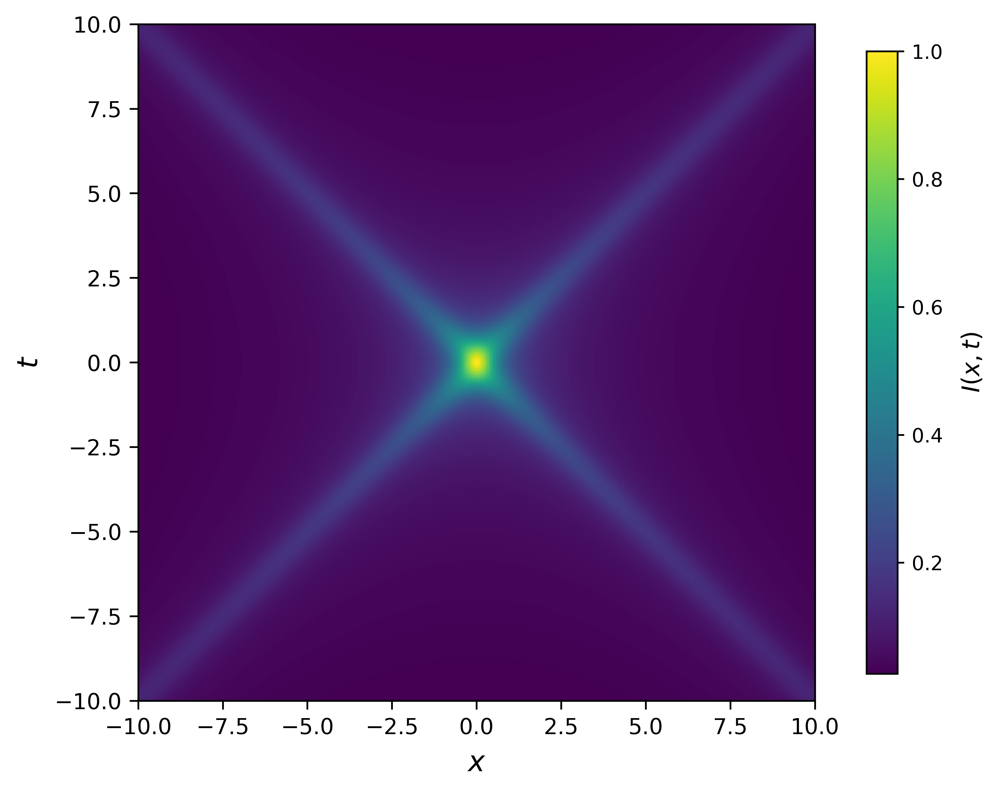

In [229]:
# Mutual-information landscape and detector parameters.
# These settings choose numerical precision and a monotone post-transform. They are part of the
# physical input specification and are saved with the run manifest.
landscape_n_jobs = 1
mathematica_evaluation_backend = "numpy"  # "numpy" or "sympy_high_precision"
mathematica_sympy_precision = 80
mathematica_small_L_cutoff = 1e-5
mutual_information_transform = "normalized_power"
mutual_information_transform_params = {"power": 0.25}
T = [0.15, 0.15]
sigma = [0.15, 0.15]
detector_lambdas = (1.0, 1.0)

# x0 and t0 are physical coordinate axes spanning the same interval. Equal extents make direct
# comparison with x=+/-t meaningful in the rendered and fitted fields.
t0 = np.linspace(-10, 10, num=dimensions[-1])
x0 = np.linspace(-10, 10, num=dimensions[0])
Iparams = [x0, t0, T, sigma]

# Exactly one backend constructs the raw landscape: vectorized double precision for production
# or high-precision SymPy for a slower numerical audit.
if mathematica_evaluation_backend == "numpy":
    Ivalues = compute_mathematica_gapless_ab_landscape(
        x0, t0, T, sigma,
        lambdas=detector_lambdas,
        small_L_cutoff=mathematica_small_L_cutoff,
    )
elif mathematica_evaluation_backend == "sympy_high_precision":
    Ivalues = compute_mathematica_gapless_ab_landscape_sympy(
        x0, t0, T, sigma,
        lambdas=detector_lambdas,
        small_L_cutoff=mathematica_small_L_cutoff,
        precision=mathematica_sympy_precision,
        n_jobs=landscape_n_jobs,
    )
else:
    raise ValueError(f"Unknown Mathematica evaluation backend: {mathematica_evaluation_backend!r}")

# Keep both arrays so the exact source data and the transformed training field
# are independently reproducible.
# The raw detector mutual information is preserved before contrast enhancement. The transformed
# copy supplies the environment while metadata records the monotone mapping.
Ivalues_raw = np.array(Ivalues, dtype=float, copy=True)
Ivalues, mutual_information_transform_metadata = apply_mutual_information_transform(
    Ivalues_raw,
    transform=mutual_information_transform,
    params=mutual_information_transform_params,
)
print(
    "Mutual information backend:", mathematica_evaluation_backend,
    "transform:", mutual_information_transform_metadata["transform"],
    "raw range:", (mutual_information_transform_metadata["raw_min"], mutual_information_transform_metadata["raw_max"]),
    "transformed range:", (mutual_information_transform_metadata["transformed_min"], mutual_information_transform_metadata["transformed_max"]),
)

# objective_values is the scalar field whose maxima define the task. Keeping this name separate
# from Ivalues allows reward construction to be audited without conflating raw and transformed data.
objective_values, qi_objective_parts = quantum_information_objective_values(
    Ivalues,
    env_co,
    normalize_inputs=objective_normalize_inputs,
    return_parts=True,
)
potential_values = None

if len(dimensions) == 2:
    paper_fig2, paper_ax2 = plot_paper_mutual_information_figure(Ivalues, Iparams, figure_size=(6.2, 5.3))
    output_dir = Path("paper_figures")
    output_dir.mkdir(parents=True, exist_ok=True)
    paper_fig2.savefig(output_dir / "mi_landscape.png", dpi=PAPER_SAVE_DPI, bbox_inches="tight", facecolor="white")
    paper_fig2.savefig(output_dir / "mi_landscape.pdf", bbox_inches="tight", facecolor="white")


In [135]:
# This call freezes the visible notebook parameters into a per-agent configuration object. The
# agent deep-copies it so later notebook edits cannot mutate an already trained model.
agent_config = CoordinateFreeLatentSpacetimeAgentConfig(
    coord_dim=len(dimensions),
    latent_dim=latent_dim,
    action_dim=8,  # reset below from the environment action table
    rng_seed=0,  # reset inside the training loop from each supplied agent_seed
    hidden_dims=tuple(hidden_dims),
    encoder_hidden_dims=tuple(encoder_hidden_dims),
    encoder_layernorm_enabled=encoder_layernorm_enabled,
    dynamics_hidden_dims=tuple(dynamics_hidden_dims),
    decoder_hidden_dims=tuple(decoder_hidden_dims),
    decoder_enabled=decoder_enabled,
    reward_hidden_dims=tuple(reward_hidden_dims),
    horizon=planner_horizon,
    max_candidate_sequences=max_candidate_sequences,
    action_selection_method=action_selection_method,
    cem_iterations=cem_iterations,
    cem_population=cem_population,
    cem_elite_frac=cem_elite_frac,
    cem_temperature=cem_temperature,
    cem_training_epsilon_threshold=cem_training_epsilon_threshold,
    cem_eval_cache_enabled=cem_eval_cache_enabled,
    cem_eval_cache_max_size=cem_eval_cache_max_size,
    cem_warm_start_enabled=cem_warm_start_enabled,
    cem_q_bias_enabled=cem_q_bias_enabled,
    cem_q_bias_strength=cem_q_bias_strength,
    cem_horizon1_direct_enabled=cem_horizon1_direct_enabled,
    cem_start_step=cem_start_step,
    q_fallback_on_invalid=q_fallback_on_invalid,
    valid_action_mask_enabled=valid_action_mask_enabled,
    valid_transition_mask_enabled=valid_transition_mask_enabled,
    boundary_loss_mask_enabled=boundary_loss_mask_enabled,
    boundary_loss_mask_margin_cells=boundary_loss_mask_margin_cells,
    gamma=eta,
    lr=lr,
    weight_decay=weight_decay,
    batch_size=batch_size,
    replay_capacity=replay_capacity,
    replay_mode=replay_mode,
    min_replay_episodes=min_replay_episodes,
    min_replay_steps=min_replay_steps,
    updates_per_episode=updates_per_episode,
    episode_replay_update_interval=episode_replay_update_interval,
    updates_per_step=updates_per_step,
    step_replay_update_interval=step_replay_update_interval,
    adaptive_replay_schedule_enabled=adaptive_replay_schedule_enabled,
    adaptive_replay_window=adaptive_replay_window,
    adaptive_replay_min_episodes=adaptive_replay_min_episodes,
    adaptive_replay_success_threshold=adaptive_replay_success_threshold,
    adaptive_replay_step_tolerance=adaptive_replay_step_tolerance,
    adaptive_replay_reward_tolerance=adaptive_replay_reward_tolerance,
    adaptive_replay_error_tolerance=adaptive_replay_error_tolerance,
    adaptive_replay_step_intervals=adaptive_replay_step_intervals,
    adaptive_replay_episode_intervals=adaptive_replay_episode_intervals,
    max_grad_norm=max_grad_norm,
    reward_loss_coeff=reward_loss_coeff,
    reward_predicted_next_training_enabled=reward_predicted_next_training_enabled,
    reward_predicted_next_loss_coeff=reward_predicted_next_loss_coeff,
    reward_predicted_next_detach_dynamics=reward_predicted_next_detach_dynamics,
    reward_loss_type=reward_loss_type,
    reward_huber_delta=reward_huber_delta,
    reward_local_weighting_enabled=reward_local_weighting_enabled,
    reward_local_weighting_mode=reward_local_weighting_mode,
    reward_local_weighting_k=reward_local_weighting_k,
    reward_local_weighting_eps=reward_local_weighting_eps,
    reward_local_weighting_w_min=reward_local_weighting_w_min,
    reward_local_weighting_w_max=reward_local_weighting_w_max,
    reward_local_weighting_strength=reward_local_weighting_strength,
    reward_grid_local_std_window=reward_grid_local_std_window,
    reward_grid_local_std_source=reward_grid_local_std_source,
    reward_error_adaptive_beta=reward_error_adaptive_beta,
    reward_error_adaptive_power=reward_error_adaptive_power,
    dynamics_loss_coeff=dynamics_loss_coeff,
    decoder_reconstruction_coeff=decoder_reconstruction_coeff,
    decoder_dynamics_reconstruction_coeff=decoder_dynamics_reconstruction_coeff,
    decoder_cycle_coeff=decoder_cycle_coeff,
    decoder_output_activation=decoder_output_activation,
    dynamics_boundary_features_enabled=dynamics_boundary_features_enabled,
    dynamics_boundary_feature_dim=dynamics_boundary_feature_dim,
    dynamics_cycle_coeff=dynamics_cycle_coeff,
    dynamics_encoder_consistency_coeff=dynamics_encoder_consistency_coeff,
    encoder_smoothness_coeff=encoder_smoothness_coeff,
    encoder_step_noncollapse_coeff=encoder_step_noncollapse_coeff,
    encoder_min_step_mean=encoder_min_step_mean,
    encoder_min_step_std=encoder_min_step_std,
    compile_enabled=compile_enabled,
    compile_backend=compile_backend,
    compile_mode=compile_mode,
    compile_fullgraph=compile_fullgraph,
    compile_dynamic_shapes=compile_dynamic_shapes,
    compile_cache_root=compile_cache_root,
    compile_use_no_space_cache=compile_use_no_space_cache,
    compile_disable_inductor_pch=compile_disable_inductor_pch,
    compile_warmup_enabled=compile_warmup_enabled,
    compile_warmup_batch_size=compile_warmup_batch_size,
    precompute_grid_context_enabled=precompute_grid_context_enabled,
    diagnostics_cache_enabled=diagnostics_cache_enabled,
)

# NumPy scalars, arrays, paths, and nested containers are converted to portable JSON values so
# the manifest can be inspected without importing the training code.
def _reproducibility_json_value(value):
    """Convert notebook values to lossless-enough JSON metadata without changing training objects."""
    if isinstance(value, pathlib.Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, torch.device):
        return str(value)
    if isinstance(value, dict):
        return {str(key): _reproducibility_json_value(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [_reproducibility_json_value(item) for item in value]
    if isinstance(value, (str, int, float, bool)) or value is None:
        return value
    return repr(value)


def _write_reproducibility_json(path, payload):
    path = pathlib.Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(_reproducibility_json_value(payload), indent=2, sort_keys=True))


def _sync_reproducibility_external():
    """Mirror the run outside the project after each completed checkpoint stage."""
    if (
        reproducibility_run_dir is None
        or reproducibility_external_run_dir is None
        or not reproducibility_external_save_enabled
    ):
        return
    import shutil
    reproducibility_external_run_dir.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(
        reproducibility_run_dir,
        reproducibility_external_run_dir,
        dirs_exist_ok=True,
        copy_function=shutil.copy2,
    )


# A timestamped run directory prevents one experiment from overwriting another. The same artifacts
# are optionally mirrored outside the project tree for independent retention.
reproducibility_run_dir = None
reproducibility_external_run_dir = None
if reproducibility_save_enabled:
    reproducibility_run_id = time.strftime("%Y%m%d_%H%M%S")
    reproducibility_run_dir = pathlib.Path(reproducibility_output_root) / reproducibility_run_id
    reproducibility_run_dir.mkdir(parents=True, exist_ok=False)
    if reproducibility_external_save_enabled:
        reproducibility_external_run_dir = (
            pathlib.Path(reproducibility_external_output_root).expanduser() / reproducibility_run_id
        )

    reproducibility_parameter_names = ['dimensions',
     'start_num',
     'start_curriculum_enabled',
     'start_curriculum_phases',
     'start_curriculum_edge_band_cells',
     'start_curriculum_arm_band_width_cells',
     'start_curriculum_center_exclusion_fraction',
     'num_episodes',
     'max_steps_per_episode',
     'max_reward',
     'rew_pen',
     'rew_bound_pen',
     'terminal_reward_coeff',
     'objective_normalize_inputs',
     'potential_mode',
     'potential_input_transform',
     'shap_co',
     'potential_shaping_delta_coeff',
     'potential_progress_reward_coeff',
     'potential_downhill_penalty_coeff',
     'dense_objective_coeff',
     'dense_objective_mode',
     'dense_objective_schedule_enabled',
     'dense_objective_warmup_episodes',
     'dense_objective_ramp_episodes',
     'dense_objective_baseline',
     'dense_objective_quantile',
     'dense_objective_negative_scale',
     'env_co',
     'latent_dim',
     'hidden_dims',
     'encoder_hidden_dims',
     'dynamics_hidden_dims',
     'decoder_hidden_dims',
     'decoder_enabled',
     'reward_hidden_dims',
     'planner_horizon',
     'max_candidate_sequences',
     'action_selection_method',
     'cem_iterations',
     'cem_population',
     'cem_elite_frac',
     'cem_temperature',
     'cem_training_epsilon_threshold',
     'cem_eval_cache_enabled',
     'cem_eval_cache_max_size',
     'cem_warm_start_enabled',
     'cem_q_bias_enabled',
     'cem_q_bias_strength',
     'cem_horizon1_direct_enabled',
     'cem_start_step',
     'q_fallback_on_invalid',
     'valid_action_mask_enabled',
     'valid_transition_mask_enabled',
     'boundary_loss_mask_enabled',
     'boundary_loss_mask_margin_cells',
     'eta',
     'lr',
     'weight_decay',
     'max_grad_norm',
     'batch_size',
     'replay_capacity',
     'replay_mode',
     'min_replay_episodes',
     'min_replay_steps',
     'updates_per_episode',
     'episode_replay_update_interval',
     'updates_per_step',
     'step_replay_update_interval',
     'adaptive_replay_schedule_enabled',
     'adaptive_replay_window',
     'adaptive_replay_min_episodes',
     'adaptive_replay_success_threshold',
     'adaptive_replay_step_tolerance',
     'adaptive_replay_reward_tolerance',
     'adaptive_replay_error_tolerance',
     'adaptive_replay_step_intervals',
     'adaptive_replay_episode_intervals',
     'reward_loss_coeff',
     'reward_predicted_next_training_enabled',
     'reward_predicted_next_loss_coeff',
     'reward_predicted_next_detach_dynamics',
     'reward_loss_type',
     'reward_huber_delta',
     'reward_local_weighting_enabled',
     'reward_local_weighting_mode',
     'dynamics_loss_coeff',
     'decoder_reconstruction_coeff',
     'decoder_dynamics_reconstruction_coeff',
     'decoder_cycle_coeff',
     'dynamics_cycle_coeff',
     'dynamics_encoder_consistency_coeff',
     'encoder_smoothness_coeff',
     'encoder_step_noncollapse_coeff',
     'encoder_min_step_mean',
     'encoder_min_step_std',
     'dynamics_boundary_features_enabled',
     'dynamics_boundary_feature_dim',
     'decoder_output_activation',
     'compile_enabled',
     'compile_backend',
     'compile_mode',
     'compile_fullgraph',
     'compile_dynamic_shapes',
     'compile_use_no_space_cache',
     'compile_disable_inductor_pch',
     'compile_warmup_enabled',
     'precompute_grid_context_enabled',
     'diagnostics_cache_enabled',
     'latent_numba_enabled',
     'epsilon_start',
     'epsilon_final',
     'epsilon_decay',
     'evaluation_episodes',
     'evaluation_max_steps',
     'evaluation_seed',
     'evaluation_action_selection_method',
     'mutual_information_source',
     'mathematica_evaluation_backend',
     'mathematica_sympy_precision',
     'mathematica_small_L_cutoff',
     'mutual_information_transform',
     'mutual_information_transform_params',
     'T',
     'sigma',
     'detector_lambdas']
    reproducibility_parameters = {
        name: globals()[name] for name in reproducibility_parameter_names if name in globals()
    }
    reproducibility_manifest = {
        "run_id": reproducibility_run_id,
        "notebook": "Latent_Spacetime_Planner_Clean.ipynb",
        "local_run_directory": str(reproducibility_run_dir.resolve()),
        "external_run_directory": (
            str(reproducibility_external_run_dir.resolve())
            if reproducibility_external_run_dir is not None else None
        ),
        "historical_target_metric": {
            "g_tt": -0.9970918190450501,
            "g_tx": 6.011413313513469e-7,
            "g_xx": 1.0,
            "null_slopes_dx_dt": [-0.9985448507713225, 0.9985448507713225],
        },
        "historical_seed_limitation": (
            "The original seed values were generated but not persisted; this run uses the declared "
            "master seed and is exactly reproducible from this point forward."
        ),
        "master_seed": int(reproducibility_master_seed),
        "all_seeds": np.asarray(seeds_q, dtype=np.int64),
        "environment_seeds": env_seed_list_q,
        "agent_seeds": agent_seed_list_q,
        "evaluation_seed": int(evaluation_seed),
        "software": {
            "python": sys.version,
            "torch": torch.__version__,
            "numpy": np.__version__,
            "scipy": scipy.__version__,
            "sympy": sp.__version__,
            "matplotlib": matplotlib.__version__,
        },
        "device": str(device),
        "parameters": reproducibility_parameters,
        "agent_config": vars(agent_config),
    }
    _write_reproducibility_json(reproducibility_run_dir / "manifest.json", reproducibility_manifest)
    np.savez_compressed(
        reproducibility_run_dir / "landscape_and_coordinates.npz",
        Ivalues=np.asarray(Ivalues),
        Ivalues_raw=np.asarray(Ivalues_raw),
        objective_values=np.asarray(objective_values),
        x_axis=np.asarray(Iparams[0]),
        t_axis=np.asarray(Iparams[1]),
    )
    torch.save(
        {
            "python_random_state": random.getstate(),
            "numpy_random_state": np.random.get_state(),
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_states": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        },
        reproducibility_run_dir / "rng_state_before_training.pt",
    )
    _sync_reproducibility_external()
    print("reproducibility artifacts:", reproducibility_run_dir.resolve())
    if reproducibility_external_run_dir is not None:
        print("external reproducibility mirror:", reproducibility_external_run_dir.resolve())


average_reward_list_q = []
average_step_list_q = []
average_policy_list_q = []
average_visit_list_q = []
average_start_list_q = []
training_history_list_q = []
evaluation_results_q = []

# Each loop iteration trains one independent ensemble member. Environment and agent seeds are
# recorded separately because they control different sources of stochastic variation.
for i, agent_seed in enumerate(agent_seed_list_q):
    env_seed = env_seed_list_q[i % len(env_seed_list_q)]
    # The returned policy contains learned weights; histories contain observable learning statistics;
    # visitation and start maps retain where real experience was collected.
    rewards, steps, policy, visit_map, start_map, train_history = train_coordinate_free_latent_spacetime_agent(
        dimensions=dimensions,
        Iparams=Iparams,
        values=Ivalues,
        objective_values=objective_values,
        env_seed=int(env_seed),
        agent_seed=int(agent_seed),
        agent_config=agent_config,
        num_episodes=num_episodes,
        max_steps_per_episode=max_steps_per_episode,
        max_reward=max_reward,
        start_num=start_num,
        start_curriculum_enabled=start_curriculum_enabled,
        start_curriculum_phases=start_curriculum_phases,
        start_curriculum_edge_band_cells=start_curriculum_edge_band_cells,
        start_curriculum_arm_band_width_cells=start_curriculum_arm_band_width_cells,
        start_curriculum_center_exclusion_fraction=start_curriculum_center_exclusion_fraction,
        rew_pen=rew_pen,
        rew_bound_pen=rew_bound_pen,
        terminal_reward_coeff=terminal_reward_coeff,
        print_interval=print_interval,
        epsilon_start=epsilon_start,
        epsilon_final=epsilon_final,
        epsilon_decay=epsilon_decay,
        potential_values=potential_values,
        potential_mode=potential_mode,
        potential_input_transform=potential_input_transform,
        shaping_coeff=shap_co,
        potential_shaping_delta_coeff=potential_shaping_delta_coeff,
        potential_progress_reward_coeff=potential_progress_reward_coeff,
        potential_downhill_penalty_coeff=potential_downhill_penalty_coeff,
        dense_objective_coeff=dense_objective_coeff,
        dense_objective_warmup_episodes=dense_objective_warmup_episodes,
        dense_objective_ramp_episodes=dense_objective_ramp_episodes,
        dense_objective_baseline=dense_objective_baseline,
        dense_objective_quantile=dense_objective_quantile,
        dense_objective_negative_scale=dense_objective_negative_scale,
        dense_objective_mode=dense_objective_mode,
        dense_objective_schedule_enabled=dense_objective_schedule_enabled,
    )
    print(
        f"benchmarking agent {i + 1}/{num_agents_q}: "
        f"{evaluation_episodes} episodes, max {evaluation_max_steps} steps per episode"
    )
    
    average_reward_list_q.append(rewards)
    average_step_list_q.append(steps)
    average_policy_list_q.append(policy)
    average_visit_list_q.append(visit_map)
    average_start_list_q.append(start_map)
    training_history_list_q.append(train_history)
    
    # Benchmarking occurs immediately after each agent trains, before ensemble averaging. This exposes
    # seed failures that an average field could otherwise conceal.
    evaluation_result = evaluate_coordinate_free_policy(
        policy,
        dimensions=dimensions,
        Iparams=Iparams,
        values=Ivalues,
        objective_values=objective_values,
        env_seed=int(env_seed),
        num_episodes=evaluation_episodes,
        max_steps_per_episode=evaluation_max_steps,
        max_reward=max_reward,
        start_num=start_num,
        rew_pen=rew_pen,
        rew_bound_pen=rew_bound_pen,
        terminal_reward_coeff=terminal_reward_coeff,
        epsilon=0.0,
        seed=evaluation_seed,
        reward_context=getattr(policy, "reward_context", None),
        potential_values=potential_values,
        potential_mode=potential_mode,
        potential_input_transform=potential_input_transform,
        shaping_coeff=shap_co,
        potential_shaping_delta_coeff=potential_shaping_delta_coeff,
        potential_progress_reward_coeff=potential_progress_reward_coeff,
        potential_downhill_penalty_coeff=potential_downhill_penalty_coeff,
        dense_objective_coeff=dense_objective_coeff,
        dense_objective_warmup_episodes=dense_objective_warmup_episodes,
        dense_objective_ramp_episodes=dense_objective_ramp_episodes,
        dense_objective_baseline=dense_objective_baseline,
        dense_objective_quantile=dense_objective_quantile,
        dense_objective_negative_scale=dense_objective_negative_scale,
        dense_objective_mode=dense_objective_mode,
        dense_objective_schedule_enabled=dense_objective_schedule_enabled,
        show_progress=evaluation_progress_enabled,
        progress_desc=f"evaluating agent {i + 1}/{num_agents_q}",
        action_selection_method=evaluation_action_selection_method,
    )

    evaluation_results_q.append(evaluation_result)

    if reproducibility_run_dir is not None:
        agent_dir = reproducibility_run_dir / f"agent_{i:02d}"
        agent_dir.mkdir(parents=True, exist_ok=True)
        # A checkpoint stores model/optimizer states, exact seeds, RNG states, configuration, and histories.
        # Together these are the minimum data needed to resume or audit a stochastic training run.
        checkpoint = {
            "agent_index": int(i),
            "environment_seed": int(env_seed),
            "agent_seed": int(agent_seed),
            "evaluation_seed": int(evaluation_seed),
            "model_state_dict": policy.state_dict(),
            "optimizer_state_dict": (
                policy.optimizer.state_dict() if reproducibility_save_optimizer_state else None
            ),
            "agent_config": vars(policy.config),
            "python_random_state": random.getstate(),
            "numpy_random_state": np.random.get_state(),
            "torch_rng_state": torch.get_rng_state(),
            "agent_numpy_rng_state": policy.rng.bit_generator.state,
        }
        torch.save(checkpoint, agent_dir / "checkpoint.pt")
        np.savez_compressed(
            agent_dir / "training_arrays.npz",
            rewards=np.asarray(rewards),
            steps=np.asarray(steps),
            visitation_map=np.asarray(visit_map),
            start_map=np.asarray(start_map),
        )
        _write_reproducibility_json(agent_dir / "training_history.json", train_history)
        _write_reproducibility_json(agent_dir / "evaluation.json", evaluation_result)
        _sync_reproducibility_external()

# The ensemble policy averages the full vector of action scores at each coordinate. Averaging is
# performed after training and does not couple gradients between agents.
avg_policy_q = make_average_policy(average_policy_list_q)

# Per-agent summaries retain the distribution of outcomes. The diagnostic-agent selection below
# is informational; all scientific diagnostic grids are averaged over the full ensemble later.
evaluation_summary_q = []
for agent_index, result in enumerate(evaluation_results_q):
    evaluation_summary_q.append({
        "agent_index": agent_index,
        "success_rate": float(result.get("success_rate", np.nan)),
        "mean_steps": float(result.get("mean_steps", np.nan)),
        "mean_return": float(result.get("mean_return", np.nan)),
        "mean_final_objective": float(result.get("mean_final_objective", np.nan)),
    })

if evaluation_summary_q:
    diagnostic_agent_index = max(
        range(len(evaluation_summary_q)),
        key=lambda idx: (
            evaluation_summary_q[idx]["success_rate"],
            -evaluation_summary_q[idx]["mean_steps"],
            evaluation_summary_q[idx]["mean_return"],
        ),
    )
else:
    diagnostic_agent_index = len(average_policy_list_q) - 1

diagnostic_agent = average_policy_list_q[diagnostic_agent_index]

print("trained agents:", len(average_policy_list_q))
print("per-agent evaluation summary:")
for row in evaluation_summary_q:
    print(row)
if action_selection_method != evaluation_action_selection_method:
    print(
        "evaluation/training action-selection mismatch:",
        {"training": action_selection_method, "evaluation": evaluation_action_selection_method},
    )
print("diagnostic agent index:", diagnostic_agent_index)
print("diagnostic agent last history row:", training_history_list_q[diagnostic_agent_index][-1])
print("diagnostic agent benchmark:", evaluation_results_q[diagnostic_agent_index])

if reproducibility_run_dir is not None:
    _write_reproducibility_json(reproducibility_run_dir / "evaluation_summary.json", evaluation_summary_q)
    torch.save(
        {
            "python_random_state": random.getstate(),
            "numpy_random_state": np.random.get_state(),
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_states": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        },
        reproducibility_run_dir / "rng_state_after_training.pt",
    )
    _sync_reproducibility_external()


reproducibility artifacts: /Users/munga/PycharmProjects/PhD Research/project M/latent_spacetime_reproducibility/20261017_141731
external reproducibility mirror: /Users/munga/latent_spacetime_reproducibility/20261017_141731
reward context numba_used: True numba_status: {'available': True, 'enabled': True, 'import_error': None, 'compiled_helpers': ['_latent_reward_context_grids_numba', '_latent_shaped_reward_components_numba']}
prioritized replay numba_status: {'available': True, 'enabled': True, 'import_error': None, 'compiled_helpers': ['_sum_tree_update_numba', '_min_tree_update_numba', '_sum_tree_find_prefixsum_indices_numba', '_per_update_priorities_numba']}
torch.compile no-space cache dirs: {'TORCHINDUCTOR_CACHE_DIR': '/private/tmp/deepps_torch_compile_munga/inductor', 'TRITON_CACHE_DIR': '/private/tmp/deepps_torch_compile_munga/triton', 'TORCH_EXTENSIONS_DIR': '/private/tmp/deepps_torch_compile_munga/extensions', 'XDG_CACHE_HOME': '/private/tmp/deepps_torch_compile_munga/xdg', 'T

latent planner training:   0%|          | 0/4000 [00:00<?, ?it/s]

benchmarking agent 1/5: 1000 episodes, max 4000 steps per episode


evaluating agent 1/5:   0%|          | 0/1000 [00:00<?, ?it/s]

reward context numba_used: True numba_status: {'available': True, 'enabled': True, 'import_error': None, 'compiled_helpers': ['_latent_reward_context_grids_numba', '_latent_shaped_reward_components_numba']}
prioritized replay numba_status: {'available': True, 'enabled': True, 'import_error': None, 'compiled_helpers': ['_sum_tree_update_numba', '_min_tree_update_numba', '_sum_tree_find_prefixsum_indices_numba', '_per_update_priorities_numba']}
torch.compile no-space cache dirs: {'TORCHINDUCTOR_CACHE_DIR': '/private/tmp/deepps_torch_compile_munga/inductor', 'TRITON_CACHE_DIR': '/private/tmp/deepps_torch_compile_munga/triton', 'TORCH_EXTENSIONS_DIR': '/private/tmp/deepps_torch_compile_munga/extensions', 'XDG_CACHE_HOME': '/private/tmp/deepps_torch_compile_munga/xdg', 'TMPDIR': '/private/tmp/deepps_torch_compile_munga/tmp', 'TEMP': '/private/tmp/deepps_torch_compile_munga/tmp', 'TMP': '/private/tmp/deepps_torch_compile_munga/tmp', 'TORCH_LIB_PATH': '/private/tmp/deepps_torch_compile_munga/

latent planner training:   0%|          | 0/4000 [00:00<?, ?it/s]

benchmarking agent 2/5: 1000 episodes, max 4000 steps per episode


evaluating agent 2/5:   0%|          | 0/1000 [00:00<?, ?it/s]

reward context numba_used: True numba_status: {'available': True, 'enabled': True, 'import_error': None, 'compiled_helpers': ['_latent_reward_context_grids_numba', '_latent_shaped_reward_components_numba']}
prioritized replay numba_status: {'available': True, 'enabled': True, 'import_error': None, 'compiled_helpers': ['_sum_tree_update_numba', '_min_tree_update_numba', '_sum_tree_find_prefixsum_indices_numba', '_per_update_priorities_numba']}
torch.compile no-space cache dirs: {'TORCHINDUCTOR_CACHE_DIR': '/private/tmp/deepps_torch_compile_munga/inductor', 'TRITON_CACHE_DIR': '/private/tmp/deepps_torch_compile_munga/triton', 'TORCH_EXTENSIONS_DIR': '/private/tmp/deepps_torch_compile_munga/extensions', 'XDG_CACHE_HOME': '/private/tmp/deepps_torch_compile_munga/xdg', 'TMPDIR': '/private/tmp/deepps_torch_compile_munga/tmp', 'TEMP': '/private/tmp/deepps_torch_compile_munga/tmp', 'TMP': '/private/tmp/deepps_torch_compile_munga/tmp', 'TORCH_LIB_PATH': '/private/tmp/deepps_torch_compile_munga/

latent planner training:   0%|          | 0/4000 [00:00<?, ?it/s]

benchmarking agent 3/5: 1000 episodes, max 4000 steps per episode


evaluating agent 3/5:   0%|          | 0/1000 [00:00<?, ?it/s]

reward context numba_used: True numba_status: {'available': True, 'enabled': True, 'import_error': None, 'compiled_helpers': ['_latent_reward_context_grids_numba', '_latent_shaped_reward_components_numba']}
prioritized replay numba_status: {'available': True, 'enabled': True, 'import_error': None, 'compiled_helpers': ['_sum_tree_update_numba', '_min_tree_update_numba', '_sum_tree_find_prefixsum_indices_numba', '_per_update_priorities_numba']}
torch.compile no-space cache dirs: {'TORCHINDUCTOR_CACHE_DIR': '/private/tmp/deepps_torch_compile_munga/inductor', 'TRITON_CACHE_DIR': '/private/tmp/deepps_torch_compile_munga/triton', 'TORCH_EXTENSIONS_DIR': '/private/tmp/deepps_torch_compile_munga/extensions', 'XDG_CACHE_HOME': '/private/tmp/deepps_torch_compile_munga/xdg', 'TMPDIR': '/private/tmp/deepps_torch_compile_munga/tmp', 'TEMP': '/private/tmp/deepps_torch_compile_munga/tmp', 'TMP': '/private/tmp/deepps_torch_compile_munga/tmp', 'TORCH_LIB_PATH': '/private/tmp/deepps_torch_compile_munga/

latent planner training:   0%|          | 0/4000 [00:00<?, ?it/s]

benchmarking agent 4/5: 1000 episodes, max 4000 steps per episode


evaluating agent 4/5:   0%|          | 0/1000 [00:00<?, ?it/s]

reward context numba_used: True numba_status: {'available': True, 'enabled': True, 'import_error': None, 'compiled_helpers': ['_latent_reward_context_grids_numba', '_latent_shaped_reward_components_numba']}
prioritized replay numba_status: {'available': True, 'enabled': True, 'import_error': None, 'compiled_helpers': ['_sum_tree_update_numba', '_min_tree_update_numba', '_sum_tree_find_prefixsum_indices_numba', '_per_update_priorities_numba']}
torch.compile no-space cache dirs: {'TORCHINDUCTOR_CACHE_DIR': '/private/tmp/deepps_torch_compile_munga/inductor', 'TRITON_CACHE_DIR': '/private/tmp/deepps_torch_compile_munga/triton', 'TORCH_EXTENSIONS_DIR': '/private/tmp/deepps_torch_compile_munga/extensions', 'XDG_CACHE_HOME': '/private/tmp/deepps_torch_compile_munga/xdg', 'TMPDIR': '/private/tmp/deepps_torch_compile_munga/tmp', 'TEMP': '/private/tmp/deepps_torch_compile_munga/tmp', 'TMP': '/private/tmp/deepps_torch_compile_munga/tmp', 'TORCH_LIB_PATH': '/private/tmp/deepps_torch_compile_munga/

latent planner training:   0%|          | 0/4000 [00:00<?, ?it/s]

benchmarking agent 5/5: 1000 episodes, max 4000 steps per episode


evaluating agent 5/5:   0%|          | 0/1000 [00:00<?, ?it/s]

trained agents: 5
per-agent evaluation summary:
{'agent_index': 0, 'success_rate': 1.0, 'mean_steps': 104.032, 'mean_return': -80.98132430218615, 'mean_final_objective': 1.0}
{'agent_index': 1, 'success_rate': 1.0, 'mean_steps': 103.845, 'mean_return': -75.86893783054579, 'mean_final_objective': 1.0}
{'agent_index': 2, 'success_rate': 1.0, 'mean_steps': 104.58, 'mean_return': -76.38792187121575, 'mean_final_objective': 1.0}
{'agent_index': 3, 'success_rate': 1.0, 'mean_steps': 104.531, 'mean_return': -76.41222660856617, 'mean_final_objective': 1.0}
{'agent_index': 4, 'success_rate': 1.0, 'mean_steps': 102.272, 'mean_return': -74.59689806900774, 'mean_final_objective': 1.0}
diagnostic agent index: 4
diagnostic agent mode: planner
diagnostic agent switch log: []
diagnostic agent last history row: {'episode': 3999, 'episode_return': -122.36351596721971, 'steps': 161, 'success': True, 'epsilon': np.float64(0.10045320181876441), 'mode': 'planner', 'error_ema': 0.003365258493716133, 'env_ret

## Training and Planner Figures

The following cells plot the ensemble learning curves and the averaged planner memory. The action field is derived from averaged action scores, not from averaging integer action labels.


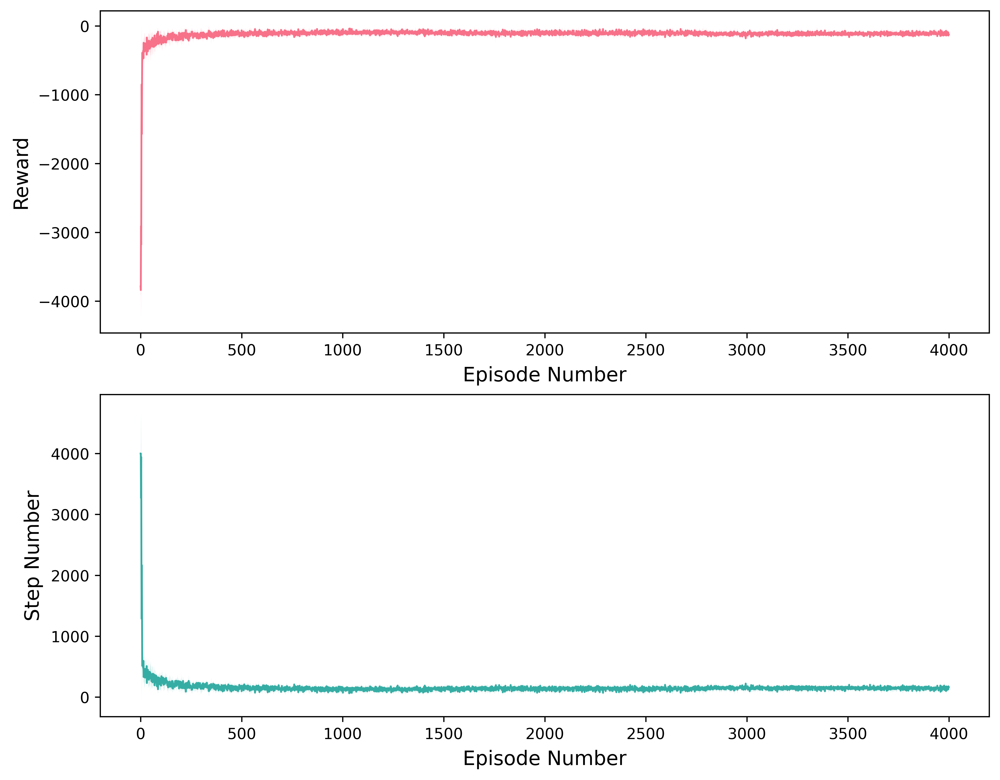

In [230]:
# Ensemble-mean reward and step curves summarize learning dynamics across random seeds. PNG is
# saved at publication DPI and PDF preserves vector text and line geometry.
paper_fig3, paper_ax3 = plot_paper_learning_curves(
    num_episodes, average_reward_list_q, average_step_list_q, figure_size=(9.0, 7.0)
)
output_dir = Path("paper_figures")
output_dir.mkdir(parents=True, exist_ok=True)

paper_fig3.savefig(
    output_dir / "training_curves.png",
    dpi=PAPER_SAVE_DPI,
    bbox_inches="tight",
    facecolor="white",
)
paper_fig3.savefig(
output_dir / "training_curves.pdf",
bbox_inches="tight",
facecolor="white",
)
show_nonpaper_standalone_plots = False


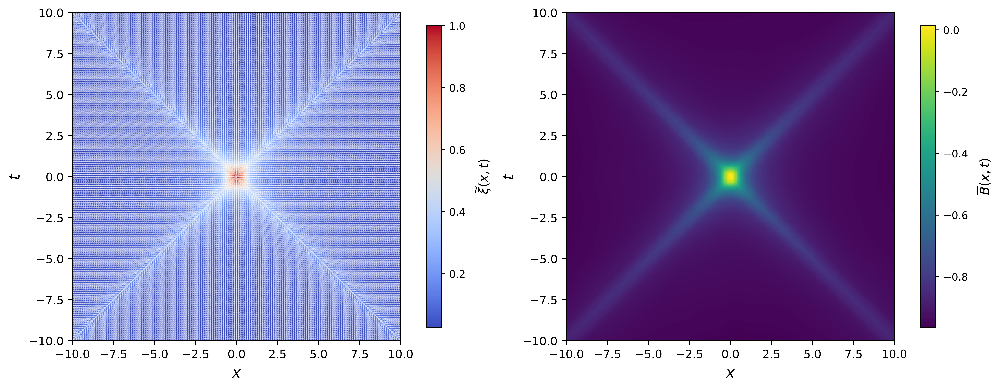

In [231]:
# This grouped figure evaluates the averaged planner over the complete coordinate grid, then
# shows best score, selected direction, and score-derived policy structure on common axes.
paper_fig4, paper_ax4, paper_figure4_data = plot_paper_planner_memory_figure(
    avg_policy_q,
    dimensions,
    Iparams,
    int(env_seed_list_q[-1]),
    max_reward,
    Ivalues,
    start_num,
    rew_pen,
    rew_bound_pen,
    temperature=0.7,
    subsample=2,
    objective_values=objective_values,
    objective_coeff=shap_co,
    objective_normalize_inputs=objective_normalize_inputs,
    figure_size=(12.0, 5.4),
)

output_dir = Path("paper_figures")
output_dir.mkdir(parents=True, exist_ok=True)

paper_fig4.savefig(
    output_dir / "planner_diagnostics.png",
    dpi=PAPER_SAVE_DPI,
    bbox_inches="tight",
    facecolor="white",
)
paper_fig4.savefig(
output_dir / "planner_diagnostics.pdf",
bbox_inches="tight",
facecolor="white",
)


## Averaged Internal-Network Diagnostics

Diagnostics are evaluated separately for every trained agent and then averaged field-by-field. The grouped figures report latent principal components, dynamics accuracy, decoder reconstruction, planner action separation, predicted rewards, and the supplementary component-level diagnostics.


In [ ]:
# The action table links categorical network outputs back to physical grid displacements, which
# is required to interpret an action index as a direction in spacetime.
def _agent_action_dirs(agent):
    """Return the discrete environment action table attached to the trained agent."""
    if getattr(agent, "action_dirs_np", None) is not None:
        return np.asarray(agent.action_dirs_np, dtype=np.int64)
    return np.array([a for a in product([-1, 0, 1], repeat=agent.config.coord_dim) if not all(v == 0 for v in a)], dtype=np.int64)

# PCA rotates the learned d-dimensional cloud onto directions of greatest variance. PC fields
# show dominant organization but their signs and ordering are not physically invariant.
def _latent_principal_components(latent_flat, num_components=2):
    """Compute simple PCA-like coordinates for latent visualization without adding sklearn as a dependency."""
    latent_flat = np.asarray(latent_flat, dtype=float)
    centered = latent_flat - np.nanmean(latent_flat, axis=0, keepdims=True)
    if centered.shape[0] < 2 or centered.shape[1] == 0:
        return np.zeros((centered.shape[0], num_components), dtype=float)
    try:
        _u, _s, vh = np.linalg.svd(centered, full_matrices=False)
        # PCA is computed only for visualization. Planner and losses continue to use the original latent
        # coordinates, so this projection cannot influence training or action selection.
        pcs = centered @ vh[:num_components].T
    except np.linalg.LinAlgError:
        pcs = np.zeros((centered.shape[0], num_components), dtype=float)
    if pcs.shape[1] < num_components:
        pcs = np.pad(pcs, ((0, 0), (0, num_components - pcs.shape[1])), mode="constant")
    return pcs

def _plot_heatmap_grid(panels, Iparams, figure_size=(16, 9), cmap="viridis", title=None):
    """Plot a list of (array, title, colorbar_label, cmap_override) panels over physical spacetime axes."""
    n = len(panels)
    cols = min(3, n)
    rows = int(np.ceil(n / cols))
    x_axis = np.asarray(Iparams[0], dtype=float)
    t_axis = np.asarray(Iparams[1], dtype=float)
    fig, axes = plt.subplots(rows, cols, figsize=figure_size, squeeze=False, constrained_layout=True)
    extent = [x_axis[0], x_axis[-1], t_axis[0], t_axis[-1]]
    for ax, panel in zip(axes.ravel(), panels):
        arr, panel_title, cbar_label, *maybe_cmap = panel
        panel_cmap = maybe_cmap[0] if maybe_cmap else cmap
        im = ax.imshow(arr, extent=extent, origin="lower", aspect="auto", cmap=panel_cmap)
        ax.set_title(panel_title)
        ax.set_xlabel("x")
        ax.set_ylabel("t")
        fig.colorbar(im, ax=ax, label=cbar_label)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    if title:
        fig.suptitle(title)
    return fig, axes

def _diagnostics_cache_key(agent, dimensions, Iparams, batch_size=4096):
    axes = tuple((len(np.asarray(axis)), float(np.asarray(axis)[0]), float(np.asarray(axis)[-1])) for axis in Iparams[:2])
    return (id(agent), int(getattr(agent, "update_count", 0)), tuple(dimensions[:2]), axes, int(batch_size))


# Every active network is evaluated over the same full coordinate grid. Batched inference avoids
# autograd storage and makes comparisons pointwise across encoder, dynamics, decoder, and reward.
def compute_internal_network_diagnostics(agent, dimensions, Iparams, batch_size=4096, use_cache=True):
    """Evaluate active encoder, dynamics, reward, decoder, and planner outputs on the full 2D grid."""
    cache_enabled = bool(use_cache) and bool(getattr(agent.config, "diagnostics_cache_enabled", True))
    cache_key = _diagnostics_cache_key(agent, dimensions, Iparams, batch_size) if cache_enabled else None
    if cache_enabled and cache_key in agent._internal_diagnostics_cache:
        return agent._internal_diagnostics_cache[cache_key]
    previous_training_mode = bool(agent.training)
    agent.eval()
    Nx, Ny = int(dimensions[0]), int(dimensions[1])
    index_grid = np.stack(np.meshgrid(np.arange(Nx), np.arange(Ny), indexing="xy"), axis=-1).reshape(-1, 2)
    states = torch.as_tensor(index_grid, dtype=torch.float32, device=device)
    latent_chunks, q_chunks, decoded_chunks = [], [], []
    with torch.inference_mode():
        for start in range(0, len(index_grid), int(batch_size)):
            state_chunk = states[start:start + int(batch_size)]
            features = agent.coordinate_features(state_chunk)
            z = agent.encode_features(features)
            latent_chunks.append(z.cpu())
            q_chunks.append(agent.action_values(state_chunk).cpu())
            decoded_chunks.append(agent.decode_latent(z).cpu() if agent.config.decoder_enabled else torch.full_like(features.cpu(), np.nan))
    latent_flat = torch.cat(latent_chunks).numpy()
    q_flat = torch.cat(q_chunks).numpy()
    decoded_flat = torch.cat(decoded_chunks).numpy()
    coord_features_flat = agent.coordinate_features(states).detach().cpu().numpy()
    # The best action is argmax Q; the action gap Q_(1)-Q_(2) measures local decisiveness. A small
    # gap marks locations where tiny model changes can switch the selected direction.
    best_action_flat = np.argmax(q_flat, axis=1)
    sorted_q = np.sort(q_flat, axis=1)
    action_gap_flat = sorted_q[:, -1] - sorted_q[:, -2]
    action_dim = int(agent.config.action_dim)
    # Per-action arrays retain information hidden by a mean. They distinguish globally inaccurate
    # dynamics from errors concentrated on the action actually selected by the planner.
    dynamics_error = np.full((len(index_grid), action_dim), np.nan)
    dynamics_step_norm = np.full_like(dynamics_error, np.nan)
    reward_actual = np.full_like(dynamics_error, np.nan)
    reward_predicted = np.full_like(dynamics_error, np.nan)
    decoder_next_actual_error = np.full_like(dynamics_error, np.nan)
    decoder_next_pred_error = np.full_like(dynamics_error, np.nan)
    action_dirs = _agent_action_dirs(agent)
    with torch.inference_mode():
        for action in range(action_dim):
            action_t = torch.full((len(index_grid),), action, dtype=torch.long, device=device)
            coord_now = agent.coordinate_features(states)
            z_now = agent.encode_features(coord_now)
            next_indices = index_grid + action_dirs[action, :2]
            next_indices[:, 0] = np.clip(next_indices[:, 0], 0, Nx - 1)
            next_indices[:, 1] = np.clip(next_indices[:, 1], 0, Ny - 1)
            next_states = torch.as_tensor(next_indices, dtype=torch.float32, device=device)
            coord_next = agent.coordinate_features(next_states)
            z_next_actual = agent.encode_features(coord_next)
            boundary = agent.action_boundary_features(coord_now, action_t)
            # Two next latent states are compared: F(E(c),a) from the learned world model and E(c') from the
            # observed coordinate transition. Their norm is the one-step latent consistency error.
            z_next_pred = agent.latent_dynamics(z_now, action_t, boundary_features=boundary)
            dynamics_error[:, action] = torch.linalg.norm(z_next_pred - z_next_actual, dim=-1).cpu().numpy()
            dynamics_step_norm[:, action] = torch.linalg.norm(z_next_pred - z_now, dim=-1).cpu().numpy()
            reward_actual[:, action] = agent.local_reward_predictor(z_now, z_next_actual, action_t).cpu().numpy()
            reward_predicted[:, action] = agent.local_reward_predictor(z_now, z_next_pred, action_t).cpu().numpy()
            if agent.config.decoder_enabled:
                decoder_next_actual_error[:, action] = torch.linalg.norm(agent.decode_latent(z_next_actual) - coord_next, dim=-1).cpu().numpy()
                decoder_next_pred_error[:, action] = torch.linalg.norm(agent.decode_latent(z_next_pred) - coord_next, dim=-1).cpu().numpy()
    shape = (Ny, Nx)
    q_grid = q_flat.reshape(Ny, Nx, action_dim)
    best_action = best_action_flat.reshape(shape)
    best_expand = best_action[..., None]
    pcs = _latent_principal_components(latent_flat, num_components=2)
    axis0 = np.asarray(Iparams[0], dtype=float)
    axis1 = np.asarray(Iparams[1], dtype=float)
    decoded_physical = np.empty_like(decoded_flat)
    decoded_physical[:, 0] = axis0[0] + decoded_flat[:, 0] * (axis0[-1] - axis0[0])
    decoded_physical[:, 1] = axis1[0] + decoded_flat[:, 1] * (axis1[-1] - axis1[0])
    decoder_reconstruction_error = np.linalg.norm(decoded_flat - coord_features_flat, axis=1).reshape(shape)
    result = {
        "source": "active_networks", "action_dirs": action_dirs.copy(),
        "q_grid": q_grid, "best_q": np.max(q_grid, axis=-1),
        "best_action": best_action, "action_gap": action_gap_flat.reshape(shape),
        "latent_norm": np.linalg.norm(latent_flat, axis=1).reshape(shape),
        "latent_pc1": pcs[:, 0].reshape(shape), "latent_pc2": pcs[:, 1].reshape(shape),
        "dynamics_error_mean": np.nanmean(dynamics_error.reshape(Ny, Nx, action_dim), axis=-1),
        "dynamics_error_best_action": np.take_along_axis(dynamics_error.reshape(Ny, Nx, action_dim), best_expand, axis=-1).squeeze(-1),
        "dynamics_step_norm_mean": np.nanmean(dynamics_step_norm.reshape(Ny, Nx, action_dim), axis=-1),
        "reward_mean": np.nanmean(reward_actual.reshape(Ny, Nx, action_dim), axis=-1),
        "reward_max": np.nanmax(reward_actual.reshape(Ny, Nx, action_dim), axis=-1),
        "reward_best_action": np.take_along_axis(reward_actual.reshape(Ny, Nx, action_dim), best_expand, axis=-1).squeeze(-1),
        "planner_step_reward_best_action": np.take_along_axis(reward_predicted.reshape(Ny, Nx, action_dim), best_expand, axis=-1).squeeze(-1),
        "decoder_x_physical": decoded_physical[:, 0].reshape(shape), "decoder_t_physical": decoded_physical[:, 1].reshape(shape),
        "decoder_reconstruction_error": decoder_reconstruction_error,
        "decoder_next_actual_error_mean": np.nanmean(decoder_next_actual_error.reshape(Ny, Nx, action_dim), axis=-1),
        "decoder_next_pred_error_mean": np.nanmean(decoder_next_pred_error.reshape(Ny, Nx, action_dim), axis=-1),
        "decoder_next_pred_error_best_action": np.take_along_axis(decoder_next_pred_error.reshape(Ny, Nx, action_dim), best_expand, axis=-1).squeeze(-1),
    }
    if cache_enabled:
        agent._put_lru_cache(agent._internal_diagnostics_cache, cache_key, result, 4)
    if previous_training_mode:
        agent.train()
    return result


def plot_planner_output_diagnostics(diagnostics, Iparams, figure_size=(16, 9)):
    panels = [
        (diagnostics["best_q"], "Planner Best Q-Value", r"$\max_a Q(x,t,a)$", "viridis"),
        (diagnostics["best_action"], "Planner Argmax Action", r"$\arg\max_a Q$", "tab20"),
        (diagnostics["action_gap"], "Planner Action Gap", r"$Q_{(1)}-Q_{(2)}$", "magma"),
    ]
    return _plot_heatmap_grid(panels, Iparams, figure_size=figure_size, title="Planner Outputs")

def plot_dynamics_output_diagnostics(diagnostics, Iparams, figure_size=(16, 9)):
    panels = [
        (diagnostics["dynamics_error_mean"], "Mean Dynamics Error", r"mean $||\hat z'-z'||$", "magma"),
        (diagnostics["dynamics_error_best_action"], "Dynamics Error on Planner Action", r"$||\hat z'-z'||$ at $\arg\max Q$", "magma"),
        (diagnostics["dynamics_step_norm_mean"], "Mean Predicted Latent Step Norm", r"mean $||\hat z'-z||$", "viridis"),
    ]
    return _plot_heatmap_grid(panels, Iparams, figure_size=figure_size, title="Dynamics Outputs")

def plot_reward_output_diagnostics(diagnostics, Iparams, figure_size=(16, 9)):
    panels = [
        (diagnostics["reward_mean"], "Local Reward Mean Over Actions", r"mean $\hat r(z,a,z')$", "coolwarm"),
        (diagnostics["reward_max"], "Local Reward Max Over Actions", r"$\max_a \hat r$", "coolwarm"),
        (diagnostics["reward_best_action"], "Local Reward on Planner Action", r"$\hat r$ at $\arg\max Q$", "coolwarm"),
        (diagnostics["planner_step_reward_best_action"], "Planner-Step Reward on Planner Action", r"$\hat r(z,a,\hat z')$", "coolwarm"),
    ]
    return _plot_heatmap_grid(panels, Iparams, figure_size=figure_size, title="Reward Outputs")

def plot_latent_output_diagnostics(diagnostics, Iparams, figure_size=(16, 9)):
    panels = [
        (diagnostics["latent_norm"], "latent norm", r"$||z(x,t)||$", "viridis"),
        (diagnostics["latent_pc1"], "latent PC1", "PC1", "coolwarm"),
        (diagnostics["latent_pc2"], "latent PC2", "PC2", "coolwarm"),
    ]
    return _plot_heatmap_grid(panels, Iparams, figure_size=figure_size, title="Latent Encoder Outputs")

def plot_decoder_output_diagnostics(diagnostics, Iparams, figure_size=(16, 9)):
    panels = [
        (diagnostics["decoder_x_physical"], "Decoded x Coordinate", r"$\hat x = D_x(z)$", "coolwarm"),
        (diagnostics["decoder_t_physical"], "Decoded t Coordinate", r"$\hat t = D_t(z)$", "coolwarm"),
        (diagnostics["decoder_reconstruction_error"], "Current-State Reconstruction Error", r"$||D(z)-c||$", "magma"),
        (diagnostics["decoder_next_actual_error_mean"], "Decoded Observed-Next Error", r"mean $||D(z')-c'||$", "magma"),
        (diagnostics["decoder_next_pred_error_mean"], "Decoded Predicted-Next Error", r"mean $||D(\hat z')-c'||$", "magma"),
        (diagnostics["decoder_next_pred_error_best_action"], "Predicted-Next Error on Planner Action", r"$||D(\hat z')-c'||$ at planner action", "magma"),
    ]
    return _plot_heatmap_grid(panels, Iparams, figure_size=figure_size, title="Latent Decoder Outputs")



def _tighten_paper_grid_layout(fig, h_pad=0.015, hspace=0.015, w_pad=0.025, wspace=0.035):
    """Reduce whitespace in multi-row paper figures without clipping labels or colorbars."""
    layout_engine = fig.get_layout_engine()
    if layout_engine is not None and hasattr(layout_engine, "set"):
        layout_engine.set(h_pad=float(h_pad), hspace=float(hspace), w_pad=float(w_pad), wspace=float(wspace))


def _plot_paper_diagnostic_grid(panels, Iparams, nrows, ncols, figure_size, show=True):
    """Render an ordered paper diagnostic grid with shared square-axis formatting."""
    x_axis = np.asarray(Iparams[0], dtype=float)
    t_axis = np.asarray(Iparams[1], dtype=float)
    extent = [x_axis[0], x_axis[-1], t_axis[0], t_axis[-1]]
    fig, axes = plt.subplots(nrows, ncols, figsize=figure_size, constrained_layout=True, squeeze=False)
    for panel_index, (ax, (values, cmap, image_kwargs, colorbar_ticks)) in enumerate(zip(axes.ravel(), panels)):
        im = ax.imshow(
            np.asarray(values, dtype=float), extent=extent, origin="lower",
            aspect="equal", cmap=cmap, **dict(image_kwargs),
        )
        _style_spacetime_axis(ax)
        colorbar = _add_readable_colorbar(fig, im, ax)
        if colorbar_ticks is not None:
            colorbar.set_ticks(colorbar_ticks)
        ax.text(
            -0.12, 1.025, f"{chr(ord('a') + panel_index)})",
            transform=ax.transAxes, fontsize=PAPER_TITLE_SIZE, fontweight="bold",
            ha="left", va="bottom", clip_on=False,
        )
    _tighten_paper_grid_layout(fig)
    if show:
        plt.show()
    return fig, axes


# The main diagnostic panel groups quantities that test representation scale, dynamics fidelity,
# decoder anchoring, planner confidence, and reward geometry on identical spacetime axes.
def plot_paper_internal_diagnostics(diagnostics, Iparams, figure_size=(12.0, 7.2), show=True):
    """Reproduce the paper's six-panel internal-model diagnostic figure."""
    panels = [
        (diagnostics["latent_pc1"], "coolwarm", {}, None),
        (diagnostics["latent_pc2"], "coolwarm", {}, None),
        (diagnostics["dynamics_error_mean"], "magma", {}, None),
        (diagnostics["decoder_reconstruction_error"], "magma", {}, None),
        (diagnostics["action_gap"], "magma", {}, None),
        (diagnostics["planner_step_reward_best_action"], "coolwarm", {}, None),
    ]
    return _plot_paper_diagnostic_grid(panels, Iparams, 2, 3, figure_size, show=show)


# The supplementary grid exposes component-level outputs so a visually plausible planner surface
# can be checked against the networks that generated it.
def plot_paper_supplementary_diagnostics(diagnostics, Iparams, figure_size=(12.0, 13.5), show=True):
    """Reproduce Appendix Figure 7 using the averaged diagnostics in the paper's exact panel order."""
    action_dirs = np.asarray(diagnostics["action_dirs"])
    num_actions = max(int(action_dirs.shape[0]), int(np.nanmax(diagnostics["best_action"])) + 1)
    panels = [
        (diagnostics["best_action"], plt.get_cmap("tab10", num_actions), {"vmin": -0.5, "vmax": num_actions - 0.5, "interpolation": "nearest"}, np.arange(num_actions)),
        (diagnostics["decoder_x_physical"], "coolwarm", {}, None),
        (diagnostics["decoder_t_physical"], "coolwarm", {}, None),
        (diagnostics["latent_norm"], "viridis", {}, None),
        (diagnostics["dynamics_error_best_action"], "magma", {}, None),
        (diagnostics["dynamics_step_norm_mean"], "viridis", {}, None),
        (diagnostics["decoder_next_actual_error_mean"], "magma", {}, None),
        (diagnostics["decoder_next_pred_error_mean"], "magma", {}, None),
        (diagnostics["decoder_next_pred_error_best_action"], "magma", {}, None),
        (diagnostics["reward_mean"], "coolwarm", {}, None),
        (diagnostics["reward_max"], "coolwarm", {}, None),
        (diagnostics["reward_best_action"], "coolwarm", {}, None),
    ]
    return _plot_paper_diagnostic_grid(panels, Iparams, 4, 3, figure_size, show=show)


## Diagnostic Interpretation

The latent principal components display the dominant spatial variations learned by the encoder; smooth components indicate a coherent coordinate-dependent representation, while collapse would produce nearly constant fields. The latent norm records representation scale and is particularly informative when encoder LayerNorm is disabled.

The dynamics-error panels compare the model-predicted next latent state with the encoding of the observed next coordinate. Low error on the planner-selected action is directly relevant to action choice. The predicted latent-step norm shows the displacement scale produced by the residual dynamics model and reveals either vanishing transitions or abnormally large imagined steps.

Decoder errors test whether encoded and dynamics-predicted latent states remain anchored to physical coordinate observations. Boundary-localized error is expected to be the most difficult regime because clipped transitions differ from interior translations, but broad interior error indicates a representation or dynamics failure.

The reward projections show the learned transition reward averaged over actions, maximized over actions, and evaluated on the planner-selected action. Their agreement with the detector landscape establishes whether the planner score is supported by a learned reward model rather than by an unrelated numerical artifact. The action gap measures separation between the best and second-best planner scores.


In [206]:
# Diagnostics are defined for the ensemble mean. No single seed is allowed to determine the
# reported geometry, even though a representative agent is retained for debugging.
diagnostic_agent_source = "average_policy_list_q_mean"
diagnostic_agent_index = None
diagnostic_agent = None
average_diagnostics_batch_size = 4096
force_recompute_average_internal_diagnostics = False


# Each trained agent is evaluated independently before numeric fields are averaged. This avoids
# constructing a fictitious network whose parameters are an average of differently organized latents.
def average_internal_network_diagnostics(agent_list, dimensions, Iparams, batch_size=4096):
    """Average diagnostic grids over a list of trained agents.

    `avg_policy_q` is a callable that returns averaged action values, not a full agent object.
    The diagnostic routines need encoder/reward/dynamics/decoder methods, so we compute the
    diagnostics for each real agent and average every numeric grid with matching shape.
    """
    diagnostic_list = []
    for agent_index, agent_i in enumerate(agent_list):
        print(f"computing internal diagnostics for averaged policy agent {agent_index + 1}/{len(agent_list)}")
        diagnostic_list.append(
            compute_internal_network_diagnostics(
                agent_i,
                dimensions,
                Iparams,
                batch_size=batch_size,
            )
        )

    averaged = {}
    all_keys = sorted(set().union(*(diag.keys() for diag in diagnostic_list)))
    for key in all_keys:
        values = [diag[key] for diag in diagnostic_list if key in diag]
        numeric_arrays = []
        first_shape = np.asarray(values[0]).shape if values else None
        for value in values:
            arr = np.asarray(value)
            if arr.dtype.kind in "biufc" and arr.shape == first_shape:
                numeric_arrays.append(arr.astype(float, copy=False))
        if len(numeric_arrays) == len(values) and len(numeric_arrays) > 0:
            # Field-wise nanmean computes the empirical ensemble expectation at every grid location. NaNs
            # remain useful for disabled diagnostics rather than being interpreted as physical zeros.
            averaged[key] = np.nanmean(np.stack(numeric_arrays, axis=0), axis=0)
        else:
            averaged[key] = values[0]

    averaged["source"] = "average_policy_list_q_internal_diagnostics"
    averaged["averaged_agent_count"] = int(len(diagnostic_list))
    averaged["batch_size"] = int(batch_size)
    return averaged


def average_internal_diagnostics_cache_key(agent_list, dimensions, Iparams, batch_size=4096):
    """Runtime cache key that invalidates when the trained agents or grid change."""
    iparams_signature = []
    for axis in Iparams[:2]:
        arr = np.asarray(axis, dtype=float).reshape(-1)
        if arr.size:
            iparams_signature.append((int(arr.size), float(arr[0]), float(arr[-1])))
        else:
            iparams_signature.append((0, np.nan, np.nan))
    return (
        tuple(id(agent_i) for agent_i in agent_list),
        tuple(int(v) for v in dimensions[:2]),
        tuple(iparams_signature),
        int(batch_size),
    )


# The cache key includes agent identities, grid geometry, and batch size. Changing any of these
# forces recomputation instead of silently reusing diagnostics from a different experiment.
average_internal_diagnostics_key = average_internal_diagnostics_cache_key(
    average_policy_list_q,
    dimensions,
    Iparams,
    batch_size=average_diagnostics_batch_size,
)

if (
    not bool(force_recompute_average_internal_diagnostics)
    and "internal_diagnostics" in globals()
    and globals().get("internal_diagnostics_cache_key", None) == average_internal_diagnostics_key
):
    print("reusing cached averaged internal diagnostics")
else:
    print("internal diagnostics source policy:", diagnostic_agent_source)
    internal_diagnostics = average_internal_network_diagnostics(
        average_policy_list_q,
        dimensions,
        Iparams,
        batch_size=average_diagnostics_batch_size,
    )
    internal_diagnostics_cache_key = average_internal_diagnostics_key

average_internal_diagnostics = internal_diagnostics
print("average internal diagnostics source:", internal_diagnostics["source"])
print("averaged agent count:", int(internal_diagnostics.get("averaged_agent_count", len(average_policy_list_q))))


if globals().get("reproducibility_run_dir", None) is not None:
    reproducibility_numeric_diagnostics = {
        key: np.asarray(value)
        for key, value in internal_diagnostics.items()
        if isinstance(value, (np.ndarray, np.number, int, float, bool))
    }
    np.savez_compressed(
        reproducibility_run_dir / "average_internal_diagnostics.npz",
        **reproducibility_numeric_diagnostics,
    )
    _write_reproducibility_json(
        reproducibility_run_dir / "average_internal_diagnostics_metadata.json",
        {
            key: value
            for key, value in internal_diagnostics.items()
            if key not in reproducibility_numeric_diagnostics
        },
    )
    _sync_reproducibility_external()


reusing cached averaged internal diagnostics
average internal diagnostics source: average_policy_list_q_internal_diagnostics
averaged agent count: 5


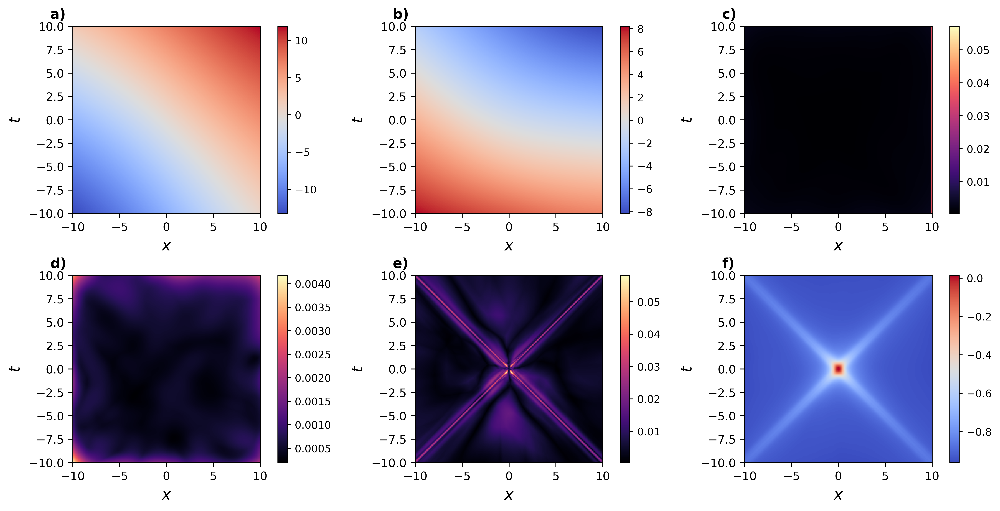

internal diagnostics source: average_policy_list_q_internal_diagnostics
latent norm range: 2.3175063133239746 20.090105056762695
decoder reconstruction error range: 0.0001953118153323885 0.004176882561296225
decoder predicted-next error range: 0.00021526909317799437 0.0039651488623349
dynamics mean error range: 0.0003813371222349815 0.057166755283833484
reward mean range: -0.9989494353532791 -0.027789507620036603
chart displacement norm range: 0.0 0.0


In [232]:
# Plotting requires the averaged diagnostic object from the preceding cell, enforcing a single
# data lineage for all main and appendix panels.
if "internal_diagnostics" not in globals():
    raise ValueError("Averaged internal diagnostics must be computed before plotting.")

output_dir = Path("paper_figures")
output_dir.mkdir(parents=True, exist_ok=True)

# Both raster and vector versions are saved from the same figure objects. Printed ranges provide
# quick numerical scale checks alongside visual inspection.
paper_fig5, paper_ax5 = plot_paper_internal_diagnostics(
    internal_diagnostics, Iparams, figure_size=(12.0, 6.0)
)
paper_fig5.savefig(output_dir / "internal_diagnostics_main_2x3.png", dpi=PAPER_SAVE_DPI, bbox_inches="tight", facecolor="white")
paper_fig5.savefig(output_dir / "internal_diagnostics_main_2x3.pdf", bbox_inches="tight", facecolor="white")

paper_fig7, paper_ax7 = plot_paper_supplementary_diagnostics(
    internal_diagnostics, Iparams, figure_size=(12.0, 12.0)
)
paper_fig7.savefig(output_dir / "internal_diagnostics_appendix.png", dpi=PAPER_SAVE_DPI, bbox_inches="tight", facecolor="white")
paper_fig7.savefig(output_dir / "internal_diagnostics_appendix.pdf", bbox_inches="tight", facecolor="white")

print("internal diagnostics source:", internal_diagnostics["source"])
print("latent norm range:", float(np.nanmin(internal_diagnostics["latent_norm"])), float(np.nanmax(internal_diagnostics["latent_norm"])))
print("decoder reconstruction error range:", float(np.nanmin(internal_diagnostics["decoder_reconstruction_error"])), float(np.nanmax(internal_diagnostics["decoder_reconstruction_error"])))
print("decoder predicted-next error range:", float(np.nanmin(internal_diagnostics["decoder_next_pred_error_mean"])), float(np.nanmax(internal_diagnostics["decoder_next_pred_error_mean"])))
print("dynamics mean error range:", float(np.nanmin(internal_diagnostics["dynamics_error_mean"])), float(np.nanmax(internal_diagnostics["dynamics_error_mean"])))
print("reward mean range:", float(np.nanmin(internal_diagnostics["reward_mean"])), float(np.nanmax(internal_diagnostics["reward_mean"])))


## Neighbour-Mask Metric Recovery

The metric diagnostic begins with the averaged planner-score field (or the selected reward projection). A grid cell enters the ridge mask when its value exceeds the configured fraction of neighbouring values. Branch extraction identifies one ridge location per connected row segment, optionally using subpixel interpolation or a geometric hyperbola filter. The extracted displacements relative to the detector centre are fitted to

\[
g_{tt}\,\Delta t^2 + 2g_{tx}\,\Delta t\Delta x + g_{xx}\,\Delta x^2 = 0,
\]

with the conformal convention \(g_{xx}=1\). The resulting \(g_{tt}\) and \(g_{tx}\) determine the two fitted null slopes.


planner-neighbour mask source grid: planner_softmax_average
planner-neighbour softmax beta: 2.0
planner-neighbour hyperbola filter metadata: {'enabled': False, 'mode': 'hard'}
planner-neighbour metric fit metadata: {'mode': 'legacy_unweighted_quadratic', 'iterations': 1, 'point_count': 505, 'residual_rmse': 0.11668354900549102}
planner-neighbour mask metric components: {'g_tt': -0.9998780957794325, 'g_tx': 7.786653464611928e-08, 'g_xx': 1.0}
planner-neighbour mask metric tensor [[g_tt, g_tx], [g_tx, g_xx]]:
[[-9.99878096e-01  7.78665346e-08]
 [ 7.78665346e-08  1.00000000e+00]]


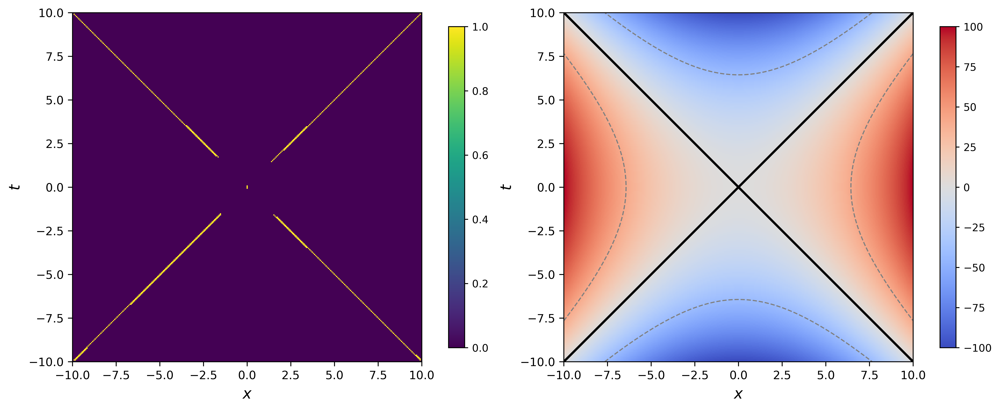

In [233]:
# Optional Gaussian smoothing suppresses pixel-scale noise before branch extraction. Sigma zero
# leaves the learned field exactly unchanged and is the active setting below.
def _smooth_grid_2d(values, sigma=0.0):
    """Apply optional Gaussian smoothing before extracting connected ridge branches."""
    array = np.asarray(values, dtype=float)
    if float(sigma) <= 0.0:
        return array
    try:
        from scipy.ndimage import gaussian_filter
        return gaussian_filter(array, sigma=float(sigma), mode="nearest")
    except Exception:
        # Branch extraction remains usable when SciPy is unavailable; sigma then has no effect.
        return array


# The default origin is the midpoint of the sampled physical axes, matching the coincident-detector
# event for symmetric coordinate ranges without fitting the center to a desired slope.
def _lightcone_metric_default_center(Iparams):
    x_axis = np.asarray(Iparams[0], dtype=float)
    t_axis = np.asarray(Iparams[1], dtype=float)
    cx = 0.0 if np.nanmin(x_axis) <= 0.0 <= np.nanmax(x_axis) else 0.5 * (float(x_axis[0]) + float(x_axis[-1]))
    ct = 0.0 if np.nanmin(t_axis) <= 0.0 <= np.nanmax(t_axis) else 0.5 * (float(t_axis[0]) + float(t_axis[-1]))
    return float(cx), float(ct)


def _smooth_array_1d(values, sigma=0.0):
    arr = np.asarray(values, dtype=float)
    if float(sigma) <= 0.0 or arr.size < 3:
        return arr
    try:
        from scipy.ndimage import gaussian_filter1d
        return gaussian_filter1d(arr, sigma=float(sigma), mode="nearest")
    except Exception:
        return arr


# A parabola through three neighbouring samples estimates a ridge maximum between grid points.
# This reduces lattice quantization while imposing no preferred lightcone slope.
def _quadratic_subpixel_peak(x_vals, y_vals):
    x = np.asarray(x_vals, dtype=float)
    y = np.asarray(y_vals, dtype=float)
    if x.size != 3 or y.size != 3 or not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
        return None
    try:
        a, b, _c = np.polyfit(x, y, deg=2)
    except Exception:
        return None
    if not np.isfinite(a) or abs(a) <= 1e-12:
        return None
    peak = -b / (2.0 * a)
    if peak < min(x) or peak > max(x):
        return None
    return float(peak)


def _contiguous_true_runs(mask):
    mask = np.asarray(mask, dtype=bool)
    if mask.size == 0:
        return []
    padded = np.pad(mask.astype(np.int8), (1, 1), constant_values=0)
    changes = np.diff(padded)
    starts = np.flatnonzero(changes == 1)
    stops = np.flatnonzero(changes == -1)
    return [np.arange(start, stop, dtype=int) for start, stop in zip(starts, stops)]


# Connected above-threshold runs are scored independently so parallel artifacts do not merge into
# one centroid. Peak, centroid, or subpixel modes then assign one x coordinate to the chosen run.
def _ridge_center_for_row(row, candidate_indices, x_axis, threshold, center_mode=None):
    if len(candidate_indices) == 0:
        return None
    local_values = np.asarray(row[candidate_indices], dtype=float)
    finite = np.isfinite(local_values)
    active = finite & (local_values >= float(threshold))
    if not np.any(active):
        return None
    best = None
    best_score = -np.inf
    for run_local in _contiguous_true_runs(active):
        idx = np.asarray(candidate_indices, dtype=int)[run_local]
        vals = np.asarray(row[idx], dtype=float)
        vals = np.clip(vals, 0.0, None)
        score = float(np.nansum(vals))
        if not np.isfinite(score) or score <= 0.0:
            continue
        peak_idx = int(idx[int(np.nanargmax(vals))])
        if 0 < peak_idx < len(row) - 1:
            q_peak = _quadratic_subpixel_peak(x_axis[peak_idx - 1:peak_idx + 2], row[peak_idx - 1:peak_idx + 2])
        else:
            q_peak = None
        centroid = float(np.average(x_axis[idx], weights=np.maximum(vals, 1e-12)))
        peak_x = float(x_axis[peak_idx])
        if center_mode is None:
            center_mode = globals().get("planner_quadratic_ridge_center_mode", "subpixel_peak")
        center_mode = str(center_mode).lower().replace("-", "_")
        if center_mode in ("subpixel", "subpixel_peak", "peak"):
            x_center = float(q_peak) if q_peak is not None and center_mode != "peak" else peak_x
        elif center_mode in ("centroid", "weighted_centroid"):
            x_center = centroid
        else:
            x_center = float(0.5 * centroid + 0.5 * q_peak) if q_peak is not None else centroid
        peak_prob = float(np.nanmax(vals))
        rank_score = score * np.sqrt(max(len(idx), 1))
        if rank_score > best_score:
            best_score = rank_score
            best = (x_center, peak_prob, int(peak_idx), int(len(idx)), score)
    return best


# Rows above and below the center are split again into left and right half-planes, producing four
# candidate null branches. Extraction uses observed ridge strength rather than x=+/-t labels.
def extract_lightcone_branches(probability_grid, Iparams, center=None, threshold_quantile=0.80, min_probability=None,
                               min_time_separation=0.0, smooth_sigma=1.0, branch_smooth_sigma=1.0,
                               ridge_center_mode=None):
    """Extract left and right null-ridge branches from the planner-derived near-null probability field.

    The input is a planner-derived local-prominence field whose high values identify candidate
    null ridges. The returned physical branch coordinates are the observations used by the
    quadratic Lorentzian fit below.
    """
    prob_raw = np.asarray(probability_grid, dtype=float)
    prob = _smooth_grid_2d(prob_raw, sigma=smooth_sigma)
    x_axis = np.asarray(Iparams[0], dtype=float)
    t_axis = np.asarray(Iparams[1], dtype=float)
    if prob.shape != (len(t_axis), len(x_axis)):
        raise ValueError(f"probability_grid must have shape {(len(t_axis), len(x_axis))}, got {prob.shape}.")
    if center is None:
        center = _lightcone_metric_default_center(Iparams)
    cx, ct = float(center[0]), float(center[1])
    finite = prob[np.isfinite(prob)]
    if finite.size == 0:
        raise ValueError("No finite planner near-null probabilities are available.")
    threshold = float(np.nanquantile(finite, float(threshold_quantile)))
    if min_probability is not None:
        threshold = max(threshold, float(min_probability))

    branches = {"left": [], "right": []}
    support = np.isfinite(prob) & (prob >= threshold)
    left_indices = np.flatnonzero(x_axis < cx)
    right_indices = np.flatnonzero(x_axis > cx)
    side_indices = {"left": left_indices, "right": right_indices}
    # Each quadrant is processed separately. This prevents a stronger arm from pulling the estimated
    # location of its opposite arm through a global centroid.
    for y, t_val in enumerate(t_axis):
        if abs(float(t_val) - ct) <= float(min_time_separation):
            continue
        row = prob[y]
        for side, indices in side_indices.items():
            if indices.size == 0:
                continue
            active_indices = indices[support[y, indices]]
            center_info = _ridge_center_for_row(row, active_indices, x_axis, threshold, center_mode=ridge_center_mode)
            if center_info is None:
                continue
            x_center, peak_prob, peak_idx, width, mass = center_info
            branches[side].append((
                y,
                float(t_val),
                float(x_center),
                float(peak_prob),
                float(width),
                float(mass),
                float(x_axis[peak_idx]),
            ))

    velocity_by_row = {"left": {}, "right": {}}
    branch_arrays = {}
    raw_branch_arrays = {}
    for side, rows in branches.items():
        arr = np.asarray(rows, dtype=float)
        raw_branch_arrays[side] = arr.copy()
        branch_arrays[side] = arr
        if arr.ndim == 2 and arr.shape[0] >= 2:
            row_ids = arr[:, 0].astype(int)
            t_vals = arr[:, 1]
            x_vals = _smooth_array_1d(arr[:, 2], sigma=branch_smooth_sigma)
            arr = arr.copy()
            arr[:, 2] = x_vals
            branch_arrays[side] = arr
            velocities = np.gradient(x_vals, t_vals, edge_order=1)
            velocities = _smooth_array_1d(velocities, sigma=max(float(branch_smooth_sigma) * 0.5, 0.0))
            velocity_by_row[side] = {int(row): float(v) for row, v in zip(row_ids, velocities)}

    return {
        "probability_grid": prob_raw,
        "smoothed_probability_grid": prob,
        "Iparams": [x_axis, t_axis],
        "center": (cx, ct),
        "threshold": threshold,
        "branches": branch_arrays,
        "raw_branches": raw_branch_arrays,
        "velocity_by_row": velocity_by_row,
        "branch_columns": ("row", "t", "x", "peak_probability", "segment_width", "segment_mass", "peak_x"),
    }


# For displacement y=(dt,dx), the fitted scalar is y^T g y = g_tt dt^2 + 2 g_tx dt dx
# + g_xx dx^2. Its zero contour is the recovered pair of null directions.
def quadratic_form_grid(fit_result, Iparams=None):
    if Iparams is None:
        Iparams = fit_result["Iparams"]
    x_axis = np.asarray(Iparams[0], dtype=float)
    t_axis = np.asarray(Iparams[1], dtype=float)
    cx, ct = fit_result["center"]
    G = np.asarray(fit_result["quadratic_metric"], dtype=float)
    dt = t_axis[:, None] - ct
    dx = x_axis[None, :] - cx
    q_grid = G[0, 0] * dt ** 2 + 2.0 * G[0, 1] * dt * dx + G[1, 1] * dx ** 2
    return q_grid


# Fixing g_xx=1 chooses the otherwise undetermined conformal scale. The branch points then provide
# a linear least-squares problem for g_tt and g_tx.
def _fit_planner_neighbor_metric_coefficients(
    dt,
    dx,
    gxx=1.0,
    balanced_robust_slope_fit_enabled=False,
    robust_iterations=20,
    robust_cutoff=1.5,
    robust_scale_floor_fraction=0.05,
):
    """Fit (g_tt, g_tx) either with the legacy quadratic fit or a balanced robust slope fit.

    The optional slope fit divides the null condition by dt**2 and fits
    g_tt + 2*g_tx*(dx/dt) = -g_xx*(dx/dt)**2. Each populated (sign(dt),
    sign(dx)) quadrant receives equal total base weight, after which Huber IRLS
    suppresses branch-extraction outliers without imposing a target metric.
    """
    dt = np.asarray(dt, dtype=float).reshape(-1)
    dx = np.asarray(dx, dtype=float).reshape(-1)
    valid = np.isfinite(dt) & np.isfinite(dx) & (np.abs(dt) > 0.0)
    dt = dt[valid]
    dx = dx[valid]
    if dt.size < 4:
        raise ValueError(f"Need at least four finite nonzero-dt branch points; got {dt.size}.")

    if not bool(balanced_robust_slope_fit_enabled):
        # Each row encodes g_tt dt^2 + 2 g_tx dt dx = -g_xx dx^2. Solving all rows finds the quadratic
        # form whose null contour best passes through the extracted ridges.
        design = np.column_stack([dt ** 2, 2.0 * dt * dx])
        target = -float(gxx) * dx ** 2
        coeff, *_ = np.linalg.lstsq(design, target, rcond=1e-15)
        residual = design @ coeff - target
        weights = np.ones(dt.size, dtype=float)
        return coeff, weights, {
            "mode": "legacy_unweighted_quadratic",
            "iterations": 1,
            "point_count": int(dt.size),
            "residual_rmse": float(np.sqrt(np.mean(residual ** 2))),
        }

    # The robust option divides by dt^2 and fits in null-slope space. Equal total weight per quadrant
    # prevents a longer or more densely sampled branch from dominating the metric.
    slope = dx / dt
    design = np.column_stack([np.ones_like(slope), 2.0 * slope])
    target = -float(gxx) * slope ** 2
    quadrant = (dt >= 0.0).astype(np.int8) * 2 + (dx >= 0.0).astype(np.int8)
    quadrant_counts = {int(q): int(np.count_nonzero(quadrant == q)) for q in np.unique(quadrant)}
    base_weights = np.zeros(dt.size, dtype=float)
    for q, count in quadrant_counts.items():
        if count > 0:
            base_weights[quadrant == q] = 1.0 / float(count)
    base_weights *= float(dt.size) / max(float(np.sum(base_weights)), 1e-12)

    def _weighted_fit(weights):
        sqrt_w = np.sqrt(np.maximum(np.asarray(weights, dtype=float), 0.0))
        return np.linalg.lstsq(design * sqrt_w[:, None], target * sqrt_w, rcond=1e-15)[0]

    coeff = _weighted_fit(base_weights)
    weights = base_weights.copy()
    robust_scale = 0.0
    completed_iterations = 0
    for iteration in range(max(0, int(robust_iterations))):
        residual = design @ coeff - target
        residual_center = float(np.median(residual))
        residual_rms = float(np.sqrt(np.mean(residual ** 2)))
        robust_scale = 1.4826 * float(np.median(np.abs(residual - residual_center)))
        # A binary grid can place most points exactly on x=+/-t, making MAD almost zero.
        # Keep a small RMS-relative floor so IRLS does not treat all genuine sub-grid variation as an outlier.
        robust_scale = max(
            robust_scale if np.isfinite(robust_scale) else 0.0,
            max(float(robust_scale_floor_fraction), 0.0) * residual_rms,
            1e-12,
        )
        cutoff = max(float(robust_cutoff), 1e-6) * robust_scale
        robust_weights = np.minimum(1.0, cutoff / np.maximum(np.abs(residual), 1e-12))
        weights = base_weights * robust_weights
        next_coeff = _weighted_fit(weights)
        completed_iterations = iteration + 1
        if np.allclose(next_coeff, coeff, rtol=1e-10, atol=1e-12):
            coeff = next_coeff
            break
        coeff = next_coeff

    residual = design @ coeff - target
    effective_n = float(np.sum(weights) ** 2 / max(float(np.sum(weights ** 2)), 1e-12))
    return coeff, weights, {
        "mode": "quadrant_balanced_huber_slope",
        "iterations": int(completed_iterations),
        "point_count": int(dt.size),
        "effective_point_count": effective_n,
        "robust_scale": float(robust_scale),
        "residual_rmse": float(np.sqrt(np.mean(residual ** 2))),
        "quadrant_counts": {str(q): count for q, count in quadrant_counts.items()},
    }


paper_show_neighbor_intermediate_diagnostics = False  # True restores the extra notebook-only mask/source figures.
# These switches choose the learned scalar field and extraction behavior. They alter the diagnostic
# only; they are not read by training and cannot force the learned planner toward Minkowski values.
planner_neighbor_value_source = "planner_softmax_average"  # "planner", "planner_softmax_average", or "reward_model".
planner_neighbor_reward_grid_key = "reward_best_action"  # Other valid reward-model choices include "reward_mean" and "reward_best_action".
planner_neighbor_softmax_beta = 2.0  # Higher beta makes the softmax average closer to best_q; lower beta averages more actions.
planner_neighbor_metric_percentage = 0.7
planner_neighbor_metric_gxx = 1.0
planner_neighbor_metric_min_time_separation = 0.0#globals().get("lightcone_quadratic_min_time_separation", 0.0)
# Optional robust estimator. False reproduces the previous unweighted quadratic least-squares fit.
planner_neighbor_balanced_robust_slope_fit_enabled = False
planner_neighbor_robust_iterations = 40
planner_neighbor_robust_cutoff = 0.5  # Huber cutoff in robust residual-scale units.
planner_neighbor_robust_scale_floor_fraction = 0.05  # Prevents a zero MAD on lattice-aligned ridges.
planner_neighbor_radius = 1
# Ridge location within each selected row segment: "subpixel_peak", "peak", "centroid", or "hybrid".
planner_neighbor_ridge_center_mode = "peak"#"centroid"#"subpixel_peak"
# Boundary-neighbour handling: any numpy.pad mode, or None/"none"/"off" to reject incomplete edge windows.
planner_neighbor_edge_mode = "none"#"reflect"#"none"

# Optional second-stage geometric filter. The raw neighbour mask detects local ridges; this filter keeps
# ridge points whose two-focus distance differences are internally consistent with a hyperbola family.
planner_neighbor_hyperbola_filter_enabled = False
planner_neighbor_hyperbola_filter_mode = "hard"  # "soft" weights the mask; "hard" keeps/removes points.
planner_neighbor_hyperbola_focus_fraction = 1.0  # Focus offset as a fraction of the smaller x/t span.
planner_neighbor_hyperbola_tolerance_multiplier = 1.3  # Robust MAD multiplier used for least-biased tolerance.
planner_neighbor_hyperbola_min_tolerance_cells = 0.5  # Prevents zero tolerance on very crisp masks.
planner_neighbor_hyperbola_soft_power = 5.0  # Larger values sharpen the soft filter.

# The selected source is converted to one scalar value per coordinate. Softmax averaging retains
# information from all actions while emphasizing larger planner scores.
planner_neighbor_source_key = str(planner_neighbor_value_source).lower().replace("-", "_")
if planner_neighbor_source_key in ("planner", "planner_output", "best_q", "q", "q_value"):
    planner_neighbor_grid_key = "best_q"
    planner_neighbor_title = "Planner Best Q-Value"
    planner_output_value_grid = np.asarray(internal_diagnostics[planner_neighbor_grid_key], dtype=float)
elif planner_neighbor_source_key in ("planner_softmax", "planner_softmax_average", "softmax_average", "softmax_q", "soft_q"):
    planner_neighbor_grid_key = "planner_softmax_average"
    planner_neighbor_title = "Planner Softmax Average Q-Value"
    planner_neighbor_q_grid = np.asarray(internal_diagnostics["q_grid"], dtype=float)
    planner_neighbor_finite_q = np.isfinite(planner_neighbor_q_grid)
    planner_neighbor_q_safe = np.where(planner_neighbor_finite_q, planner_neighbor_q_grid, -np.inf)
    planner_neighbor_q_shifted = planner_neighbor_q_safe - np.nanmax(planner_neighbor_q_safe, axis=-1, keepdims=True)
    # Subtracting the per-cell maximum is the standard stable softmax identity. Beta controls how
    # closely the weighted mean approaches max_a Q without changing action-score ordering.
    planner_neighbor_softmax_weights = np.exp(float(planner_neighbor_softmax_beta) * planner_neighbor_q_shifted)
    planner_neighbor_softmax_weights = np.where(planner_neighbor_finite_q, planner_neighbor_softmax_weights, 0.0)
    planner_neighbor_softmax_weights = planner_neighbor_softmax_weights / np.maximum(
        np.sum(planner_neighbor_softmax_weights, axis=-1, keepdims=True),
        1e-12,
    )
    planner_output_value_grid = np.sum(planner_neighbor_softmax_weights * np.nan_to_num(planner_neighbor_q_grid, nan=0.0), axis=-1)
elif planner_neighbor_source_key in ("reward", "reward_model", "local_reward", "reward_head"):
    planner_neighbor_grid_key = str(planner_neighbor_reward_grid_key)
    planner_neighbor_title = "Reward Model Output"
    if planner_neighbor_grid_key not in internal_diagnostics:
        raise KeyError(f"internal_diagnostics does not contain {planner_neighbor_grid_key!r} for planner_neighbor_value_source={planner_neighbor_value_source!r}.")
    planner_output_value_grid = np.asarray(internal_diagnostics[planner_neighbor_grid_key], dtype=float)
else:
    planner_neighbor_grid_key = str(planner_neighbor_value_source)
    if planner_neighbor_grid_key not in internal_diagnostics:
        raise KeyError(f"internal_diagnostics does not contain {planner_neighbor_grid_key!r} for planner_neighbor_value_source={planner_neighbor_value_source!r}.")
    planner_output_value_grid = np.asarray(internal_diagnostics[planner_neighbor_grid_key], dtype=float)
Ny_neighbor, Nx_neighbor = planner_output_value_grid.shape
planner_neighbor_mask_grid = np.zeros_like(planner_output_value_grid, dtype=float)

planner_neighbor_radius = int(planner_neighbor_radius)
planner_neighbor_window_size = 2 * planner_neighbor_radius + 1
planner_neighbor_center_flat_index = (planner_neighbor_window_size * planner_neighbor_window_size) // 2
planner_neighbor_expected_count = planner_neighbor_window_size * planner_neighbor_window_size - 1
planner_neighbor_edge_mode_key = (
    "none"
    if planner_neighbor_edge_mode is None
    else str(planner_neighbor_edge_mode).lower().replace("-", "_")
)
if planner_neighbor_edge_mode_key in ("none", "off", "disabled"):
    # NaN padding contributes no artificial neighbours. The full-neighbour-count check below
    # consequently rejects every point whose comparison window crosses the grid boundary.
    planner_neighbor_padded_grid = np.pad(
        planner_output_value_grid,
        pad_width=planner_neighbor_radius,
        mode="constant",
        constant_values=np.nan,
    )
else:
    planner_neighbor_padded_grid = np.pad(
        planner_output_value_grid,
        pad_width=planner_neighbor_radius,
        mode=str(planner_neighbor_edge_mode),
    )

# A cell enters the binary ridge mask when the configured fraction of its finite neighbours have
# smaller values. This is a local prominence test, not a threshold on absolute score magnitude.
for iy in range(Ny_neighbor):
    for ix in range(Nx_neighbor):
        center_value = planner_output_value_grid[iy, ix]
        if not np.isfinite(center_value):
            continue
        y0 = iy
        y1 = iy + planner_neighbor_window_size
        x0 = ix
        x1 = ix + planner_neighbor_window_size
        neighbors = planner_neighbor_padded_grid[y0:y1, x0:x1].reshape(-1)
        keep = np.ones(neighbors.shape[0], dtype=bool)
        keep[planner_neighbor_center_flat_index] = False
        neighbors = neighbors[keep]
        neighbors = neighbors[np.isfinite(neighbors)]
        if neighbors.size < planner_neighbor_expected_count:
            continue
        smaller_fraction = float(np.size(neighbors[neighbors < center_value]) / np.size(neighbors))
        #smaller_fraction = float(np.mean(neighbors < center_value))
        planner_neighbor_mask_grid[iy, ix] = 1.0 if smaller_fraction >= float(planner_neighbor_metric_percentage) else 0.0

planner_neighbor_exclude_boundary_cells = 0
if planner_neighbor_exclude_boundary_cells > 0:
    b = planner_neighbor_exclude_boundary_cells
    planner_neighbor_mask_grid[:b, :] = 0.0
    planner_neighbor_mask_grid[-b:, :] = 0.0
    planner_neighbor_mask_grid[:, :b] = 0.0
    planner_neighbor_mask_grid[:, -b:] = 0.0

planner_neighbor_x_axis = np.asarray(Iparams[0], dtype=float)
planner_neighbor_t_axis = np.asarray(Iparams[1], dtype=float)
planner_neighbor_extent = [
    float(planner_neighbor_x_axis[0]),
    float(planner_neighbor_x_axis[-1]),
    float(planner_neighbor_t_axis[0]),
    float(planner_neighbor_t_axis[-1]),
]

# The raw mask is retained before optional geometric filtering so any improvement or bias introduced
# by the second stage remains directly inspectable.
planner_neighbor_raw_mask_grid = planner_neighbor_mask_grid.copy()
planner_neighbor_hyperbola_filter_grid = np.ones_like(planner_neighbor_mask_grid, dtype=float)
planner_neighbor_hyperbola_metadata = {
    "enabled": bool(planner_neighbor_hyperbola_filter_enabled),
    "mode": str(planner_neighbor_hyperbola_filter_mode),
}

# The optional filter uses constant differences of distances to symmetric foci, the defining
# property of hyperbolas. Medians and MAD-derived tolerances are estimated from the mask itself.
if bool(planner_neighbor_hyperbola_filter_enabled):
    planner_neighbor_X, planner_neighbor_T = np.meshgrid(planner_neighbor_x_axis, planner_neighbor_t_axis)
    planner_neighbor_cx = 0.5 * (float(np.nanmin(planner_neighbor_x_axis)) + float(np.nanmax(planner_neighbor_x_axis)))
    planner_neighbor_ct = 0.5 * (float(np.nanmin(planner_neighbor_t_axis)) + float(np.nanmax(planner_neighbor_t_axis)))
    planner_neighbor_x_span = max(float(np.nanmax(planner_neighbor_x_axis) - np.nanmin(planner_neighbor_x_axis)), 1e-12)
    planner_neighbor_t_span = max(float(np.nanmax(planner_neighbor_t_axis) - np.nanmin(planner_neighbor_t_axis)), 1e-12)
    planner_neighbor_focus_offset = float(planner_neighbor_hyperbola_focus_fraction) * min(planner_neighbor_x_span, planner_neighbor_t_span)
    if planner_neighbor_x_axis.size > 1:
        planner_neighbor_x_step = float(np.nanmedian(np.abs(np.diff(planner_neighbor_x_axis))))
    else:
        planner_neighbor_x_step = planner_neighbor_x_span / max(Nx_neighbor, 1)
    if planner_neighbor_t_axis.size > 1:
        planner_neighbor_t_step = float(np.nanmedian(np.abs(np.diff(planner_neighbor_t_axis))))
    else:
        planner_neighbor_t_step = planner_neighbor_t_span / max(Ny_neighbor, 1)
    planner_neighbor_min_tolerance = float(planner_neighbor_hyperbola_min_tolerance_cells) * max(
        min(abs(planner_neighbor_x_step), abs(planner_neighbor_t_step)),
        1e-12,
    )

    planner_neighbor_dx_plus = np.sqrt((planner_neighbor_X - (planner_neighbor_cx + planner_neighbor_focus_offset)) ** 2 + (planner_neighbor_T - planner_neighbor_ct) ** 2)
    planner_neighbor_dx_minus = np.sqrt((planner_neighbor_X - (planner_neighbor_cx - planner_neighbor_focus_offset)) ** 2 + (planner_neighbor_T - planner_neighbor_ct) ** 2)
    planner_neighbor_dt_plus = np.sqrt((planner_neighbor_X - planner_neighbor_cx) ** 2 + (planner_neighbor_T - (planner_neighbor_ct + planner_neighbor_focus_offset)) ** 2)
    planner_neighbor_dt_minus = np.sqrt((planner_neighbor_X - planner_neighbor_cx) ** 2 + (planner_neighbor_T - (planner_neighbor_ct - planner_neighbor_focus_offset)) ** 2)
    planner_neighbor_delta_x_focus = np.abs(planner_neighbor_dx_plus - planner_neighbor_dx_minus)
    planner_neighbor_delta_t_focus = np.abs(planner_neighbor_dt_plus - planner_neighbor_dt_minus)

    planner_neighbor_level_mask = (planner_neighbor_raw_mask_grid > 0.5) & np.isfinite(planner_neighbor_delta_x_focus) & np.isfinite(planner_neighbor_delta_t_focus)
    if np.count_nonzero(planner_neighbor_level_mask) >= 4:
        planner_neighbor_delta_x_values = planner_neighbor_delta_x_focus[planner_neighbor_level_mask]
        planner_neighbor_delta_t_values = planner_neighbor_delta_t_focus[planner_neighbor_level_mask]
        planner_neighbor_delta_x_level = float(np.nanmedian(planner_neighbor_delta_x_values))
        planner_neighbor_delta_t_level = float(np.nanmedian(planner_neighbor_delta_t_values))
        planner_neighbor_delta_x_mad = float(np.nanmedian(np.abs(planner_neighbor_delta_x_values - planner_neighbor_delta_x_level)))
        planner_neighbor_delta_t_mad = float(np.nanmedian(np.abs(planner_neighbor_delta_t_values - planner_neighbor_delta_t_level)))
        planner_neighbor_delta_x_tol = max(
            float(planner_neighbor_hyperbola_tolerance_multiplier) * 1.4826 * planner_neighbor_delta_x_mad,
            planner_neighbor_min_tolerance,
        )
        planner_neighbor_delta_t_tol = max(
            float(planner_neighbor_hyperbola_tolerance_multiplier) * 1.4826 * planner_neighbor_delta_t_mad,
            planner_neighbor_min_tolerance,
        )
        planner_neighbor_hyperbola_error_x = np.abs(planner_neighbor_delta_x_focus - planner_neighbor_delta_x_level) / max(planner_neighbor_delta_x_tol, 1e-12)
        planner_neighbor_hyperbola_error_t = np.abs(planner_neighbor_delta_t_focus - planner_neighbor_delta_t_level) / max(planner_neighbor_delta_t_tol, 1e-12)
        planner_neighbor_hyperbola_mode_key = str(planner_neighbor_hyperbola_filter_mode).lower().replace("-", "_")
        if planner_neighbor_hyperbola_mode_key == "hard":
            planner_neighbor_hyperbola_filter_grid = (
                (planner_neighbor_hyperbola_error_x <= 1.0)
                & (planner_neighbor_hyperbola_error_t <= 1.0)
            ).astype(float)
        else:
            planner_neighbor_hyperbola_filter_grid = np.exp(
                -0.5 * (planner_neighbor_hyperbola_error_x ** 2 + planner_neighbor_hyperbola_error_t ** 2)
            ) ** max(float(planner_neighbor_hyperbola_soft_power), 1e-12)
        planner_neighbor_mask_grid = planner_neighbor_raw_mask_grid * planner_neighbor_hyperbola_filter_grid
        planner_neighbor_hyperbola_metadata.update({
            "focus_offset": planner_neighbor_focus_offset,
            "x_axis_level": planner_neighbor_delta_x_level,
            "t_axis_level": planner_neighbor_delta_t_level,
            "x_axis_tolerance": planner_neighbor_delta_x_tol,
            "t_axis_tolerance": planner_neighbor_delta_t_tol,
            "raw_mask_fraction": float(np.nanmean(planner_neighbor_raw_mask_grid > 0.5)),
            "filtered_mask_fraction": float(np.nanmean(planner_neighbor_mask_grid > (0.5 if planner_neighbor_hyperbola_mode_key == "hard" else 0.05))),
        })
    else:
        planner_neighbor_hyperbola_metadata.update({
            "warning": "not enough raw mask points to estimate hyperbola levels; using unfiltered mask",
            "raw_mask_points": int(np.count_nonzero(planner_neighbor_level_mask)),
        })

if planner_neighbor_hyperbola_filter_enabled:
    fig_planner_neighbor_mask, ax_planner_neighbor_mask = plt.subplots(1, 3, figsize=(16.5, 5.5), constrained_layout=True)
    raw_title = f"Raw Neighbour Mask: {planner_neighbor_title}"
else:
    fig_planner_neighbor_mask, ax_planner_neighbor_mask = plt.subplots(1, 2, figsize=(11, 5.5), constrained_layout=True)
    raw_title = f"Neighbour Mask: {planner_neighbor_title}"
im_planner_neighbor_original = ax_planner_neighbor_mask[0].imshow(
    planner_output_value_grid,
    origin="lower",
    extent=planner_neighbor_extent,
    aspect="equal",
    cmap="viridis",
)
_style_spacetime_axis(ax_planner_neighbor_mask[0], f"{planner_neighbor_title}")
_add_readable_colorbar(fig_planner_neighbor_mask, im_planner_neighbor_original, ax_planner_neighbor_mask[0])

im_planner_neighbor_raw_mask = ax_planner_neighbor_mask[1].imshow(
    planner_neighbor_raw_mask_grid,
    origin="lower",
    extent=planner_neighbor_extent,
    aspect="equal",
    cmap="viridis",
    vmin=0.0,
    vmax=1.0,
)
_style_spacetime_axis(ax_planner_neighbor_mask[1], raw_title)
_add_readable_colorbar(fig_planner_neighbor_mask, im_planner_neighbor_raw_mask, ax_planner_neighbor_mask[1])

if planner_neighbor_hyperbola_filter_enabled:
    
    im_planner_neighbor_mask = ax_planner_neighbor_mask[2].imshow(
        planner_neighbor_mask_grid,
        origin="lower",
        extent=planner_neighbor_extent,
        aspect="equal",
        cmap="viridis",
        vmin=0.0,
        vmax=1.0,
    )
    _style_spacetime_axis(ax_planner_neighbor_mask[2], f"Hyperbola-Filtered Mask: {planner_neighbor_title}")
    _add_readable_colorbar(fig_planner_neighbor_mask, im_planner_neighbor_mask, ax_planner_neighbor_mask[2])
if not bool(paper_show_neighbor_intermediate_diagnostics):
    plt.close(fig_planner_neighbor_mask)

# Branch extraction converts the 2D ridge mask into sampled physical displacements (dt,dx), which
# are the observations used by the metric fit.
planner_neighbor_branch_result = extract_lightcone_branches(
    planner_neighbor_mask_grid,
    Iparams,
    center=globals().get("lightcone_metric_center", None),
    threshold_quantile=0.0,
    min_probability=0.5 if str(planner_neighbor_hyperbola_filter_mode).lower().replace("-", "_") == "hard" else 0.05,
    min_time_separation=planner_neighbor_metric_min_time_separation,
    smooth_sigma=0.0,
    branch_smooth_sigma=0.0,
    ridge_center_mode=planner_neighbor_ridge_center_mode,
)

planner_neighbor_points = []
for side, branch in planner_neighbor_branch_result["branches"].items():
    branch = np.asarray(branch, dtype=float)
    if branch.ndim == 2 and branch.shape[0] > 0:
        planner_neighbor_points.append(branch)
if not planner_neighbor_points:
    raise ValueError("No lightcone branch points were extracted from planner_neighbor_mask_grid.")
planner_neighbor_points = np.vstack(planner_neighbor_points)

planner_neighbor_center = planner_neighbor_branch_result["center"]
planner_neighbor_cx, planner_neighbor_ct = planner_neighbor_center
# Coordinates are translated relative to the chosen center because a metric acts on tangent
# displacements. The fit uses physical axis values rather than array indices.
planner_neighbor_dt = planner_neighbor_points[:, 1] - planner_neighbor_ct
planner_neighbor_dx = planner_neighbor_points[:, 2] - planner_neighbor_cx
planner_neighbor_valid = np.isfinite(planner_neighbor_dt) & np.isfinite(planner_neighbor_dx) & (np.abs(planner_neighbor_dt) > float(planner_neighbor_metric_min_time_separation))
planner_neighbor_dt = planner_neighbor_dt[planner_neighbor_valid]
planner_neighbor_dx = planner_neighbor_dx[planner_neighbor_valid]
if planner_neighbor_dt.size < 4:
    raise ValueError(f"Need at least four branch points for planner-neighbor metric fitting; got {planner_neighbor_dt.size}.")

planner_neighbor_coeff, planner_neighbor_fit_weights, planner_neighbor_fit_metadata = _fit_planner_neighbor_metric_coefficients(
    planner_neighbor_dt,
    planner_neighbor_dx,
    gxx=planner_neighbor_metric_gxx,
    balanced_robust_slope_fit_enabled=planner_neighbor_balanced_robust_slope_fit_enabled,
    robust_iterations=planner_neighbor_robust_iterations,
    robust_cutoff=planner_neighbor_robust_cutoff,
    robust_scale_floor_fraction=planner_neighbor_robust_scale_floor_fraction,
)
planner_neighbor_g_tt = float(planner_neighbor_coeff[0])
planner_neighbor_g_tx = float(planner_neighbor_coeff[1])
planner_neighbor_g_xx = float(planner_neighbor_metric_gxx)
# The symmetric 1+1 tensor is assembled as [[g_tt,g_tx],[g_tx,g_xx]]. Lorentzian signature requires
# one negative and one positive eigenvalue; Minkowski coordinates give approximately diag(-1,1).
planner_neighbor_metric_tensor = np.array([[planner_neighbor_g_tt, planner_neighbor_g_tx], [planner_neighbor_g_tx, planner_neighbor_g_xx]], dtype=float)
planner_neighbor_metric_components = {
    "g_tt": planner_neighbor_g_tt,
    "g_tx": planner_neighbor_g_tx,
    "g_xx": planner_neighbor_g_xx,
}

print(f"planner-neighbour mask source grid: {planner_neighbor_grid_key}")
if planner_neighbor_grid_key == "planner_softmax_average":
    print("planner-neighbour softmax beta:", float(planner_neighbor_softmax_beta))
print("planner-neighbour hyperbola filter metadata:", planner_neighbor_hyperbola_metadata)
print("planner-neighbour metric fit metadata:", planner_neighbor_fit_metadata)
print("planner-neighbour mask metric components:", planner_neighbor_metric_components)
print("planner-neighbour mask metric tensor [[g_tt, g_tx], [g_tx, g_xx]]:")
print(planner_neighbor_metric_tensor)

# Paper Figure 6: the neighbour mask and the quadratic form fitted from that same mask.
planner_neighbor_X, planner_neighbor_T = np.meshgrid(planner_neighbor_x_axis, planner_neighbor_t_axis, indexing="xy")
# Evaluating y^T g y over the plotting grid makes the fitted null contour visible. Agreement with
# the mask checks the fit geometrically instead of relying only on reported coefficients.
planner_neighbor_fitted_q_grid = (
    planner_neighbor_g_tt * planner_neighbor_T ** 2
    + 2.0 * planner_neighbor_g_tx * planner_neighbor_T * planner_neighbor_X
    + planner_neighbor_g_xx * planner_neighbor_X ** 2
)
planner_neighbor_fitted_abs = np.abs(planner_neighbor_fitted_q_grid[np.isfinite(planner_neighbor_fitted_q_grid)])
planner_neighbor_fitted_vmax = max(float(np.nanmax(planner_neighbor_fitted_abs)), 1e-12)
planner_neighbor_fitted_level = max(float(np.nanquantile(planner_neighbor_fitted_abs, 0.65)), 1e-12)
paper_fig6, paper_ax6 = plt.subplots(1, 2, figsize=(12.0, 5.4), constrained_layout=True)
paper_fig6_mask = paper_ax6[0].imshow(
    planner_neighbor_mask_grid, origin="lower", extent=planner_neighbor_extent,
    aspect="equal", cmap="viridis", vmin=0.0, vmax=1.0,
)
_style_spacetime_axis(paper_ax6[0])
_add_readable_colorbar(paper_fig6, paper_fig6_mask, paper_ax6[0])
paper_fig6_metric = paper_ax6[1].imshow(
    planner_neighbor_fitted_q_grid, origin="lower", extent=planner_neighbor_extent,
    aspect="equal", cmap="coolwarm",
    vmin=-planner_neighbor_fitted_vmax, vmax=planner_neighbor_fitted_vmax,
)
paper_ax6[1].contour(
    planner_neighbor_x_axis, planner_neighbor_t_axis, planner_neighbor_fitted_q_grid,
    levels=[-planner_neighbor_fitted_level, 0.0, planner_neighbor_fitted_level],
    colors=["gray", "black", "gray"], linewidths=[1.0, 2.0, 1.0],
    linestyles=["--", "-", "--"],
)
_style_spacetime_axis(paper_ax6[1])
_add_readable_colorbar(paper_fig6, paper_fig6_metric, paper_ax6[1])
plt.show()

output_dir = Path("paper_figures")
output_dir.mkdir(parents=True, exist_ok=True)

paper_fig6.savefig(
    output_dir / "neighbor_quadratic_fit.png",
    dpi=PAPER_SAVE_DPI,
    bbox_inches="tight",
    facecolor="white",
)
paper_fig6.savefig(
output_dir / "neighbor_quadratic_fit.pdf",
bbox_inches="tight",
facecolor="white",
)

paper_save_grouped_figures = True
if bool(paper_save_grouped_figures) and globals().get("reproducibility_run_dir", None) is not None:
    paper_figure_output_dir = pathlib.Path(reproducibility_run_dir) / "paper_figures"
    paper_figure_output_dir.mkdir(parents=True, exist_ok=True)
    paper_figure_objects = {
        2: globals().get("paper_fig2"),
        3: globals().get("paper_fig3"),
        4: globals().get("paper_fig4"),
        5: globals().get("paper_fig5"),
        6: paper_fig6,
        7: globals().get("paper_fig7"),
    }
    for paper_figure_number, paper_figure in paper_figure_objects.items():
        if paper_figure is None:
            continue
        paper_stem = paper_figure_output_dir / f"figure_{paper_figure_number}"
        paper_figure.savefig(paper_stem.with_suffix(".png"), dpi=PAPER_SAVE_DPI, bbox_inches="tight", facecolor="white")
        paper_figure.savefig(paper_stem.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
    _sync_reproducibility_external()


if globals().get("reproducibility_run_dir", None) is not None:
    # The saved metric artifact records source field, mask controls, extracted center, fit metadata,
    # components, and arrays so the reported tensor can be reconstructed independently.
    planner_neighbor_reproducibility_result = {
        "source_grid": planner_neighbor_grid_key,
        "metric_percentage": float(planner_neighbor_metric_percentage),
        "radius": int(planner_neighbor_radius),
        "edge_mode": planner_neighbor_edge_mode_key,
        "ridge_center_mode": str(planner_neighbor_ridge_center_mode),
        "excluded_boundary_cells": int(planner_neighbor_exclude_boundary_cells),
        "hyperbola_filter": planner_neighbor_hyperbola_metadata,
        "metric_fit": planner_neighbor_fit_metadata,
        "balanced_robust_slope_fit_enabled": bool(planner_neighbor_balanced_robust_slope_fit_enabled),
        "robust_iterations": int(planner_neighbor_robust_iterations),
        "robust_cutoff": float(planner_neighbor_robust_cutoff),
        "robust_scale_floor_fraction": float(planner_neighbor_robust_scale_floor_fraction),
        "metric_components": planner_neighbor_metric_components,
        "metric_tensor": planner_neighbor_metric_tensor,
        "center": planner_neighbor_center,
    }
    _write_reproducibility_json(
        reproducibility_run_dir / "planner_neighbor_metric.json",
        planner_neighbor_reproducibility_result,
    )
    np.savez_compressed(
        reproducibility_run_dir / "planner_neighbor_metric_arrays.npz",
        source_grid=np.asarray(planner_output_value_grid),
        raw_mask=np.asarray(planner_neighbor_raw_mask_grid),
        filtered_mask=np.asarray(planner_neighbor_mask_grid),
        branch_points=np.asarray(planner_neighbor_points),
        fit_weights=np.asarray(planner_neighbor_fit_weights),
        metric_tensor=np.asarray(planner_neighbor_metric_tensor),
        x_axis=np.asarray(planner_neighbor_x_axis),
        t_axis=np.asarray(planner_neighbor_t_axis),
    )
    _sync_reproducibility_external()
